# Temporal Data Degradation in Urban Object Detection
### Investigating the Impact of Morphological Evolution and Image Quality Across a 35-Year Window

**Author:** Raya Kichukova | **Institution:** Breda University of Applied Sciences | **Programme:** Applied Data Science & AI | **Year:** 2025/26

---

This notebook implements the experimental pipeline described in the research proposal. It evaluates how a contemporary object detection model degrades when applied to urban imagery spanning a 35-year temporal window (1980s to 2017+). Every score is computed on images the evaluated model never saw (see the evaluation protocol note below).

**Before running this notebook**, build the unified dataset once with `src/preprocessing.py`. Supporting functions are in `src/utils.py`. Set the environment variable `PROJECT_DIR` to the folder that contains `Data/` and `results/`. The images are not included in this repository: see `data/README.md`.

In [1]:
import os
import json
import random
import shutil
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"PyTorch : {torch.__version__}")
print(f"CUDA    : {torch.cuda.is_available()} "
      f"({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'})")

PyTorch : 2.10.0+cu130
CUDA    : True (NVIDIA GeForce RTX 4060 Laptop GPU)


In [2]:
BASE         = Path(os.environ.get("PROJECT_DIR", "."))
DATA_DIR     = BASE / "Data"
UNIFIED_DATA = DATA_DIR / "unified_full"
RESULTS_DIR  = BASE / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PERIODS      = ['80s', '90s', 'KITTI', 'Mapillary']
HIST_PERIODS = ['80s', '90s']
CONT_PERIODS = ['KITTI', 'Mapillary']

CLASSES   = ['Building', 'Car', 'Truck', 'Pedestrian', 'Cyclist']
N_CLASSES = len(CLASSES)

CLASS_COLORS = {
    'Building'  : '#E74C3C',
    'Car'       : '#3498DB',
    'Truck'     : '#2ECC71',
    'Pedestrian': '#F39C12',
    'Cyclist'   : '#9B59B6',
}
PERIOD_COLORS = {
    '80s'      : '#C0392B',
    '90s'      : '#E67E22',
    'KITTI'    : '#27AE60',
    'Mapillary': '#2980B9',
}

MODEL_NANO_PATH  = RESULTS_DIR / "exp2_contemporary_only" / "yolov11n_contemporary" / "weights" / "best.pt"
MODEL_SMALL_PATH = RESULTS_DIR / "exp2_contemporary_only_s" / "yolov11s_contemporary" / "weights" / "best.pt"

DEVICE     = 'cuda' if torch.cuda.is_available() else 'cpu'
CONF_THRES = 0.25
IOU_THRES  = 0.50
IMG_SIZE   = 640

# Verify everything exists before proceeding
print("Path check:")
for label, path in [
    ("unified_full/",  UNIFIED_DATA),
    ("results/",       RESULTS_DIR),
    ("nano weights",   MODEL_NANO_PATH),
    ("small weights",  MODEL_SMALL_PATH),
]:
    print(f"  [{'OK' if path.exists() else 'MISSING'}] {label}")

Path check:
  [OK] unified_full/
  [OK] results/
  [MISSING] nano weights
  [MISSING] small weights


# Section 1 and 2: Method Implementation, Experimental Setup and Quantitative Results
### Tasks 9 and 10

These two tasks are presented as a single unified section because the experimental
design of this study makes a clean separation between implementation and results
impractical. Each experiment is self-contained: the method is set up, executed, and
its results are reported and visualised within the same logical block. Separating
implementation cells from results cells across two distinct sections would break this
flow and reduce readability without adding analytical value.

## Introduction

Imagine a city's traffic monitoring system, trained on thousands of hours of
contemporary footage, being asked to process archival footage from the 1980s. The
cars are boxy, the image is grainy, the camera is fixed to a lamppost rather than
mounted on a moving vehicle, and in some cases the footage is in black and white.
Would the system still work?

This question has concrete consequences across a wide range of fields. Urban economists
use street-level imagery to estimate property values and detect gentrification, but
are limited to the Google Street View era starting around 2007. Forensic analysts are
applying modern AI tools to cold case investigations involving pre-digital surveillance
footage without knowing the accuracy of those tools on historical material. Transport
planners trying to evaluate whether a cycling infrastructure investment improved safety
cannot use standard detection models to analyse archived footage because, as this study
demonstrates, those models fail completely on historical cycling imagery. Digital
humanities projects applying computer vision to national film and broadcast archives
have observed qualitatively that performance degrades on older material, but without
quantification.

The underlying problem in all of these cases is the same: a contemporary object
detection model is applied to imagery from a temporally distant period, and the visual
world has changed enough in the intervening decades that the model's learned
representations no longer reliably activate. This phenomenon is known as temporal data
degradation, and while it has been studied for classification tasks over 14-year windows
(Pegeot et al., 2025), no prior work has quantified it for object detection across a
35-year street-level window, nor decomposed it into the two factors that drive it:
the morphological evolution of urban objects and the degradation of image quality.

This study addresses that gap. Using four datasets spanning the 1980s to 2017+, two
model sizes, and four controlled experiments, it establishes that a contemporary
YOLOv11 model loses 61-63% of its detection performance on historical urban imagery, measured on images it never saw, that morphological change accounts for 78-89% of this loss, and that the failure manifests
as silent omission rather than misclassification. The study further shows that
resolution normalisation worsens the gap rather than closing it, and that historical
handheld street photography produces systematic spatial detection biases that dashcam
footage does not. These findings reframe temporal degradation not as an image quality
problem solvable by enhancement pipelines, but as a semantic evolution problem
requiring targeted domain adaptation solutions.

## Deviations from Proposal

The following changes were made relative to the original research proposal during
execution. Each deviation is documented with its justification.

---

### 1. Contemporary-only fine-tuning selected over full multi-era fine-tuning

The proposal described fine-tuning on the full unified dataset spanning all four
temporal periods. In practice, the primary models were fine-tuned on the contemporary
periods only (KITTI 2012 and Mapillary 2017+). A model trained on historical images cannot serve as the
instrument for measuring temporal degradation: its historical scores reflect what it learned about the
1980s, not how a modern detector copes with them. The contemporary-only models were therefore selected
as the primary evaluation models. It better represents the real-world deployment scenario (a
modern model applied to archival data it was never designed for) and produces an
unconfounded measurement of temporal degradation. The multi-era models are retained and
reported as a secondary finding: they show how much of the historical gap can be recovered by adding
historical data. An earlier version of this comparison suggested that multi-era training also cost
contemporary performance (KITTI mAP 0.787 against 0.689). That comparison scored the models on images
they had trained on and does not survive held-out evaluation (see the evaluation protocol note above).

---

### 2. Four model variants trained instead of one

The proposal specified a single baseline model: YOLOv11n (nano), pre-trained on COCO
with no fine-tuning for Experiment 1, and fine-tuned on the unified dataset for
Experiment 2. In practice, four model variants were trained: YOLOv11n Contemporary,
YOLOv11n Multi-Era, YOLOv11s Contemporary, and YOLOv11s Multi-Era. This expansion was
motivated by the need to verify that experimental findings were not an artefact of
model capacity (nano vs small) or training data composition (contemporary-only vs
multi-era). The YOLOv11n Multi-Era and YOLOv11s Multi-Era models were subsequently
excluded from the primary analysis because they were trained on historical data, which confounds the degradation signal. The two primary models carried
forward into all experiments are YOLOv11s Contemporary and YOLOv11n Contemporary.
Results are consistent across both model sizes on every hypothesis and sub-question,
confirming that temporal degradation is a data-level phenomenon independent of model
capacity.

---

### 3. Black padding removed from 80s NYC images as an unplanned preprocessing step

The proposal did not describe a padding removal step for the 80s NYC dataset. After
initial preprocessing, it was discovered that all 80s images contained substantial
black borders (32-40px vertical bars) introduced during digitisation from the NYC
Municipal Archives portal. These borders accounted for approximately 20-25% of the
total image area at the 150x150px resolution and were found to confuse the model by
introducing large uninformative edge regions that distorted spatial feature extraction.
A padding removal pipeline was implemented using OpenCV intensity thresholding to
detect and crop these borders, with YOLO coordinate adjustment applied to preserve
annotation accuracy. A residual thin border of 1-4px persists in a subset of images
after cropping; further removal was not performed as the residual border represents
less than 3% of image area and risks clipping annotated objects near frame edges.
Experiment 3 confirms 80s performance is insensitive to this residual artefact.

---

### 4. Experiment 4 aging pipeline sharpness calibration differs from proposal values

The proposal reported pre-run aging pipeline calibration numbers: aged sharpness 108.8
versus historical sharpness 2378.6 (Laplacian variance). The actual Experiment 4 run
produced aged sharpness of approximately 134.9. The discrepancy arises because the
proposal quoted values from an early calibration test; the final pipeline run used
slightly different blur parameters. The conclusion stated in the proposal remains
valid, the pipeline cannot replicate historical sharpness, but the exact values
reported in Section 2 (134.9 aged vs approximately 108 historical target) supersede
the proposal's calibration figures. This means the quality component (22.4% for v11n,
11.2% for v11s) is a lower bound, as the aged images are slightly sharper than the historical calibration
target and so underestimate the true quality degradation. The morphology share is correspondingly an upper
bound, so the exact split should be read as indicative. Even so, the aged images keep 94% (v11s) and 87%
(v11n) of the original mAP, so image quality alone explains little of the fall to real 1980s images.

### Evaluation protocol (added after review)

Every result in this notebook is computed on images the evaluated model never saw.

- **Contemporary-only models:** KITTI and Mapillary are scored on the held-out 10% test split only (about 30 images each). The 1980s and 1990s images were never part of their training, so all of them are used.
- **Multi-era models:** they trained on all four periods, so each period is scored on their own held-out test split.
- **Limitation:** 30 images per contemporary period is a small sample. Per-class results for rare classes (Truck, Cyclist) rest on very few instances and should be read as indicative only.

The first version of this analysis scored the contemporary periods on every image, including about 90% that the models had trained on or used for checkpoint selection. That inflated the contemporary scores and therefore the size of the temporal drop. The held-out result files carry the suffix `_heldout`; the earlier files are kept for comparison.

## Experiment 1: YOLOv11n Baseline performed in an earlier exploratory notebook that is not part of this repository

## Experiment 2: YOLOv11s fine-tuning on expanded dataset and Model Selection


This experiment fine-tunes YOLOv11 under four configurations to establish the primary model for all subsequent experiments. The four variants differ along two axes: model size (nano vs small) and training data composition (contemporary-only vs multi-era).

| Configuration | Model | Training Data | Purpose                              |
|---|---|---|--------------------------------------|
| Nano Contemporary | YOLOv11n | KITTI + Mapillary | Proposed baseline                    |
| Nano Multi-Era | YOLOv11n | All 4 periods | Nano capacity test + Proposal method |
| Small Contemporary | YOLOv11s | KITTI + Mapillary | Capacity robustness check            |
| Small Multi-Era | YOLOv11s | All 4 periods | Mitigation candidate                 |

After training, all four models are evaluated across the four temporal periods. The results drive model selection: the chosen models are carried forward into Experiments 3, 4, SQ3, and SQ4.

In [5]:
import shutil, yaml, random
from pathlib import Path

random.seed(SEED)

def prepare_split(source_periods, output_dir, split_ratios=(0.8, 0.1, 0.1)):
    """
    Creates an 80/10/10 stratified split from the specified periods.
    source_periods : list of period names to include e.g. ['KITTI', 'Mapillary']
    output_dir     : Path where train/val/test folders will be created
    """
    output_dir = Path(output_dir)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    for split in ['train', 'val', 'test']:
        (output_dir / split / 'images').mkdir(parents=True)
        (output_dir / split / 'labels').mkdir(parents=True)

    for period in source_periods:
        images_dir = UNIFIED_DATA / period / 'images'
        labels_dir = UNIFIED_DATA / period / 'labels'
        imgs = sorted(list(images_dir.glob('*.jpg')) + list(images_dir.glob('*.png')))
        random.shuffle(imgs)

        n = len(imgs)
        n_train = int(n * split_ratios[0])
        n_val   = int(n * split_ratios[1])

        splits = {
            'train': imgs[:n_train],
            'val'  : imgs[n_train:n_train + n_val],
            'test' : imgs[n_train + n_val:]
        }

        for split_name, split_imgs in splits.items():
            for img in split_imgs:
                new_name = f"{period}_{img.name}"
                shutil.copy2(img, output_dir / split_name / 'images' / new_name)
                lbl = labels_dir / f"{img.stem}.txt"
                dst = output_dir / split_name / 'labels' / f"{period}_{img.stem}.txt"
                shutil.copy2(lbl, dst) if lbl.exists() else dst.touch()

        print(f"  {period}: {len(splits['train'])} train / "
              f"{len(splits['val'])} val / {len(splits['test'])} test")

    # Write data.yaml
    yaml_path = output_dir / 'data.yaml'
    yaml.dump({
        'path' : str(output_dir.absolute()),
        'train': 'train/images',
        'val'  : 'val/images',
        'test' : 'test/images',
        'nc'   : N_CLASSES,
        'names': {i: c for i, c in enumerate(CLASSES)},
    }, open(yaml_path, 'w'))

    print(f"  data.yaml → {yaml_path}")
    return yaml_path


# Create the two datasets
print("Preparing contemporary-only dataset (KITTI + Mapillary)...")
yaml_contemporary = prepare_split(
    source_periods = ['KITTI', 'Mapillary'],
    output_dir     = DATA_DIR / 'train_contemporary',
)

print("\nPreparing multi-era dataset (all 4 periods)...")
yaml_multiera = prepare_split(
    source_periods = ['80s', '90s', 'KITTI', 'Mapillary'],
    output_dir     = DATA_DIR / 'train_multiera',
)

print("\nDatasets ready.")

Preparing contemporary-only dataset (KITTI + Mapillary)...
  KITTI: 240 train / 30 val / 30 test
  Mapillary: 240 train / 30 val / 30 test
  data.yaml → <project>

Preparing multi-era dataset (all 4 periods)...
  80s: 241 train / 30 val / 31 test
  90s: 243 train / 30 val / 31 test
  KITTI: 240 train / 30 val / 30 test
  Mapillary: 240 train / 30 val / 30 test
  data.yaml → <project>

Datasets ready.


In [6]:
# Check if training split has the same empty label problem
train_labels = DATA_DIR / "train_contemporary" / "train" / "labels"
if train_labels.exists():
    kitti_labels = [f for f in train_labels.glob("KITTI_*.txt")]
    empty = [f for f in kitti_labels if not f.read_text().strip()]
    print(f"KITTI labels in training split: {len(kitti_labels)}")
    print(f"Empty: {len(empty)}")

KITTI labels in training split: 240
Empty: 0


In [7]:
def train_model(base_weights, yaml_path, run_name, epochs=50):
    """
    Fine-tunes a YOLO model and returns the path to best.pt.

    base_weights : pretrained weights string e.g. 'yolo11n.pt' or 'yolo11s.pt'
    yaml_path    : Path to data.yaml
    run_name     : folder name for this run inside RESULTS_DIR
    """
    model = YOLO(base_weights)
    model.train(
        data       = str(yaml_path),
        epochs     = epochs,
        imgsz      = IMG_SIZE,
        batch      = 16,
        device     = DEVICE,
        amp        = False,
        workers    = 0,
        patience   = 10,
        optimizer  = 'Adam',
        lr0        = 0.001,
        project    = str(RESULTS_DIR / 'exp2'),
        name       = run_name,
        exist_ok   = True,
        save       = True,
        plots      = True,
        verbose    = False,
    )
    best = Path(model.trainer.best)
    print(f"  Saved → {best}")
    return best

In [8]:
# Training configurations
TRAIN_CONFIGS = {
    'nano_contemporary': {
        'base_weights': 'yolo11n.pt',
        'yaml'        : yaml_contemporary,
        'run_name'    : 'nano_contemporary',
    },
    'nano_multiera': {
        'base_weights': 'yolo11n.pt',
        'yaml'        : yaml_multiera,
        'run_name'    : 'nano_multiera',
    },
    'small_contemporary': {
        'base_weights': 'yolo11s.pt',
        'yaml'        : yaml_contemporary,
        'run_name'    : 'small_contemporary',
    },
    'small_multiera': {
        'base_weights': 'yolo11s.pt',
        'yaml'        : yaml_multiera,
        'run_name'    : 'small_multiera',
    },
}

# Train
# Skip any run whose weights already exist (safe to re-run cell)
trained_weights = {}

for cfg_name, cfg in TRAIN_CONFIGS.items():
    best = RESULTS_DIR / 'exp2' / cfg['run_name'] / 'weights' / 'best.pt'
    if best.exists():
        print(f"[SKIP] {cfg_name} — weights already exist")
        trained_weights[cfg_name] = best
    else:
        print(f"\nTraining: {cfg_name}")
        trained_weights[cfg_name] = train_model(
            base_weights = cfg['base_weights'],
            yaml_path    = cfg['yaml'],
            run_name     = cfg['run_name'],
        )

[SKIP] nano_contemporary — weights already exist
[SKIP] nano_multiera — weights already exist
[SKIP] small_contemporary — weights already exist
[SKIP] small_multiera — weights already exist


## Held-out evaluation sets

In [9]:
# Held-out evaluation sets
# The contemporary models were trained on 80% of KITTI and Mapillary and used another 10%
# to choose the best checkpoint. Scoring them on every KITTI/Mapillary image would reward
# memorised images. So the evaluation sets below contain only images the models never saw:
#   - KITTI and Mapillary: the held-out 10% test split written by prepare_split()
#   - 80s and 90s: all images (the contemporary models never trained on them)
# Multi-era models trained on all four periods, so they get their own held-out test split.
import shutil

EVAL_DATA       = DATA_DIR / 'unified_heldout'            # contemporary-only models
EVAL_DATA_MULTI = DATA_DIR / 'unified_heldout_multiera'   # multi-era models


def build_heldout(split_dir, out_dir, from_split, from_unified=()):
    """Copy images and labels so each period looks like unified_full/<period>/{images,labels}."""
    if out_dir.exists():
        shutil.rmtree(out_dir)
    counts = {}
    for period in PERIODS:
        img_out = out_dir / period / 'images'
        lbl_out = out_dir / period / 'labels'
        img_out.mkdir(parents=True)
        lbl_out.mkdir(parents=True)
        if period in from_split:
            prefix = f"{period}_"
            src_imgs = split_dir / 'test' / 'images'
            src_lbls = split_dir / 'test' / 'labels'
            for img in sorted(src_imgs.glob(prefix + '*')):
                stem = img.stem[len(prefix):]
                shutil.copy2(img, img_out / (stem + img.suffix))
                lbl = src_lbls / f"{img.stem}.txt"
                (lbl_out / f"{stem}.txt").write_text(lbl.read_text() if lbl.exists() else '')
        elif period in from_unified:
            for img in sorted((UNIFIED_DATA / period / 'images').glob('*')):
                shutil.copy2(img, img_out / img.name)
                lbl = UNIFIED_DATA / period / 'labels' / f"{img.stem}.txt"
                (lbl_out / f"{img.stem}.txt").write_text(lbl.read_text() if lbl.exists() else '')
        counts[period] = len(list(img_out.glob('*')))
    return counts


SPLIT_CONT  = DATA_DIR / 'train_contemporary'
SPLIT_MULTI = DATA_DIR / 'train_multiera'
for needed in (SPLIT_CONT / 'test' / 'images', SPLIT_MULTI / 'test' / 'images'):
    assert needed.exists(), f"Missing {needed}: run the split cell (prepare_split) first."

print("Contemporary-only models, images per period:",
      build_heldout(SPLIT_CONT, EVAL_DATA, from_split=['KITTI', 'Mapillary'], from_unified=['80s', '90s']))
print("Multi-era models, images per period:",
      build_heldout(SPLIT_MULTI, EVAL_DATA_MULTI, from_split=PERIODS))


Contemporary-only models, images per period: {'80s': 302, '90s': 304, 'KITTI': 30, 'Mapillary': 30}
Multi-era models, images per period: {'80s': 31, '90s': 31, 'KITTI': 30, 'Mapillary': 30}


In [10]:
def make_period_yaml(period, root=None):
    """Creates a temporary data.yaml pointing at a single period's images."""
    period_path = (EVAL_DATA if root is None else root) / period
    yaml_path   = period_path / '_eval.yaml'
    yaml.dump({
        'path' : str(period_path.absolute()),
        'train': 'images', 'val': 'images', 'test': 'images',
        'nc'   : N_CLASSES,
        'names': {i: c for i, c in enumerate(CLASSES)},
    }, open(yaml_path, 'w'))
    return yaml_path


def evaluate_model(weights_path, root=None):
    """
    Evaluates a model on all four periods.
    Returns a dict keyed by period with mAP50, precision, recall,
    and per-class AP50.
    """
    model   = YOLO(str(weights_path))
    results = {}

    for period in PERIODS:
        yaml_path = make_period_yaml(period, root)
        r = model.val(
            data    = str(yaml_path),
            imgsz   = IMG_SIZE,
            conf    = CONF_THRES,
            device  = DEVICE,
            workers = 0,
            verbose = False,
            plots   = False,
        )
        results[period] = {
            'mAP50'         : float(r.box.map50),
            'precision'     : float(r.box.mp),
            'recall'        : float(r.box.mr),
            'per_class_AP50': {
                cls: float(r.box.maps[i]) if i < len(r.box.maps) else 0.0
                for i, cls in enumerate(CLASSES)
            },
        }
        yaml_path.unlink()
        print(f"  {period}: mAP50={results[period]['mAP50']:.3f}")

    return results

In [11]:
exp2_results_path = RESULTS_DIR / 'exp2_all_models_heldout.json'

# Load from disk if already computed
if exp2_results_path.exists():
    with open(exp2_results_path) as f:
        exp2_results = json.load(f)
    print(f"Loaded existing results from {exp2_results_path}")
else:
    exp2_results = {}
    for cfg_name, weights in trained_weights.items():
        print(f"\nEvaluating: {cfg_name}")
        exp2_results[cfg_name] = evaluate_model(
            weights, EVAL_DATA_MULTI if 'multiera' in cfg_name else EVAL_DATA)

    with open(exp2_results_path, 'w') as f:
        json.dump(exp2_results, f, indent=2)
    print(f"\nResults saved → {exp2_results_path}")


Evaluating: nano_contemporary
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n summary (fused): 101 layers, 2,583,127 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 129.433.4 MB/s, size: 7.9 KB)
val: Scanning <project> 302 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 302/302 3.4Kit/s 0.1s
val: <project> 1 duplicate labels removed
val: <project> 1 duplicate labels removed
val: <project> 1 duplicate labels removed
val: New cache created: <project>
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 11.5it/s 1.7s0.1s
                   all        302       1706       0.24     0.0339      0.133     0.0594
Speed: 0.2ms preprocess, 2.2ms inference, 0.0ms loss, 0.5ms postprocess per image
  80s: mAP50=0.133
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
val: Fast im

In [12]:
CONFIG_LABELS = {
    'nano_contemporary' : 'YOLOv11n Contemporary',
    'nano_multiera'     : 'YOLOv11n Multi-Era',
    'small_contemporary': 'YOLOv11s Contemporary',
    'small_multiera'    : 'YOLOv11s Multi-Era',
}

print(f"{'Model':<25} {'80s':>8} {'90s':>8} {'KITTI':>8} {'Mapillary':>10} {'Hist Avg':>10} {'Cont Avg':>10}")
print("-" * 82)

for cfg_name, label in CONFIG_LABELS.items():
    r = exp2_results[cfg_name]
    maps = [r[p]['mAP50'] for p in PERIODS]
    hist_avg = (r['80s']['mAP50'] + r['90s']['mAP50']) / 2
    cont_avg = (r['KITTI']['mAP50'] + r['Mapillary']['mAP50']) / 2
    print(f"{label:<25} {maps[0]:>8.3f} {maps[1]:>8.3f} {maps[2]:>8.3f} "
          f"{maps[3]:>10.3f} {hist_avg:>10.3f} {cont_avg:>10.3f}")

Model                          80s      90s    KITTI  Mapillary   Hist Avg   Cont Avg
----------------------------------------------------------------------------------
YOLOv11n Contemporary        0.133    0.213    0.614      0.317      0.173      0.466
YOLOv11n Multi-Era           0.436    0.659    0.716      0.331      0.548      0.524
YOLOv11s Contemporary        0.153    0.206    0.590      0.333      0.179      0.461
YOLOv11s Multi-Era           0.462    0.660    0.656      0.385      0.561      0.520


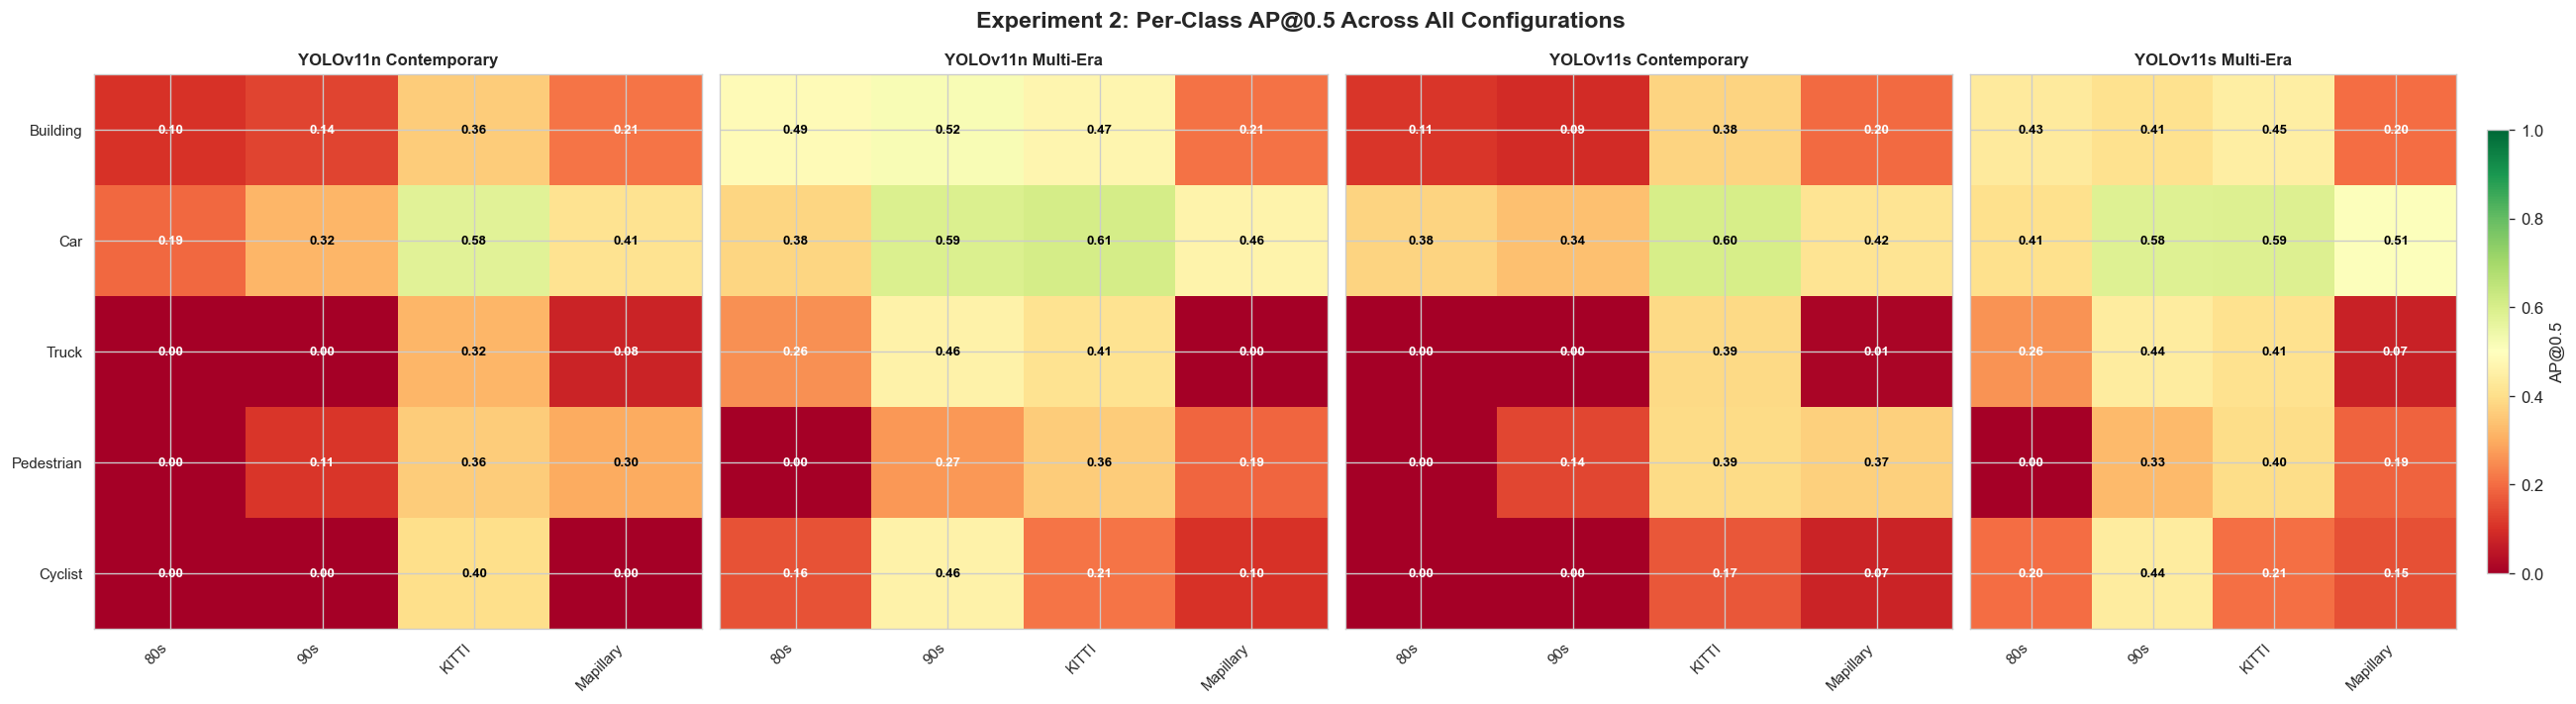

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
fig.suptitle('Experiment 2: Per-Class AP@0.5 Across All Configurations',
             fontsize=14, fontweight='bold')

for ax, (cfg_name, label) in zip(axes, CONFIG_LABELS.items()):
    matrix = np.array([
        [exp2_results[cfg_name][period]['per_class_AP50'][cls]
         for period in PERIODS]
        for cls in CLASSES
    ])
    im = ax.imshow(matrix, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(PERIODS)))
    ax.set_xticklabels(PERIODS, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES if ax == axes[0] else [], fontsize=9)
    ax.set_title(label, fontsize=10, fontweight='bold')
    for i in range(len(CLASSES)):
        for j in range(len(PERIODS)):
            ax.text(j, i, f'{matrix[i,j]:.2f}', ha='center', va='center',
                    fontsize=8, fontweight='bold',
                    color='white' if matrix[i,j] < 0.3 else 'black')

plt.colorbar(im, ax=axes[-1], label='AP@0.5', shrink=0.8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_heatmap_all_configs.png', dpi=200, bbox_inches='tight')
plt.show()

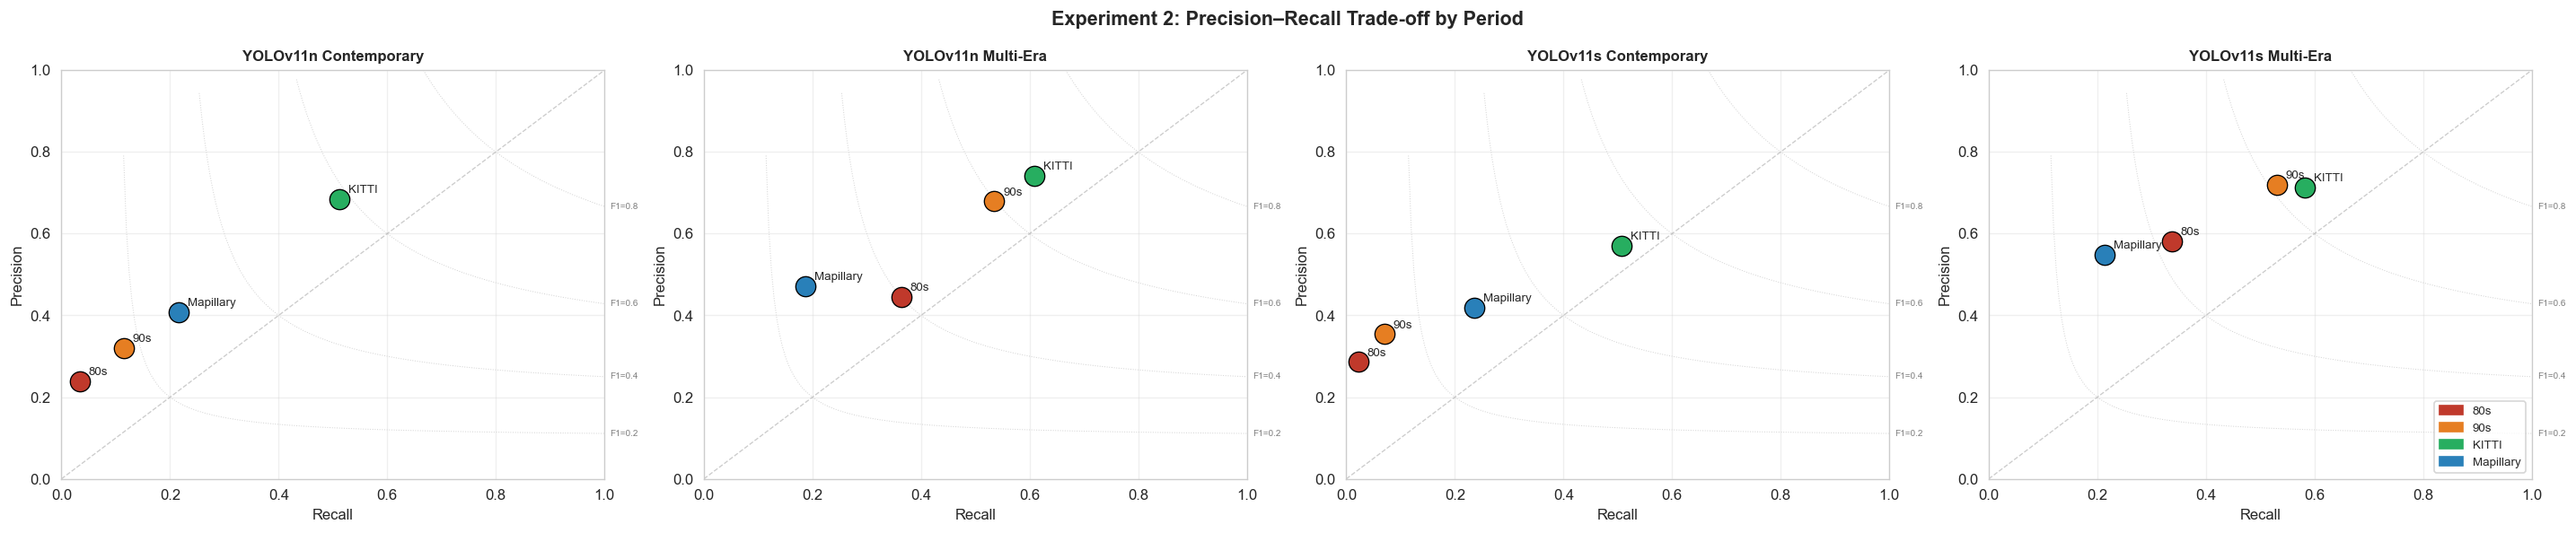

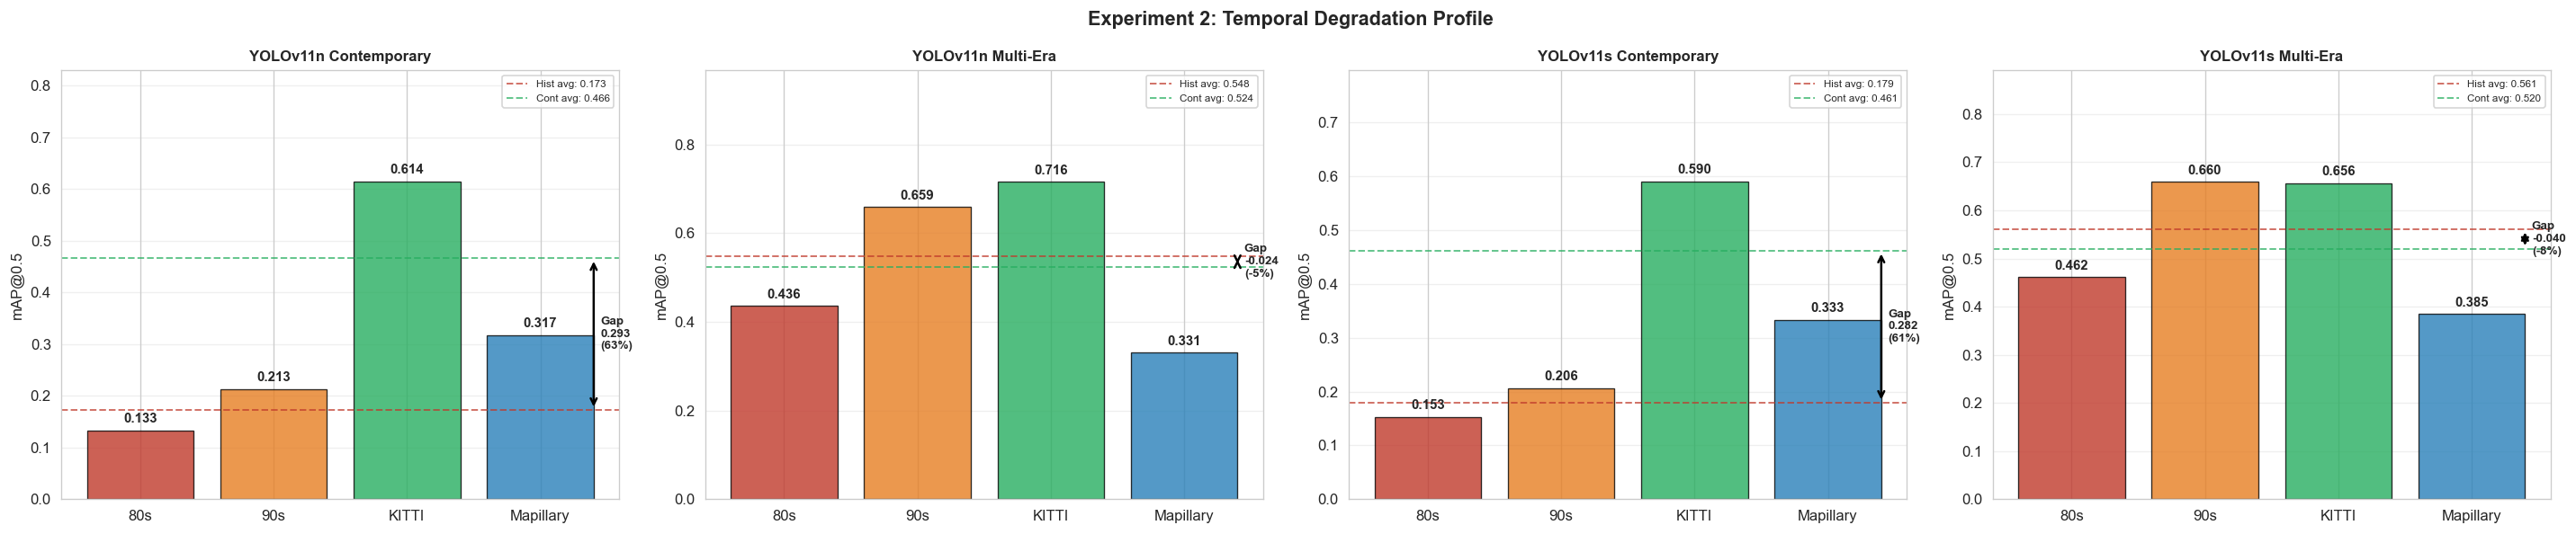

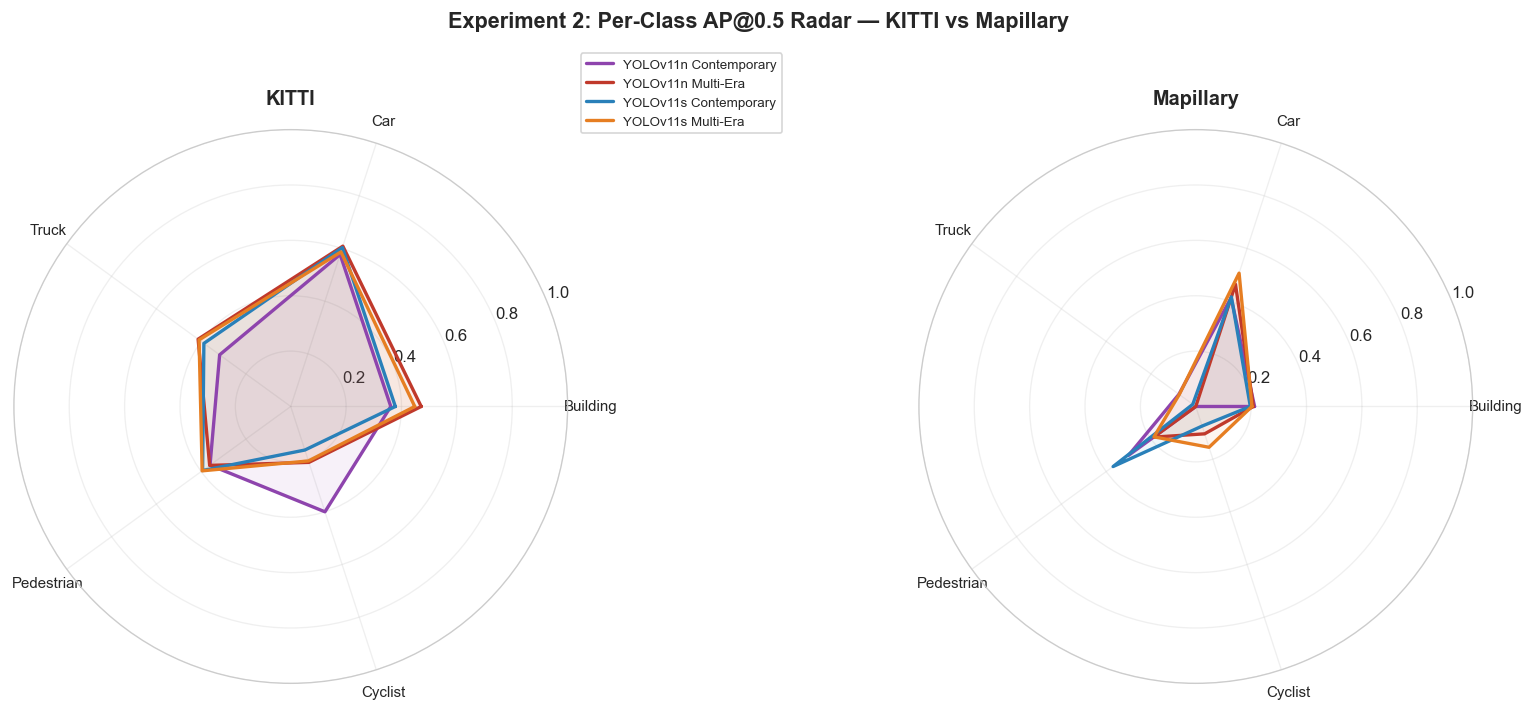

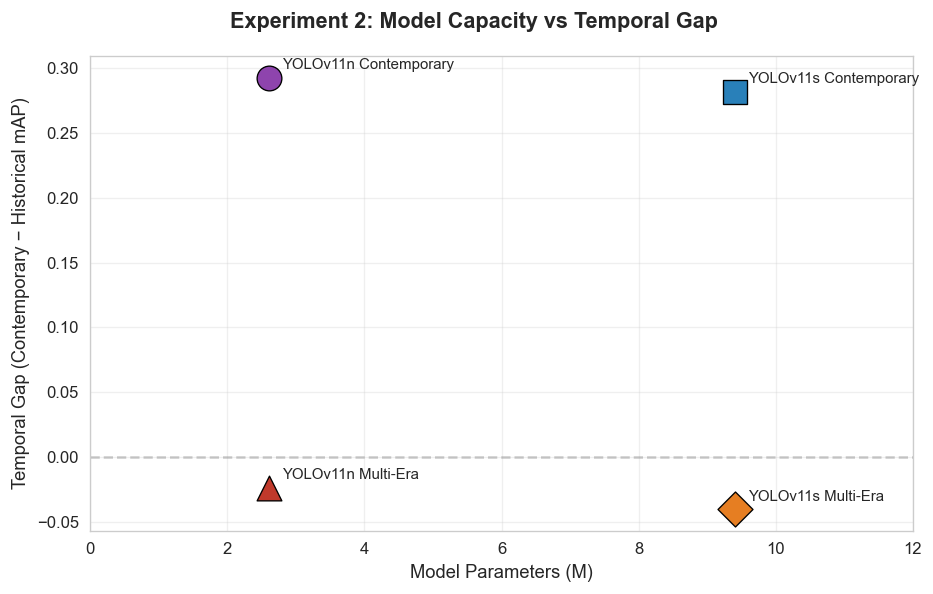

In [14]:
"""
Experiment 2: Diagnostic Visualisations — all four configurations
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# All four configs including nano multiera
ALL_CONFIGS = {
    'nano_contemporary' : {'label': 'YOLOv11n Contemporary', 'color': '#8E44AD'},
    'nano_multiera'     : {'label': 'YOLOv11n Multi-Era',    'color': '#C0392B'},
    'small_contemporary': {'label': 'YOLOv11s Contemporary', 'color': '#2980B9'},
    'small_multiera'    : {'label': 'YOLOv11s Multi-Era',    'color': '#E67E22'},
}

# 1. Precision-Recall scatter
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
fig.suptitle('Experiment 2: Precision–Recall Trade-off by Period',
             fontsize=13, fontweight='bold')

for ax, (cfg_name, cfg) in zip(axes, ALL_CONFIGS.items()):
    if cfg_name not in exp2_results:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                transform=ax.transAxes)
        continue
    for period in PERIODS:
        r = exp2_results[cfg_name][period]
        ax.scatter(r['recall'], r['precision'], s=180,
                   color=PERIOD_COLORS[period], zorder=3,
                   edgecolor='black', linewidth=0.8)
        ax.annotate(period, (r['recall'], r['precision']),
                    textcoords='offset points', xytext=(6, 4), fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.plot([0,1],[0,1], 'grey', linestyle='--', alpha=0.4, linewidth=0.8)
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_title(cfg['label'], fontweight='bold', fontsize=10)
    ax.grid(True, alpha=0.3)
    for f1 in [0.2, 0.4, 0.6, 0.8]:
        x = np.linspace(0.01, 1, 200)
        y = f1 * x / (2 * x - f1)
        mask = (y > 0) & (y <= 1)
        ax.plot(x[mask], y[mask], color='lightgrey', linewidth=0.6, linestyle=':')
        ax.text(x[mask][-1]+0.01, y[mask][-1], f'F1={f1}',
                fontsize=6, color='grey', va='center')

legend = [mpatches.Patch(color=PERIOD_COLORS[p], label=p) for p in PERIODS]
axes[-1].legend(handles=legend, fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_precision_recall_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

# 2. Temporal degradation profile
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
fig.suptitle('Experiment 2: Temporal Degradation Profile',
             fontsize=13, fontweight='bold')

for ax, (cfg_name, cfg) in zip(axes, ALL_CONFIGS.items()):
    if cfg_name not in exp2_results:
        continue
    r    = exp2_results[cfg_name]
    maps = [r[p]['mAP50'] for p in PERIODS]
    bars = ax.bar(PERIODS, maps,
                  color=[PERIOD_COLORS[p] for p in PERIODS],
                  alpha=0.8, edgecolor='black', linewidth=0.8)
    for bar, val in zip(bars, maps):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')

    hist_avg = np.mean([r[p]['mAP50'] for p in HIST_PERIODS])
    cont_avg = np.mean([r[p]['mAP50'] for p in CONT_PERIODS])
    gap      = cont_avg - hist_avg
    gap_pct  = gap / cont_avg * 100 if cont_avg > 0 else 0

    ax.axhline(hist_avg, color='#C0392B', linestyle='--', alpha=0.7,
               linewidth=1.2, label=f'Hist avg: {hist_avg:.3f}')
    ax.axhline(cont_avg, color='#27AE60', linestyle='--', alpha=0.7,
               linewidth=1.2, label=f'Cont avg: {cont_avg:.3f}')
    ax.annotate('', xy=(3.4, cont_avg), xytext=(3.4, hist_avg),
                arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
    ax.text(3.45, (cont_avg + hist_avg)/2,
            f'Gap\n{gap:.3f}\n({gap_pct:.0f}%)',
            va='center', fontsize=8, fontweight='bold')
    ax.set_ylim(0, max(maps) * 1.35)
    ax.set_ylabel('mAP@0.5')
    ax.set_title(cfg['label'], fontweight='bold', fontsize=10)
    ax.legend(fontsize=7)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_temporal_degradation_profile.png', dpi=200, bbox_inches='tight')
plt.show()

# 3. Per-class AP radar — KITTI and Mapillary
angles = np.linspace(0, 2*np.pi, N_CLASSES, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), subplot_kw=dict(polar=True))
fig.suptitle('Experiment 2: Per-Class AP@0.5 Radar — KITTI vs Mapillary',
             fontsize=13, fontweight='bold')

for ax, period in zip(axes, CONT_PERIODS):
    for cfg_name, cfg in ALL_CONFIGS.items():
        if cfg_name not in exp2_results:
            continue
        vals = [exp2_results[cfg_name][period].get(
                    'per_class_AP50', {}).get(c, 0) for c in CLASSES]
        vals += vals[:1]
        ax.plot(angles, vals, linewidth=2, label=cfg['label'], color=cfg['color'])
        ax.fill(angles, vals, alpha=0.07, color=cfg['color'])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(CLASSES, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_title(period, fontweight='bold', pad=15)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_radar_contemporary.png', dpi=200, bbox_inches='tight')
plt.show()

# 4. Model capacity vs temporal gap
fig, ax = plt.subplots(figsize=(8, 5))
fig.suptitle('Experiment 2: Model Capacity vs Temporal Gap',
             fontsize=13, fontweight='bold')

capacity = {
    'nano_contemporary' : 2.6,
    'nano_multiera'     : 2.6,
    'small_contemporary': 9.4,
    'small_multiera'    : 9.4,
}
markers = {
    'nano_contemporary' : 'o',
    'nano_multiera'     : '^',
    'small_contemporary': 's',
    'small_multiera'    : 'D',
}

for cfg_name, cfg in ALL_CONFIGS.items():
    if cfg_name not in exp2_results:
        continue
    r        = exp2_results[cfg_name]
    hist_avg = np.mean([r[p]['mAP50'] for p in HIST_PERIODS])
    cont_avg = np.mean([r[p]['mAP50'] for p in CONT_PERIODS])
    gap      = cont_avg - hist_avg
    ax.scatter(capacity[cfg_name], gap, s=220,
               color=cfg['color'], marker=markers[cfg_name],
               zorder=3, edgecolor='black', linewidth=0.8)
    ax.annotate(cfg['label'], (capacity[cfg_name], gap),
                textcoords='offset points', xytext=(8, 5), fontsize=9)

ax.set_xlabel('Model Parameters (M)', fontsize=11)
ax.set_ylabel('Temporal Gap (Contemporary − Historical mAP)', fontsize=11)
ax.set_xlim(0, 12)
ax.grid(True, alpha=0.3)
ax.axhline(0, color='grey', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_capacity_vs_gap.png', dpi=200, bbox_inches='tight')
plt.show()

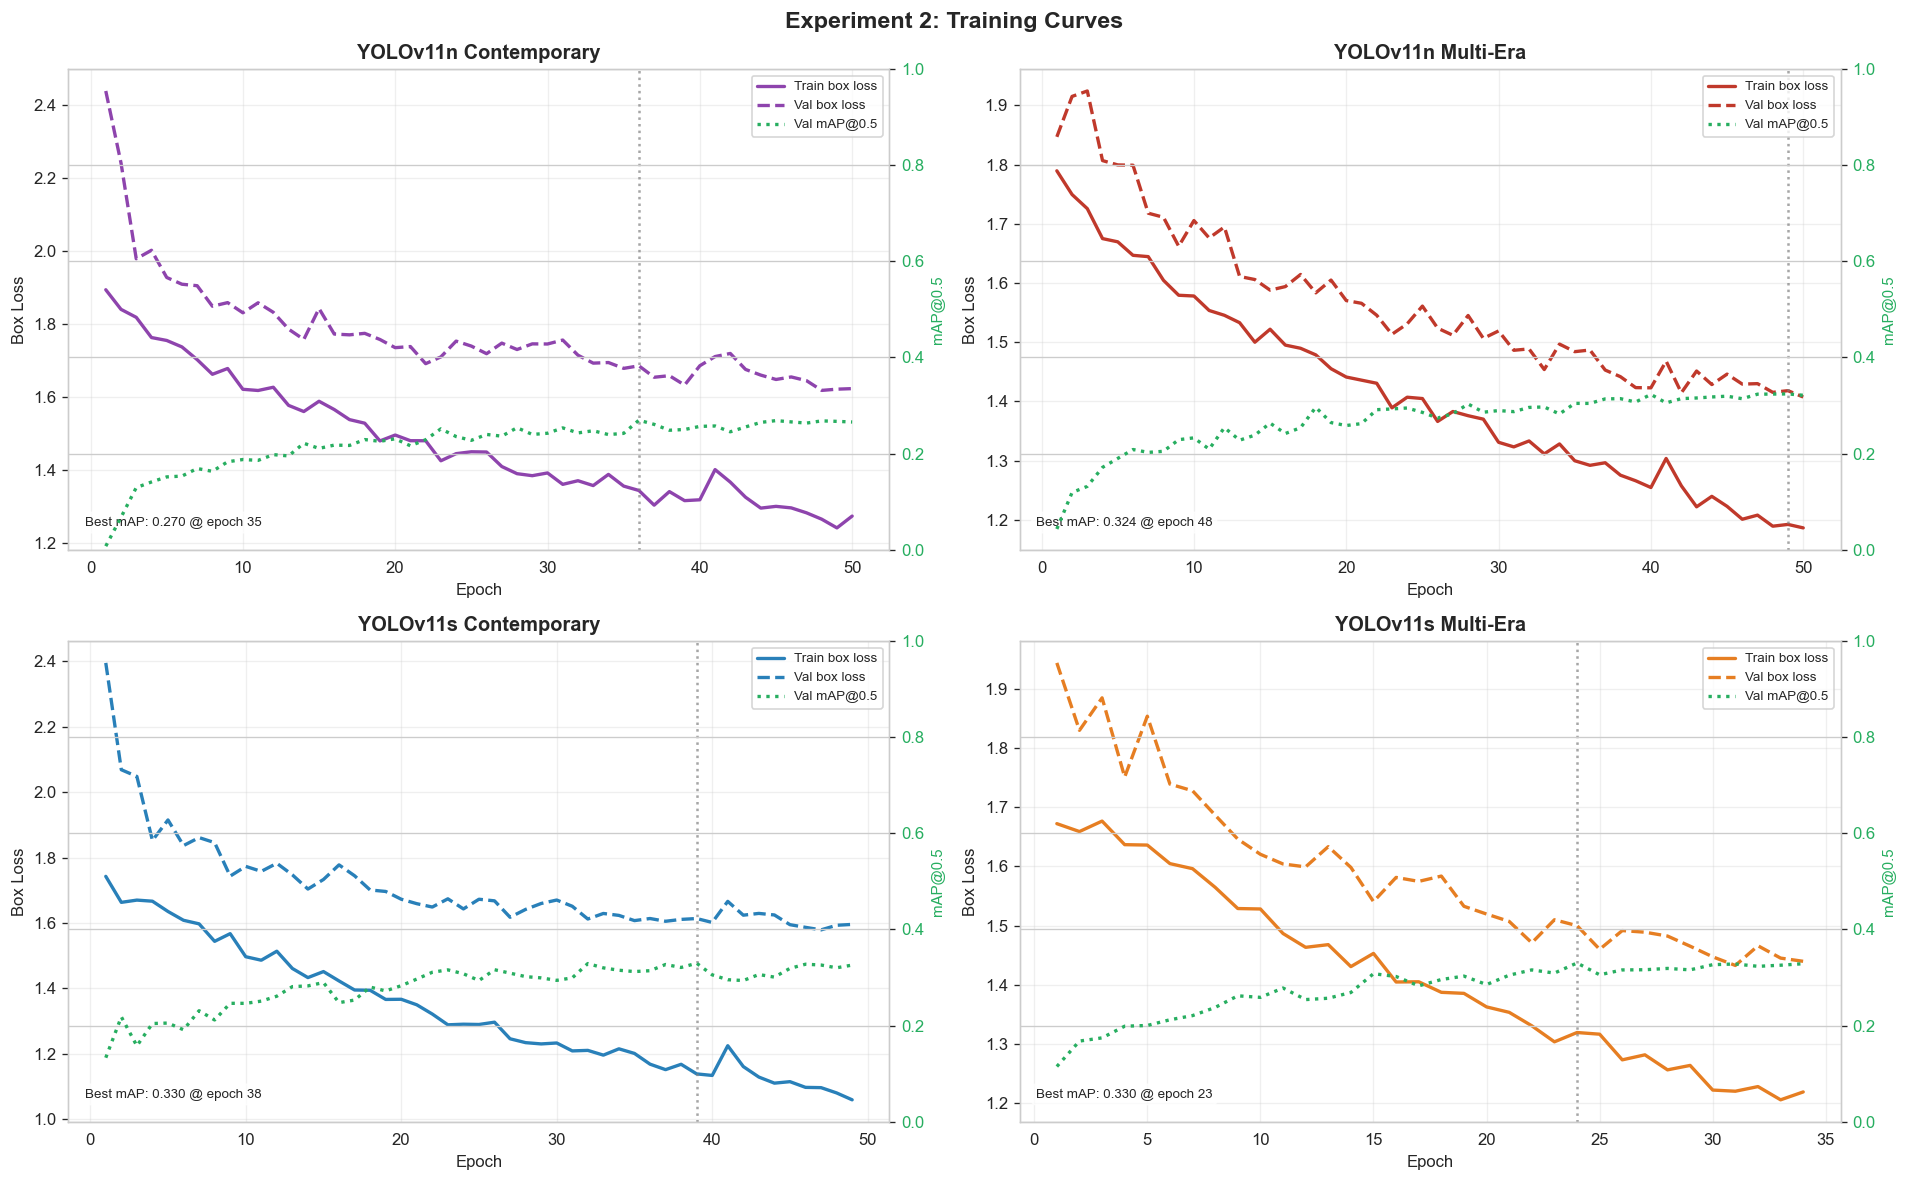


Model                       Final Train Loss  Final Val Loss   Best mAP@0.5   Best Epoch
---------------------------------------------------------------------------------------
YOLOv11n Contemporary                 1.2741          1.6230          0.270           35
YOLOv11n Multi-Era                    1.1863          1.4073          0.324           48
YOLOv11s Contemporary                 1.0594          1.5958          0.330           38
YOLOv11s Multi-Era                    1.2192          1.4398          0.330           23


In [15]:
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Experiment 2: Training Curves', fontsize=14, fontweight='bold')

CURVE_CONFIGS = {
    'nano_contemporary' : ('YOLOv11n Contemporary', '#8E44AD'),
    'nano_multiera'     : ('YOLOv11n Multi-Era',    '#C0392B'),
    'small_contemporary': ('YOLOv11s Contemporary', '#2980B9'),
    'small_multiera'    : ('YOLOv11s Multi-Era',    '#E67E22'),
}

for ax, (cfg_name, (label, color)) in zip(axes.flatten(), CURVE_CONFIGS.items()):
    csv_path = RESULTS_DIR / 'exp2' / cfg_name / 'results.csv'

    if not csv_path.exists():
        ax.text(0.5, 0.5, f'No results.csv\nfound for\n{label}',
                ha='center', va='center', transform=ax.transAxes, fontsize=10)
        ax.set_title(label, fontweight='bold')
        continue

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()  # YOLO sometimes adds whitespace

    epochs = df['epoch'] if 'epoch' in df.columns else range(len(df))

    # Plot train and val box loss
    if 'train/box_loss' in df.columns:
        ax.plot(epochs, df['train/box_loss'], label='Train box loss',
                color=color, linewidth=2)
    if 'val/box_loss' in df.columns:
        ax.plot(epochs, df['val/box_loss'], label='Val box loss',
                color=color, linewidth=2, linestyle='--')

    # Add val mAP on secondary axis
    ax2 = ax.twinx()
    if 'metrics/mAP50(B)' in df.columns:
        ax2.plot(epochs, df['metrics/mAP50(B)'], label='Val mAP@0.5',
                 color='#27AE60', linewidth=2, linestyle=':')
        ax2.set_ylabel('mAP@0.5', color='#27AE60', fontsize=9)
        ax2.tick_params(axis='y', labelcolor='#27AE60')
        ax2.set_ylim(0, 1)

    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Box Loss')
    ax.grid(True, alpha=0.3)

    # Combine legends
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper right')

    # Annotate best epoch
    if 'metrics/mAP50(B)' in df.columns:
        best_epoch = df['metrics/mAP50(B)'].idxmax()
        best_map   = df['metrics/mAP50(B)'].max()
        ax.axvline(x=epochs.iloc[best_epoch] if hasattr(epochs, 'iloc') else best_epoch,
                   color='grey', linestyle=':', alpha=0.7)
        ax.text(0.02, 0.05, f'Best mAP: {best_map:.3f} @ epoch {best_epoch}',
                transform=ax.transAxes, fontsize=8,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp2_training_curves.png', dpi=200, bbox_inches='tight')
plt.show()

# Print final epoch summary for each model
print(f"\n{'Model':<25} {'Final Train Loss':>18} {'Final Val Loss':>15} {'Best mAP@0.5':>14} {'Best Epoch':>12}")
print("-" * 87)

for cfg_name, (label, _) in CURVE_CONFIGS.items():
    csv_path = RESULTS_DIR / 'exp2' / cfg_name / 'results.csv'
    if not csv_path.exists():
        print(f"{label:<25} {'no results.csv':>18}")
        continue
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    train_loss = df['train/box_loss'].iloc[-1] if 'train/box_loss' in df.columns else float('nan')
    val_loss   = df['val/box_loss'].iloc[-1]   if 'val/box_loss'   in df.columns else float('nan')
    best_map   = df['metrics/mAP50(B)'].max()  if 'metrics/mAP50(B)' in df.columns else float('nan')
    best_epoch = df['metrics/mAP50(B)'].idxmax() if 'metrics/mAP50(B)' in df.columns else -1

    print(f"{label:<25} {train_loss:>18.4f} {val_loss:>15.4f} {best_map:>14.3f} {best_epoch:>12}")

### Training Curve Interpretation

**Note on val mAP scale:** All four models show val mAP@0.5 in the range 0.27–0.33 during training. This is expected, the validation split is a stratified 10% sample drawn from all four temporal periods, including 80s and 90s images where performance is inherently low. The mixed-era validation set depresses the reported val mAP relative to the per-period evaluation results reported in the comparison table above. Training health should be assessed from the loss curves rather than absolute val mAP values.

**Contemporary-only models** exhibit healthy, stable training in both cases. Train and val box loss decrease together without diverging, indicating no overfitting. YOLOv11s contemporary reaches its best checkpoint at epoch 38 out of 50, suggesting it was still improving near the end of training, a modest increase in epochs would likely yield marginal further gains, though the current results are sufficient for the research objectives.

**Multi-era models** show a divergence in training dynamics.

YOLOv11n multi-era trains for the full 50 epochs with val loss tracking train loss closely throughout, reaching its best checkpoint at epoch 48. The small parameter budget acts as an implicit regulariser: nano cannot overfit strongly to the contemporary domain even when contemporary images make up 50% of the training data. This constraint forces the model to learn more general cross-era features.

YOLOv11s multi-era shows early stopping at epoch 35 with the best checkpoint reached at epoch 23. Val loss diverges from train loss earlier than in any other configuration, a pattern consistent with overfitting. The small model has sufficient capacity to memorise contemporary visual features rapidly, which it does, but this specialisation comes at the cost of cross-era generalisation. By epoch 23 the model has already begun to overfit to the contemporary domain, and subsequent epochs do not improve generalisation. On held-out images this overfitting has no visible cost: the two multi-era models score alike on historical data (average 0.561 for small, 0.548 for nano). The earlier gap between them (0.436 against 0.510) came from scoring on images they had trained on.

## Model Selection

### Results summary

The four configurations reveal two clear patterns that directly inform which models carry forward.

**Contemporary-only models** produce a strong, interpretable temporal degradation signal. Both YOLOv11n and YOLOv11s contemporary achieve near-identical historical performance (0.173 and 0.179 respectively) despite a 3.6× difference in parameter count. This convergence is itself a finding: temporal degradation in historical urban imagery is not a capacity problem. A larger model does not help when the failure is driven by morphological shift in the visual world rather than insufficient representational power. Both models have healthy training curves with no overfitting, val loss tracks train loss throughout, and best checkpoints are reached late in training (epochs 35 and 38 respectively).

**Multi-era models** show a more complex picture and are ultimately not suitable as primary experimental models.

The nano multi-era model improves historical performance substantially (hist avg: 0.548 vs 0.173 for nano contemporary) while maintaining reasonable contemporary performance (cont avg: 0.524). Its training curve is stable with best epoch at 48 out of 50, val loss tracking train loss throughout. However, this model conflates two things: measuring temporal degradation and mitigating it. Training on historical data changes what the model knows, which is the opposite of the deployment scenario this study is examining.

The small multi-era model shows signs of overfitting during training. Best checkpoint is reached at epoch 23 out of 35, val loss diverges from train loss earlier than any other configuration, and early stopping triggered at epoch 35. On held-out images this has no visible cost: its historical average (0.561) is close to nano multi-era (0.548). It is a training-dynamics observation, not a measured penalty.

### Why multi-era models are excluded from subsequent experiments

Both multi-era models are excluded from Experiments 3, 4, Sub-question 3, and Sub-question 4 for the same core reason: they were trained on historical data, which means their behaviour on historical evaluation sets reflects learned historical features rather than the model's native temporal robustness. The degradation measurements produced by these models are not interpretable as temporal degradation, they are deployment-scenario artefacts. Reporting Sub-question 1 decomposition or Sub-question 4 vulnerability profiles using a model that has memorised 80s images would produce misleading conclusions.

Their results are reported here in Experiment 2 as a secondary finding: mixing eras recovers much of the historical gap (held-out mAP on the 1980s rises from about 0.15 to 0.44-0.46), but because they trained on historical data they cannot serve as a baseline for studying temporal degradation. They are revisited in Section 3.

### Selected models

Two models carry forward into all subsequent experiments: **YOLOv11s Contemporary** and **YOLOv11n Contemporary**.

This is a deliberate methodological choice. Running both models serves two purposes. First, it tests whether the temporal degradation findings are consistent across model sizes, if both models produce the same pattern of results, the conclusions are strengthened by cross-architecture replication rather than being specific to a single model. Second, the two models represent two points on the capacity spectrum (2.6M and 9.4M parameters). Their near-identical historical performance already suggests that degradation is data-driven rather than capacity-driven, but reporting both makes this argument explicit and measurable rather than assumed.

**YOLOv11s Contemporary** is the primary model for all reported findings. It was chosen as the primary model for being the larger of the two, and its held-out results (KITTI mAP@0.5 = 0.590; temporal gap 0.282, a 61% relative drop) are almost the same as the nano model's (KITTI 0.614; gap 0.293, 63%). All core hypothesis tests and sub-question answers are reported against this model.

**YOLOv11n Contemporary** is the secondary model used for robustness verification. If its results agree with the small contemporary model across experiments, this agreement confirms that the findings generalise beyond a single architecture. If they diverge, the difference will be noted and discussed in Section 3. Whether the pattern would hold for substantially larger models such as YOLOv11m or YOLOv11l remains an open question for future work, as the current study tests only the lower end of the YOLO11 capacity range.

The `MODEL_CONFIGS` dictionary below defines these two models and is used by all subsequent experiment cells.

In [16]:
MODEL_CONFIGS = {
    'small_contemporary': {
        'weights': RESULTS_DIR / 'exp2' / 'small_contemporary' / 'weights' / 'best.pt',
        'label'  : 'YOLOv11s Contemporary',
        'color'  : '#2980B9',
        'role'   : 'primary',
    },
    'nano_contemporary': {
        'weights': RESULTS_DIR / 'exp2' / 'nano_contemporary' / 'weights' / 'best.pt',
        'label'  : 'YOLOv11n Contemporary',
        'color'  : '#8E44AD',
        'role'   : 'robustness_check',
    }
}

## Experiment 3: Resolution Normalization


In [17]:
#  Experiment 3 setup
RESOLUTIONS   = [320, 640, 1280]
RES_KEYS      = ['320x320', '640x640', '1280x1280']
RES_LABELS    = ['320×320', '640×640', '1280×1280']
exp3_results_path = RESULTS_DIR / 'exp3_resolution_all_models_heldout.json'

def run_exp3(weights_path):
    """
    Evaluates a model at three resolutions across all four periods.
    Returns nested dict: {resolution_str: {period: {mAP50, precision, recall}}}
    """
    model   = YOLO(str(weights_path))
    results = {}

    for res in RESOLUTIONS:
        res_key = f'{res}x{res}'
        results[res_key] = {}
        print(f"  Resolution {res}x{res}:")

        for period in PERIODS:
            yaml_path = make_period_yaml(period)
            r = model.val(
                data    = str(yaml_path),
                imgsz   = res,
                conf    = CONF_THRES,
                device  = DEVICE,
                workers = 0,
                verbose = False,
                plots   = False,
            )
            results[res_key][period] = {
                'mAP50'    : float(r.box.map50),
                'precision': float(r.box.mp),
                'recall'   : float(r.box.mr),
                'per_class_AP50': {
                    cls: float(r.box.maps[i]) if i < len(r.box.maps) else 0.0
                    for i, cls in enumerate(CLASSES)
                },
            }
            yaml_path.unlink()
            print(f"    {period}: mAP50={r.box.map50:.3f}")

    return results


# Load from disk if already computed
if exp3_results_path.exists():
    with open(exp3_results_path) as f:
        exp3_results = json.load(f)
    print(f"Loaded existing Experiment 3 results from {exp3_results_path}")
else:
    exp3_results = {}
    for cfg_name, cfg in MODEL_CONFIGS.items():
        print(f"\n{'='*60}")
        print(f"Experiment 3 — {cfg['label']}")
        print('='*60)
        exp3_results[cfg_name] = run_exp3(cfg['weights'])

    with open(exp3_results_path, 'w') as f:
        json.dump(exp3_results, f, indent=2)
    print(f"\nResults saved → {exp3_results_path}")

# Also save a flat CSV for easy inspection
rows = []
for cfg_name, cfg in MODEL_CONFIGS.items():
    for rk in RES_KEYS:
        for period in PERIODS:
            r = exp3_results[cfg_name][rk][period]
            rows.append({
                'model'    : cfg['label'],
                'resolution': rk,
                'period'   : period,
                'mAP50'    : r['mAP50'],
                'precision': r['precision'],
                'recall'   : r['recall'],
            })

import pandas as pd
df_exp3 = pd.DataFrame(rows)
csv_path = RESULTS_DIR / 'exp3_resolution_all_models_heldout.csv'
df_exp3.to_csv(csv_path, index=False)
print(f"CSV saved → {csv_path}")


Experiment 3 — YOLOv11s Contemporary
  Resolution 320x320:
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11s summary (fused): 101 layers, 9,414,735 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 151.039.5 MB/s, size: 8.1 KB)
val: Scanning <project> 302 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 302/302  0.0s
val: <project> 1 duplicate labels removed
val: <project> 1 duplicate labels removed
val: <project> 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 14.7it/s 1.3s0.1s
                   all        302       1706      0.363     0.0467      0.204      0.102
Speed: 0.1ms preprocess, 2.2ms inference, 0.0ms loss, 0.5ms postprocess per image
    80s: mAP50=0.204
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
val: Fast image access

In [18]:
print(f"{'Model':<25} {'Period':<12} {'320×320':>10} {'640×640':>10} {'1280×1280':>12}")
print("-" * 75)

for cfg_name, cfg in MODEL_CONFIGS.items():
    r = exp3_results[cfg_name]

    for period in PERIODS:
        maps = [r[rk][period]['mAP50'] for rk in RES_KEYS]
        print(f"{cfg['label']:<25} {period:<12} "
              f"{maps[0]:>10.3f} {maps[1]:>10.3f} {maps[2]:>12.3f}")
    print()

# Temporal gap analysis per model
print(f"\n{'='*85}")
print("Temporal Gap Analysis (Contemporary avg − Historical avg)")
print('='*85)
print(f"{'Model':<25} {'Gap@320':>10} {'Gap@640':>10} {'Gap@1280':>12} {'Gap Closure':>12}")
print("-" * 85)

for cfg_name, cfg in MODEL_CONFIGS.items():
    r = exp3_results[cfg_name]
    gaps = []
    for rk in RES_KEYS:
        hist = np.mean([r[rk][p]['mAP50'] for p in HIST_PERIODS])
        cont = np.mean([r[rk][p]['mAP50'] for p in CONT_PERIODS])
        gaps.append(cont - hist)

    closure = ((gaps[0] - gaps[2]) / gaps[0] * 100) if gaps[0] > 0 else 0
    direction = 'narrowed' if closure > 0 else 'widened'
    print(f"{cfg['label']:<25} {gaps[0]:>10.3f} {gaps[1]:>10.3f} "
          f"{gaps[2]:>12.3f} {abs(closure):>10.1f}% {direction}")

Model                     Period          320×320    640×640    1280×1280
---------------------------------------------------------------------------
YOLOv11s Contemporary     80s               0.204      0.153        0.013
YOLOv11s Contemporary     90s               0.238      0.206        0.158
YOLOv11s Contemporary     KITTI             0.440      0.590        0.475
YOLOv11s Contemporary     Mapillary         0.285      0.333        0.342

YOLOv11n Contemporary     80s               0.144      0.133        0.088
YOLOv11n Contemporary     90s               0.208      0.213        0.153
YOLOv11n Contemporary     KITTI             0.411      0.614        0.506
YOLOv11n Contemporary     Mapillary         0.237      0.317        0.354


Temporal Gap Analysis (Contemporary avg − Historical avg)
Model                        Gap@320    Gap@640     Gap@1280  Gap Closure
-------------------------------------------------------------------------------------
YOLOv11s Contemporary          0.142 

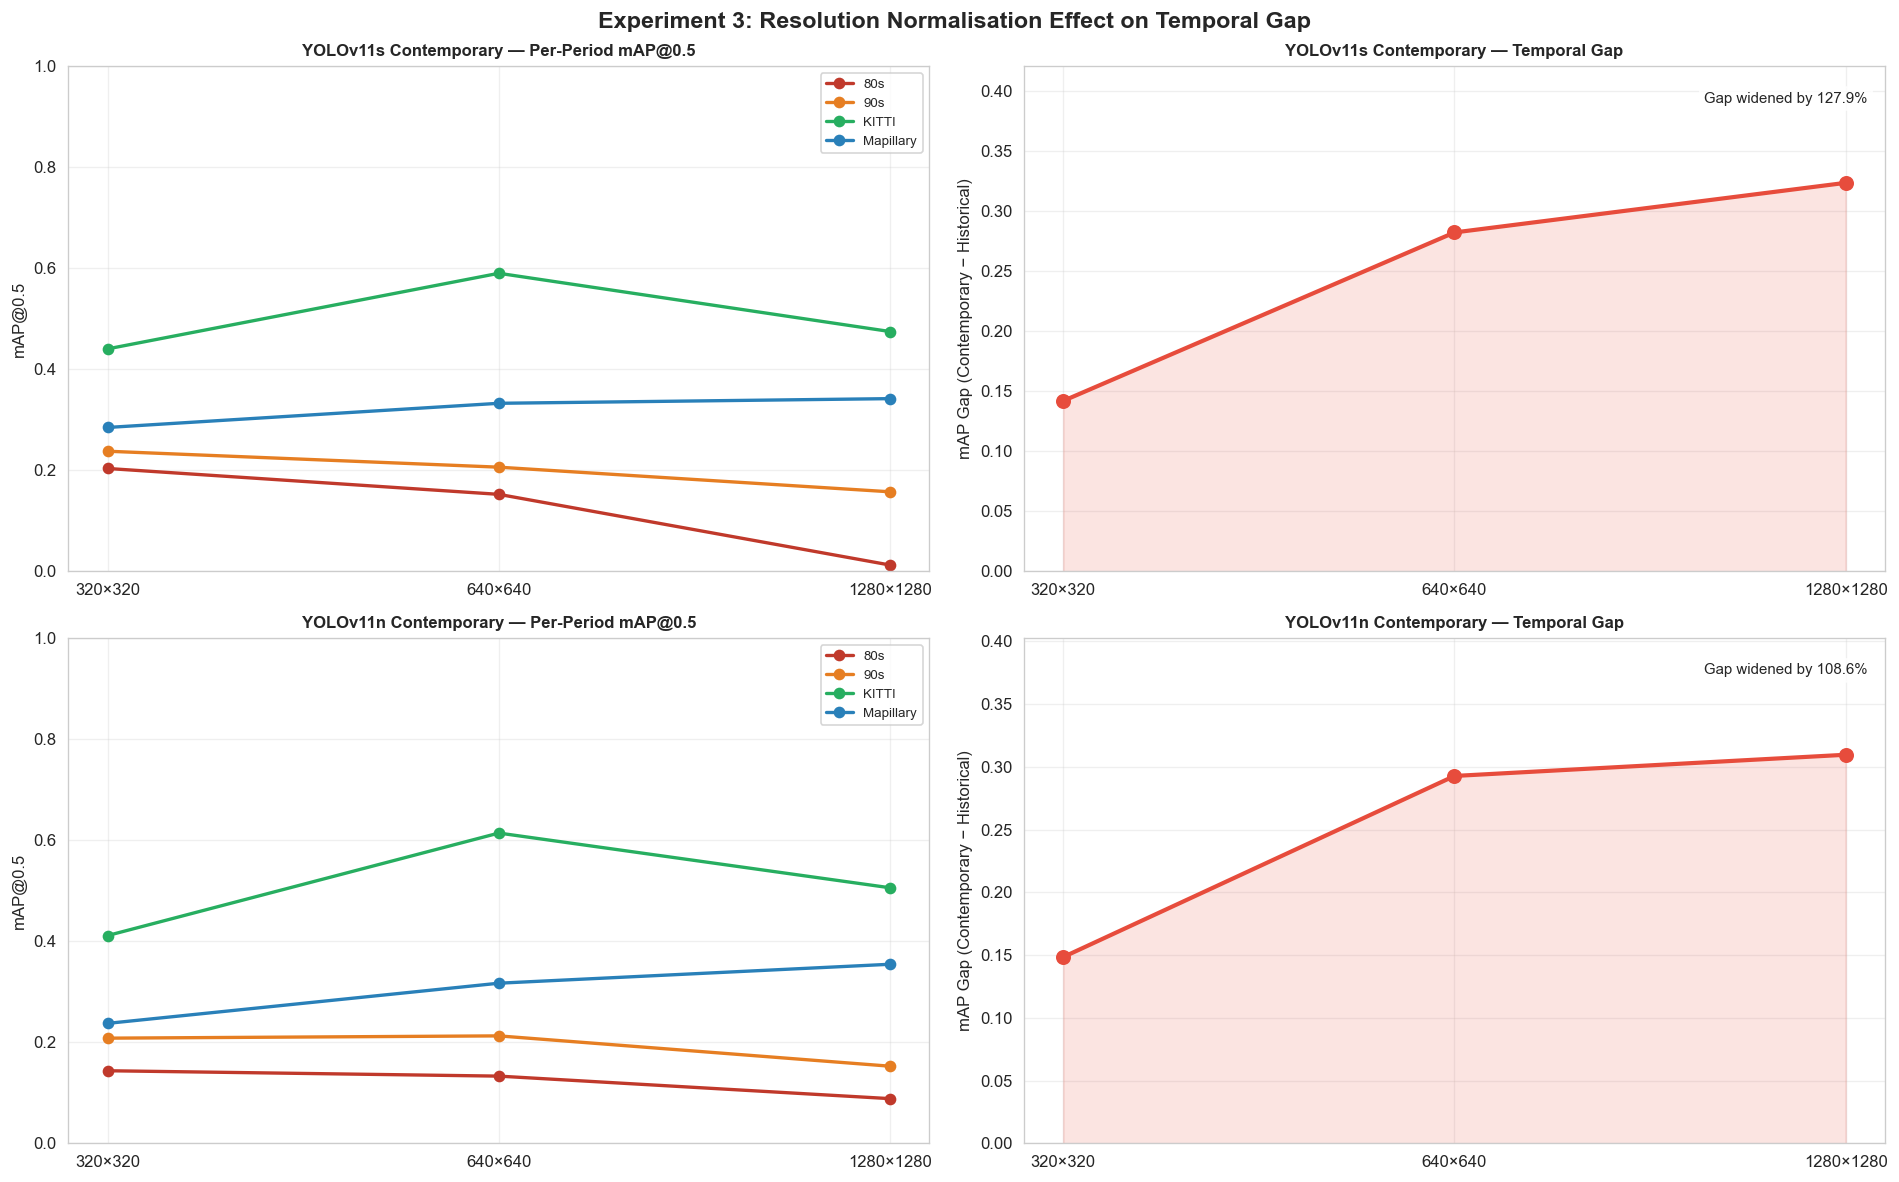

Figure saved → <project>


In [19]:
fig, axes = plt.subplots(len(MODEL_CONFIGS), 2, figsize=(16, 5 * len(MODEL_CONFIGS)))
fig.suptitle('Experiment 3: Resolution Normalisation Effect on Temporal Gap',
             fontsize=14, fontweight='bold')

for row_idx, (cfg_name, cfg) in enumerate(MODEL_CONFIGS.items()):
    r = exp3_results[cfg_name]

    # Left: mAP per period across resolutions
    ax1 = axes[row_idx, 0]
    for period in PERIODS:
        maps = [r[rk][period]['mAP50'] for rk in RES_KEYS]
        ax1.plot(RES_LABELS, maps, marker='o', linewidth=2,
                 label=period, color=PERIOD_COLORS[period])
    ax1.set_title(f"{cfg['label']} — Per-Period mAP@0.5", fontsize=10, fontweight='bold')
    ax1.set_ylabel('mAP@0.5')
    ax1.set_ylim(0, 1)
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)

    # Right: temporal gap across resolutions
    ax2 = axes[row_idx, 1]
    gaps = []
    for rk in RES_KEYS:
        hist = np.mean([r[rk][p]['mAP50'] for p in HIST_PERIODS])
        cont = np.mean([r[rk][p]['mAP50'] for p in CONT_PERIODS])
        gaps.append(cont - hist)

    color = '#E74C3C' if gaps[-1] > gaps[0] else '#27AE60'
    ax2.plot(RES_LABELS, gaps, marker='o', linewidth=2.5,
             color=color, markersize=8)
    ax2.fill_between(range(len(RES_LABELS)), gaps, alpha=0.15, color=color)
    ax2.set_title(f"{cfg['label']} — Temporal Gap", fontsize=10, fontweight='bold')
    ax2.set_ylabel('mAP Gap (Contemporary − Historical)')
    ax2.set_ylim(0, max(gaps) * 1.3)
    ax2.grid(True, alpha=0.3)

    closure = ((gaps[0] - gaps[2]) / gaps[0] * 100) if gaps[0] > 0 else 0
    direction = 'widened' if closure < 0 else 'narrowed'
    ax2.text(0.98, 0.95, f'Gap {direction} by {abs(closure):.1f}%',
             transform=ax2.transAxes, ha='right', va='top', fontsize=9,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp3_resolution_all_models.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'exp3_resolution_all_models.png'}")

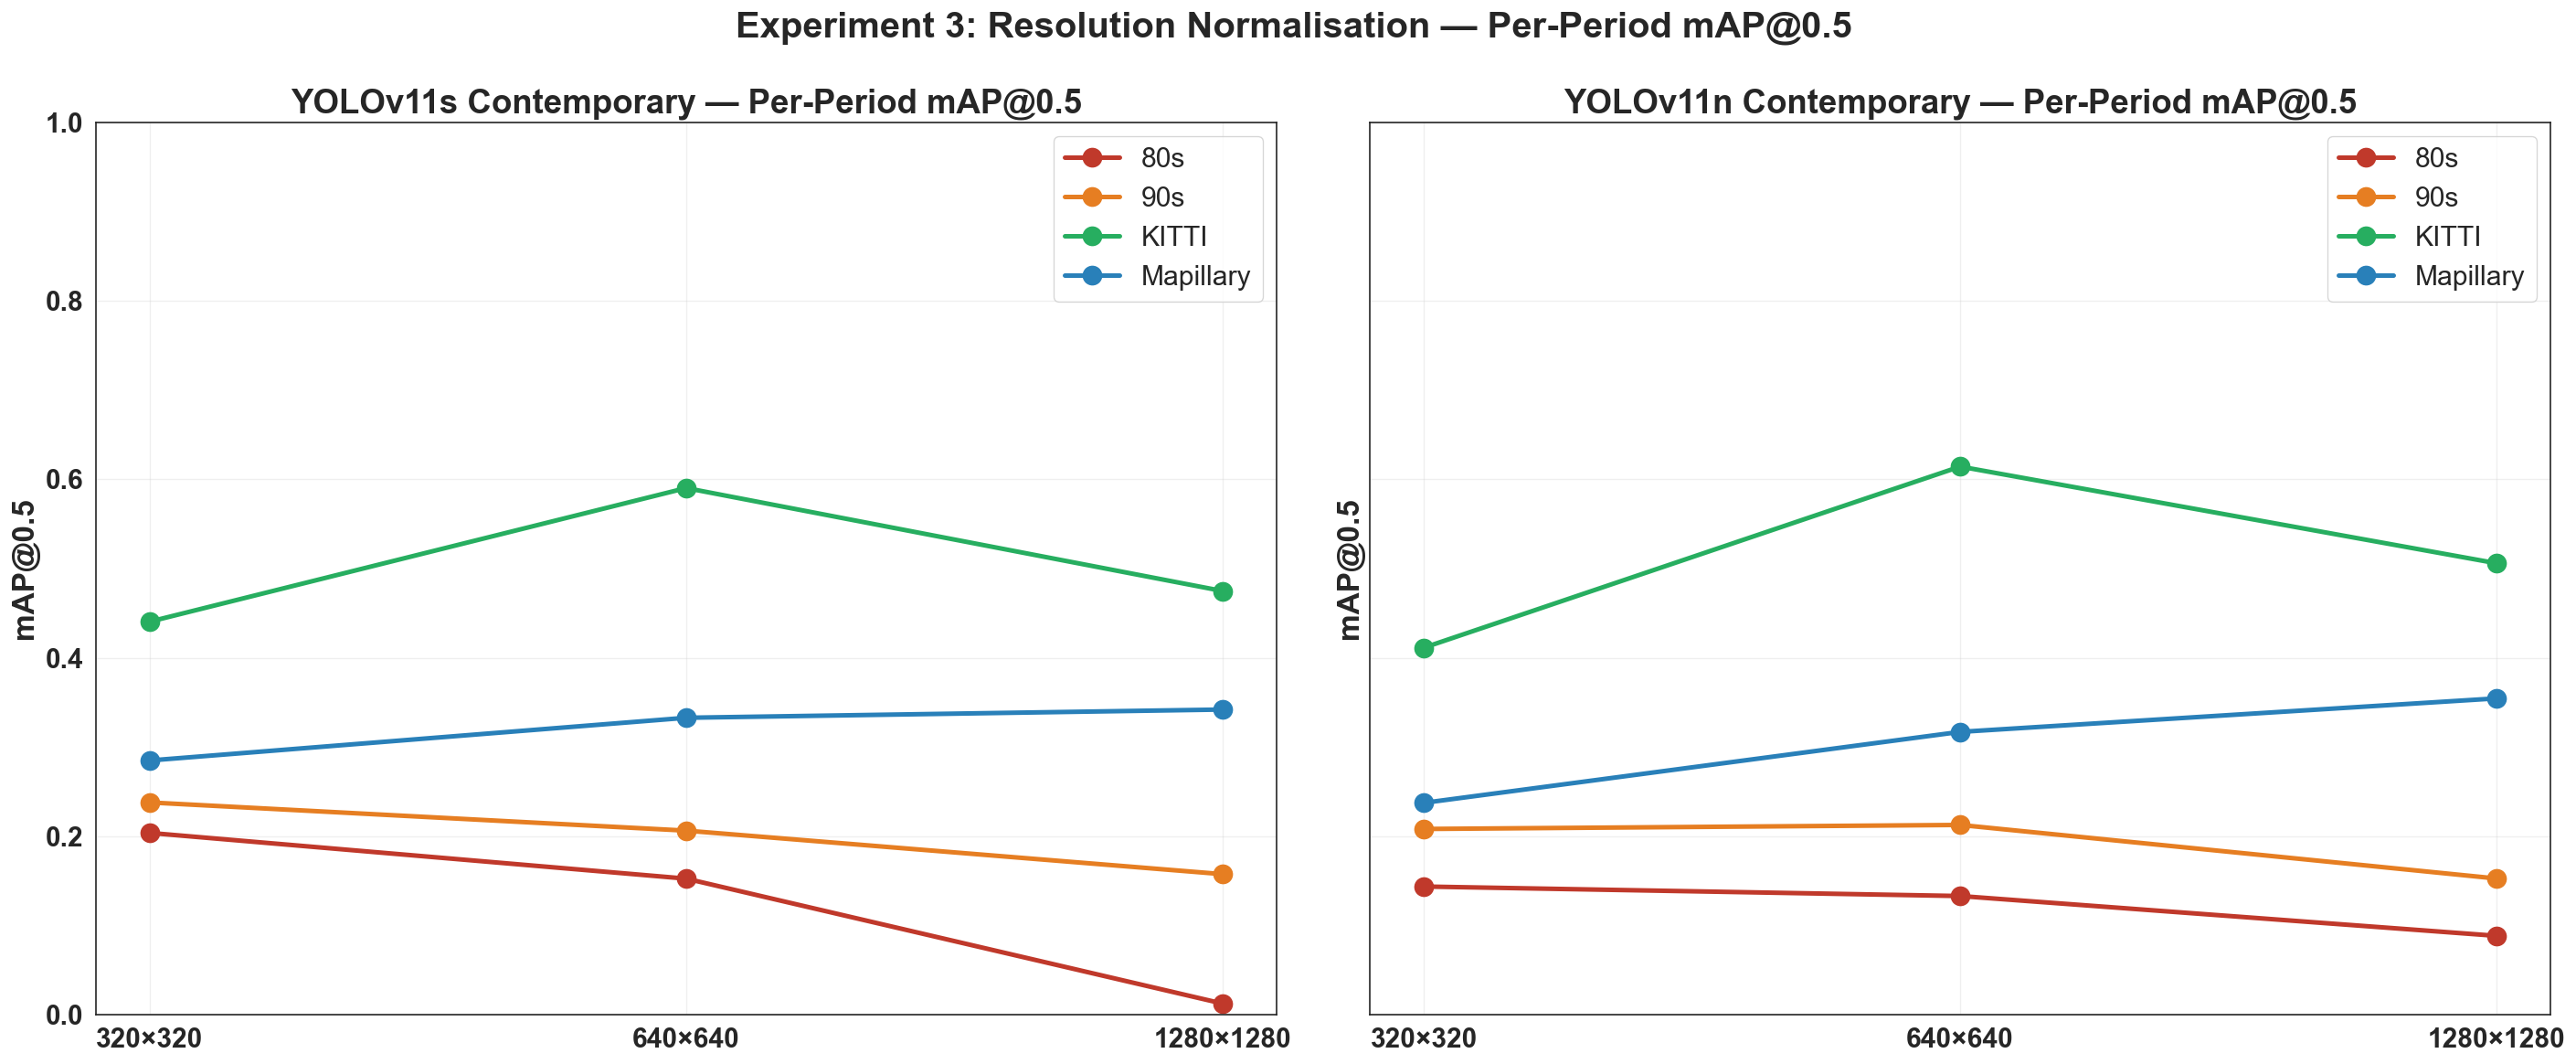

Figure saved → <project>


In [20]:
import seaborn as sns

sns.set_theme(style="white", context="paper", font="sans-serif")
plt.rcParams.update({
    'font.sans-serif'  : ['Arial', 'DejaVu Sans', 'Liberation Sans', 'sans-serif'],
    'font.size'        : 20,
    'axes.titlesize'   : 22,
    'axes.labelsize'   : 20,
    'xtick.labelsize'  : 18,
    'ytick.labelsize'  : 18,
    'legend.fontsize'  : 18,
    'figure.titlesize' : 24,
})

fig, axes = plt.subplots(1, len(MODEL_CONFIGS),
                         figsize=(12 * len(MODEL_CONFIGS), 10), sharey=True)
fig.suptitle('Experiment 3: Resolution Normalisation — Per-Period mAP@0.5',
             fontweight='bold')

for row_idx, (cfg_name, cfg) in enumerate(MODEL_CONFIGS.items()):
    r   = exp3_results[cfg_name]
    ax1 = axes[row_idx] if len(MODEL_CONFIGS) > 1 else axes

    for period in PERIODS:
        maps = [r[rk][period]['mAP50'] for rk in RES_KEYS]
        ax1.plot(RES_LABELS, maps, marker='o', linewidth=3, markersize=12,
                 label=period, color=PERIOD_COLORS[period])

    ax1.set_title(f"{cfg['label']} — Per-Period mAP@0.5", fontweight='bold')
    ax1.set_ylabel('mAP@0.5', fontweight='bold')
    ax1.set_ylim(0, 1)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_fontweight('bold')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp3_per_period_only.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'exp3_per_period_only.png'}")

In [21]:
"""
Visual comparison: Ground truth vs model detections
across all periods and resolutions for the primary model.
Shows 1 sample image per period at all 3 resolutions.
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random
from pathlib import Path
from ultralytics import YOLO

RESOLUTIONS   = [320, 640, 1280]
SAMPLE_SEED   = 56
N_SAMPLES     = 2   # images per period

CLASS_COLORS_BGR = {
    0: (0,   100, 255),   # Building  — orange
    1: (0,   200,   0),   # Car       — green
    2: (255,  60,  60),   # Truck     — blue
    3: (0,   220, 220),   # Pedestrian— yellow
    4: (200,   0, 200),   # Cyclist   — purple
}

random.seed(SAMPLE_SEED)

# Use primary model at 640 baseline, then compare resolutions
primary_weights = MODEL_CONFIGS['small_contemporary']['weights']
model = YOLO(str(primary_weights))


def draw_boxes(img_bgr, boxes, color_map, thickness=1, label_scale=0.35):
    """Draw bounding boxes on a copy of the image."""
    out = img_bgr.copy()
    h, w = out.shape[:2]
    for cid, cx, cy, bw, bh in boxes:
        x1 = int((cx - bw/2) * w)
        y1 = int((cy - bh/2) * h)
        x2 = int((cx + bw/2) * w)
        y2 = int((cy + bh/2) * h)
        color = color_map.get(int(cid), (128,128,128))
        cv2.rectangle(out, (x1,y1), (x2,y2), color, thickness)
        label = CLASSES[int(cid)] if int(cid) < len(CLASSES) else str(int(cid))
        cv2.putText(out, label, (x1, max(y1-2, 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, label_scale, color, 1)
    return out


def get_gt_boxes(label_path):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                boxes.append(tuple(map(float, parts[:5])))
    return boxes


def get_pred_boxes(img_bgr, resolution):
    """Run inference at given resolution, return list of (cid, cx, cy, w, h) normalised."""
    h, w = img_bgr.shape[:2]
    results = model.predict(
        source  = img_bgr,
        imgsz   = resolution,
        conf    = CONF_THRES,
        device  = DEVICE,
        verbose = False,
    )
    boxes = []
    if results[0].boxes is not None:
        for box in results[0].boxes:
            x1,y1,x2,y2 = box.xyxy[0].cpu().numpy()
            cid = int(box.cls[0].cpu())
            cx  = ((x1+x2)/2) / w
            cy  = ((y1+y2)/2) / h
            bw  = (x2-x1) / w
            bh  = (y2-y1) / h
            boxes.append((cid, cx, cy, bw, bh))
    return boxes


# Main loop: one figure per period
for period in PERIODS:
    images_dir = EVAL_DATA / period / 'images'
    labels_dir = EVAL_DATA / period / 'labels'

    all_images = sorted(list(images_dir.glob('*.jpg')) +
                        list(images_dir.glob('*.png')))

    # Pick images that have at least one annotation
    annotated = [p for p in all_images
                 if (labels_dir / f"{p.stem}.txt").exists()
                 and (labels_dir / f"{p.stem}.txt").read_text().strip()]
    sample = random.sample(annotated, min(N_SAMPLES, len(annotated)))

    n_rows = len(sample)
    n_cols = 1 + len(RESOLUTIONS)   # GT + one col per resolution

    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(4 * n_cols, 3.5 * n_rows))
    fig.suptitle(f'{period} — Ground Truth vs Detections at Multiple Resolutions',
                 fontsize=12, fontweight='bold')

    if n_rows == 1:
        axes = axes.reshape(1, -1)

    col_titles = ['Ground Truth'] + [f'{r}×{r}' for r in RESOLUTIONS]
    for col_idx, title in enumerate(col_titles):
        axes[0, col_idx].set_title(title, fontsize=10, fontweight='bold',
                                   color='#2C3E50')

    for row_idx, img_path in enumerate(sample):
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue

        gt_boxes = get_gt_boxes(labels_dir / f"{img_path.stem}.txt")

        # Column 0: ground truth
        gt_img = draw_boxes(img_bgr, gt_boxes, CLASS_COLORS_BGR,
                            thickness=max(1, img_bgr.shape[1]//150))
        axes[row_idx, 0].imshow(cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB))
        axes[row_idx, 0].set_ylabel(img_path.name[:25], fontsize=7)
        axes[row_idx, 0].tick_params(left=False, bottom=False,
                                      labelleft=False, labelbottom=False)
        # Green border for GT
        for spine in axes[row_idx, 0].spines.values():
            spine.set_edgecolor('#27AE60'); spine.set_linewidth(2)

        # Columns 1-3: predictions at each resolution
        for col_idx, res in enumerate(RESOLUTIONS, start=1):
            pred_boxes = get_pred_boxes(img_bgr, res)
            pred_img   = draw_boxes(img_bgr, pred_boxes, CLASS_COLORS_BGR,
                                    thickness=max(1, img_bgr.shape[1]//150))
            ax = axes[row_idx, col_idx]
            ax.imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
            ax.tick_params(left=False, bottom=False,
                           labelleft=False, labelbottom=False)

            n_gt   = len(gt_boxes)
            n_pred = len(pred_boxes)
            match_color = ('#27AE60' if n_pred >= n_gt * 0.7
                           else '#E67E22' if n_pred > 0
                           else '#E74C3C')
            ax.set_xlabel(f'GT:{n_gt}  Pred:{n_pred}',
                          fontsize=8, color=match_color, fontweight='bold')
            for spine in ax.spines.values():
                spine.set_edgecolor(match_color); spine.set_linewidth(2)

    # Legend
    legend_patches = [
        mpatches.Patch(color=tuple(c/255 for c in cv2.cvtColor(
            np.uint8([[v]]), cv2.COLOR_BGR2RGB)[0,0]), label=CLASSES[k])
        for k, v in CLASS_COLORS_BGR.items()
    ]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=N_CLASSES, fontsize=8,
               bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    save_path = RESULTS_DIR / f'detection_samples_{period}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {save_path}")

Saved → <project>


Saved → <project>


Saved → <project>


Saved → <project>


## Visual Inspection: Ground Truth vs Detections Across Resolutions

The sample images above illustrate the quantitative findings from Experiment 3 with concrete visual evidence. Each row shows a ground truth annotation alongside model predictions at 320×320, 640×640, and 1280×1280.

### 80s NYC

The model almost entirely fails to detect cars in the 80s images across all three resolutions. In the first sample (S13-1), ground truth contains 10 objects including multiple cars and buildings, yet predictions at 320×320 and 640×640 return only 1 detection each, a single building. At 1280×1280, the count rises to 2, but the detections are large imprecise building boxes that do not align with the annotated objects. The cars visible in the street are completely missed at every resolution. In the second sample (brook-14), the model fires on buildings at 320×320 with 4 predictions but loses them at higher resolutions, returning 0 detections at 1280×1280 despite 6 ground truth objects being present. This is the upscaling artefact described in Experiment 3. The 150×150 source image contains no additional information at higher resolution, and the interpolated pixels actively confuse the detector.

### 90s LA/London

The greyscale confound is immediately considered a possibility. The first sample (media-45) shows 18 ground truth objects including cars, pedestrians, a cyclist, and buildings across a busy aerial street scene. The model returns 0 predictions at all three resolutions. Perhaps complete absence of colour information renders the image unrecognisable to a model trained on colour contemporary data. The second sample (media-68) shows partial recovery with 4 predictions at 320×320 and 640×640 out of 22 ground truth objects, primarily buildings. At 1280×1280 only 1 building is detected. The greyscale condition compounds the resolution upscaling problem, making the 90s dataset the most challenging across all conditions.

### KITTI and Mapillary

The KITTI and Mapillary samples in the gallery are drawn from the held-out test images, so they differ from the samples in the first version of this analysis. The quantitative results are the reference here. KITTI mAP@0.5 for YOLOv11s is 0.440 at 320x320, 0.590 at 640x640 and 0.475 at 1280x1280, while Mapillary is 0.285, 0.333 and 0.342. Modern data therefore stays strong across resolutions, peaking at 640x640 for KITTI and rising slightly for Mapillary.

### Cross-period visual summary

The visual comparison confirms the quantitative pattern from Experiment 3. Contemporary datasets (KITTI, Mapillary) stay strong or improve as resolution increases, while historical datasets (80s, 90s) show deteriorating performance. The 80s case visually demonstrates the upscaling artefact most clearly: the pixelated source image at 1280×1280 produces large, poorly localised building predictions while missing all cars entirely. The model is responding to interpolated block patterns rather than genuine object features.

## Experiment 3: Interpretation

### Sub-question 2 Answer: Resolution normalisation does not reduce the temporal gap

Across both model configurations, increasing inference resolution from 320×320 to 1280×1280 widened the temporal gap rather than closing it. Hypothesis 3 is refuted.

| Model | Gap@320 | Gap@640 | Gap@1280 | Direction |
|---|---|---|---|---|
| YOLOv11s Contemporary | 0.142 | 0.282 | 0.323 | +127.9% wider |
| YOLOv11n Contemporary | 0.148 | 0.293 | 0.310 | +108.6% wider |

The two models show almost identical directional behaviour, which is the first cross-model consistency finding in this study. Both produce a gap that grows at every step, most sharply from 320×320 to 640×640, confirming that the widening effect is not an artefact of a single architecture.

The mechanism is asymmetric: higher resolution consistently benefits contemporary data while harming historical data. KITTI peaks at 640×640 for both models (0.590 and 0.614 respectively), while 80s performance collapses at 1280×1280 to near-zero (0.013 for small, 0.088 for nano). The 80s dataset was digitised at approximately 150×150 pixels. Upscaling these images to 1280×1280 through bicubic interpolation produces no additional real visual content, only interpolated noise. The model receives a physically larger image but one that is informationally identical to the original, and the interpolation artefacts introduce texture patterns that diverge further from the model's training distribution.

The nano model shows a smaller gap widening (108.6% vs 127.9%) at the highest resolution, which is consistent with nano's lower capacity making it less sensitive to the fine-grained texture differences introduced by upscaling. This is a minor difference and does not alter the core finding.

### 640×640 is the appropriate inference resolution

For both models, 640×640 produces the best KITTI performance and is the resolution used during training. Part of the widening from 320×320 comes from modern data improving and part from historical data falling. It is also the resolution used during training, making it the natural operating point. All other experiments in this study use 640×640.

### Convergence with Experiment 4

This result converges with the morphological decomposition from Experiment 4. If image quality were the primary driver of temporal degradation, resolution normalisation would be expected to help by equalising the visual detail available to the model across periods. It does not. This is consistent with the hypothesis that morphological change is the dominant factor: a model failing primarily because objects looked different in the 1980s cannot recover that information by processing the same images at a higher resolution.

## Experiment 4: Controlled Image Degradation

In [22]:
import cv2, shutil
from tqdm import tqdm

#  Paths
MAPILLARY_SRC  = EVAL_DATA / 'Mapillary'
AGED_DIR       = DATA_DIR / 'mapillary_aged_heldout'
exp4_results_path = RESULTS_DIR / 'exp4_degradation_all_models_heldout.json'

# OpenCV-only aging pipeline
def apply_aging(image):
    """
    Applies calibrated degradation to simulate 1980s photographic quality.
    Targets: contrast ~47.4, brightness ~119.0 (matched to historical dataset).
    Sharpness cannot be fully replicated — acknowledged limitation.

    Pipeline: Gaussian noise → saturation reduction →
              Gaussian blur → JPEG compression → contrast/brightness normalisation
    """
    # 1. Gaussian noise (film grain), sigma=10
    noise = np.random.normal(0, 10, image.shape).astype(np.float32)
    aged  = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    # 2. Reduce saturation by 10%
    hsv = cv2.cvtColor(aged, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:, :, 1] = np.clip(hsv[:, :, 1] * 0.9, 0, 255)
    aged = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # 3. Gaussian blur 3×3
    aged = cv2.GaussianBlur(aged, (3, 3), 0)

    # 4. JPEG compression at quality=85
    _, buf = cv2.imencode('.jpg', aged, [cv2.IMWRITE_JPEG_QUALITY, 85])
    aged   = cv2.imdecode(buf, cv2.IMREAD_COLOR)

    # 5. Normalise contrast and brightness to historical targets
    target_contrast   = 47.4
    target_brightness = 119.0
    current_mean = aged.mean()
    current_std  = aged.std()
    if current_std > 0:
        aged = ((aged.astype(np.float32) - current_mean)
                * (target_contrast / current_std)
                + target_brightness)
    aged = np.clip(aged, 0, 255).astype(np.uint8)
    return aged


def create_aged_dataset():
    """Ages all Mapillary images and copies labels unchanged."""
    aged_imgs = AGED_DIR / 'images'
    aged_lbls = AGED_DIR / 'labels'
    aged_imgs.mkdir(parents=True, exist_ok=True)
    aged_lbls.mkdir(parents=True, exist_ok=True)

    images = sorted(list((MAPILLARY_SRC / 'images').glob('*.jpg')) +
                    list((MAPILLARY_SRC / 'images').glob('*.png')))
    metrics = {'contrast': [], 'brightness': [], 'sharpness': []}

    for img_path in tqdm(images, desc='Aging Mapillary images'):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        aged = apply_aging(img)
        cv2.imwrite(str(aged_imgs / img_path.name), aged)

        # Track quality metrics
        gray = cv2.cvtColor(aged, cv2.COLOR_BGR2GRAY)
        metrics['contrast'].append(float(gray.std()))
        metrics['brightness'].append(float(gray.mean()))
        metrics['sharpness'].append(float(cv2.Laplacian(gray, cv2.CV_64F).var()))

        # Copy label unchanged
        lbl = MAPILLARY_SRC / 'labels' / f"{img_path.stem}.txt"
        if lbl.exists():
            shutil.copy(lbl, aged_lbls / lbl.name)

    print(f"\nAged dataset quality metrics:")
    for k, v in metrics.items():
        print(f"  {k.capitalize():12}: {np.mean(v):.1f}")

    return metrics


# Evaluate one model on three conditions
def evaluate_exp4(weights_path):
    """
    Evaluates a model on:
      1. Original Mapillary  (contemporary quality, contemporary objects)
      2. Aged Mapillary      (historical quality, contemporary objects)
      3. Actual 80s          (historical quality, historical objects)

    The drop from 1→2 isolates image quality degradation.
    The drop from 2→3 isolates morphological change.
    """
    model = YOLO(str(weights_path))
    results = {}

    conditions = {
        'original_mapillary': MAPILLARY_SRC,
        'aged_mapillary'    : AGED_DIR,
        'actual_80s'        : EVAL_DATA / '80s',
    }

    for cond_name, data_path in conditions.items():
        yaml_path = data_path / '_exp4.yaml'
        yaml.dump({
            'path' : str(data_path.absolute()),
            'train': 'images', 'val': 'images', 'test': 'images',
            'nc'   : N_CLASSES,
            'names': {i: c for i, c in enumerate(CLASSES)},
        }, open(yaml_path, 'w'))

        r = model.val(
            data    = str(yaml_path),
            imgsz   = IMG_SIZE,
            conf    = CONF_THRES,
            device  = DEVICE,
            workers = 0,
            verbose = False,
            plots   = False,
        )
        results[cond_name] = {
            'mAP50'    : float(r.box.map50),
            'precision': float(r.box.mp),
            'recall'   : float(r.box.mr),
        }
        yaml_path.unlink()
        print(f"  {cond_name}: mAP50={r.box.map50:.3f}")

    # Compute decomposition
    orig  = results['original_mapillary']['mAP50']
    aged  = results['aged_mapillary']['mAP50']
    actual = results['actual_80s']['mAP50']
    total = orig - actual
    quality_drop  = orig - aged
    morphology_drop = aged - actual

    results['decomposition'] = {
        'total_drop'      : round(total, 4),
        'quality_drop'    : round(quality_drop, 4),
        'morphology_drop' : round(morphology_drop, 4),
        'quality_pct'     : round(quality_drop / total * 100, 1) if total > 0 else 0,
        'morphology_pct'  : round(morphology_drop / total * 100, 1) if total > 0 else 0,
    }
    return results


# Run
if exp4_results_path.exists():
    with open(exp4_results_path) as f:
        exp4_results = json.load(f)
    print(f"Loaded existing Experiment 4 results from {exp4_results_path}")
else:
    # Create aged dataset once
    if not (AGED_DIR / 'images').exists():
        print("Step 1: Creating aged Mapillary dataset...")
        aging_metrics = create_aged_dataset()
    else:
        print("Aged dataset already exists — skipping creation.")

    exp4_results = {}
    for cfg_name, cfg in MODEL_CONFIGS.items():
        print(f"\n{'='*60}")
        print(f"Experiment 4 — {cfg['label']}")
        print('='*60)
        exp4_results[cfg_name] = evaluate_exp4(cfg['weights'])

    with open(exp4_results_path, 'w') as f:
        json.dump(exp4_results, f, indent=2)
    print(f"\nResults saved → {exp4_results_path}")

Step 1: Creating aged Mapillary dataset...


Aging Mapillary images: 100%|██████████| 30/30 [00:31<00:00,  1.04s/it]


Aged dataset quality metrics:
  Contrast    : 45.9
  Brightness  : 118.5
  Sharpness   : 38.2

Experiment 4 — YOLOv11s Contemporary
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11s summary (fused): 101 layers, 9,414,735 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 4213.7601.7 MB/s, size: 975.4 KB)
val: Scanning <project> 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30  0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3it/s 0.9s1.5s
                   all         30        587      0.419      0.237      0.333      0.214
Speed: 0.5ms preprocess, 5.4ms inference, 0.0ms loss, 0.6ms postprocess per image
  original_mapillary: mAP50=0.333
Ultralytics 8.4.24  Python-3.11.9 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 3349.0319.8 MB/s, size: 1734.9 KB)
val: Scanning <project> 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 2.7Kit/s 0.0s
val: New cache created: <project>
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s1.8s
                   all         30        587      0.423       0.19      0.313      0.201
Speed: 0.2ms preprocess, 5.8ms inference, 0.0ms loss, 0.7ms postprocess per image
  aged_mapillary: mAP50=0.313
Ultralytics 8.

In [23]:
print(f"{'Model':<25} {'Condition':<22} {'mAP50':>8} {'Precision':>10} {'Recall':>8}")
print("-" * 78)

for cfg_name, cfg in MODEL_CONFIGS.items():
    r = exp4_results[cfg_name]
    for cond in ['original_mapillary', 'aged_mapillary', 'actual_80s']:
        label = cond.replace('_', ' ').title()
        m = r[cond]
        print(f"{cfg['label']:<25} {label:<22} "
              f"{m['mAP50']:>8.3f} {m['precision']:>10.3f} {m['recall']:>8.3f}")
    print()

print(f"\n{'='*78}")
print("SQ1: Degradation Decomposition")
print(f"{'='*78}")
print(f"{'Model':<25} {'Total Drop':>12} {'Quality':>10} {'Quality%':>10} "
      f"{'Morphology':>12} {'Morphology%':>12}")
print("-" * 83)

for cfg_name, cfg in MODEL_CONFIGS.items():
    d = exp4_results[cfg_name]['decomposition']
    print(f"{cfg['label']:<25} {d['total_drop']:>12.3f} "
          f"{d['quality_drop']:>10.3f} {d['quality_pct']:>9.1f}% "
          f"{d['morphology_drop']:>12.3f} {d['morphology_pct']:>11.1f}%")

Model                     Condition                 mAP50  Precision   Recall
------------------------------------------------------------------------------
YOLOv11s Contemporary     Original Mapillary        0.333      0.419    0.237
YOLOv11s Contemporary     Aged Mapillary            0.313      0.423    0.190
YOLOv11s Contemporary     Actual 80S                0.153      0.286    0.022

YOLOv11n Contemporary     Original Mapillary        0.317      0.408    0.215
YOLOv11n Contemporary     Aged Mapillary            0.276      0.360    0.182
YOLOv11n Contemporary     Actual 80S                0.133      0.240    0.034


SQ1: Degradation Decomposition
Model                       Total Drop    Quality   Quality%   Morphology  Morphology%
-----------------------------------------------------------------------------------
YOLOv11s Contemporary            0.180      0.020      11.2%        0.160        88.8%
YOLOv11n Contemporary            0.184      0.041      22.4%        0.143        77

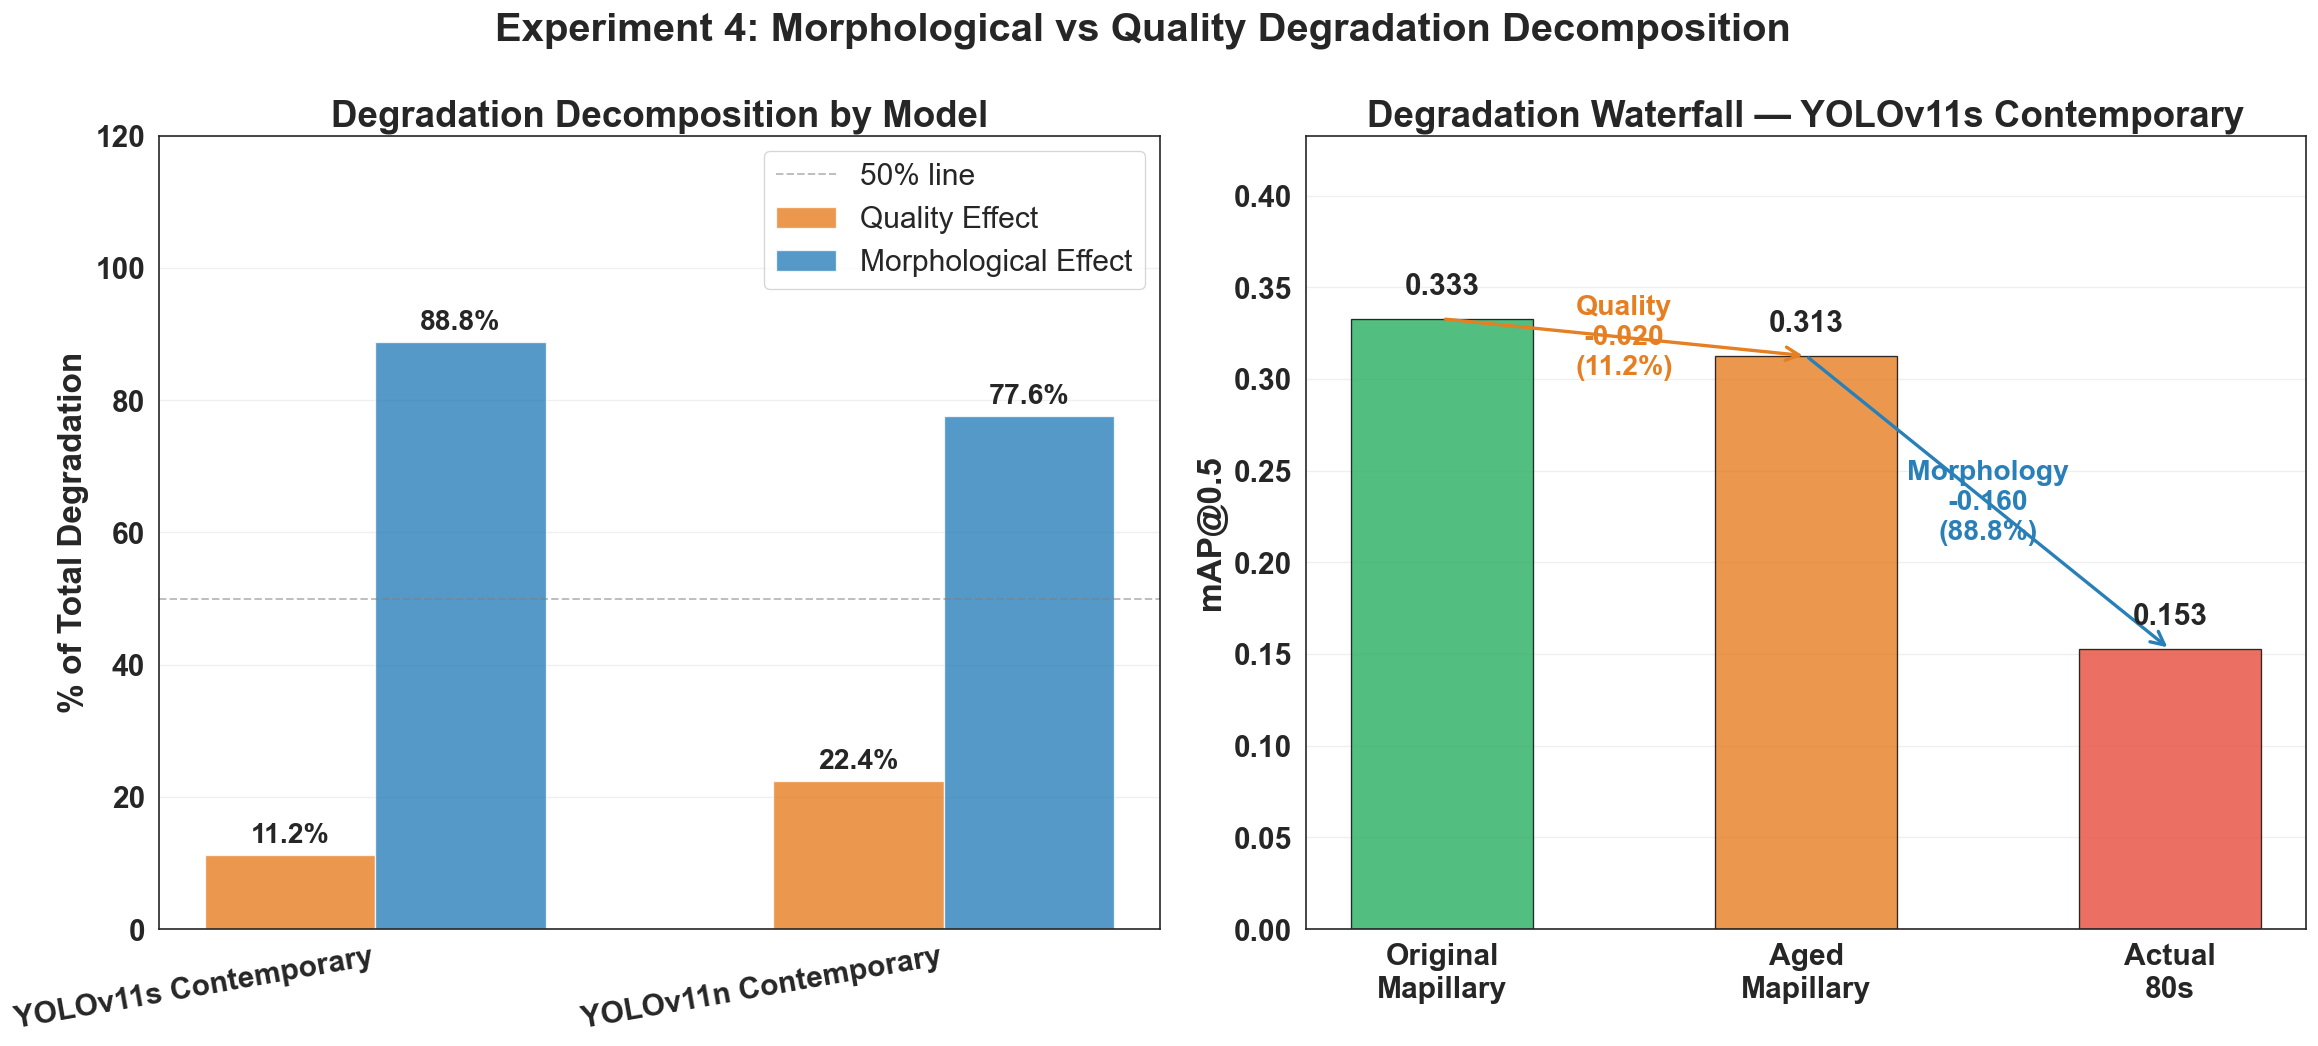

Figure saved → <project>


In [24]:
import seaborn as sns

sns.set_theme(style="white", context="paper", font="sans-serif")
plt.rcParams.update({
    'font.sans-serif'  : ['Arial', 'DejaVu Sans', 'Liberation Sans', 'sans-serif'],
    'font.size'        : 20,
    'axes.titlesize'   : 22,
    'axes.labelsize'   : 20,
    'xtick.labelsize'  : 18,
    'ytick.labelsize'  : 18,
    'legend.fontsize'  : 18,
    'figure.titlesize' : 24,
})

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
fig.suptitle('Experiment 4: Morphological vs Quality Degradation Decomposition',
             fontweight='bold')

# Left: decomposition bars
ax1 = axes[0]

contemporary_models = {k: v for k, v in MODEL_CONFIGS.items()
                       if 'multiera' not in k}

n_models = len(contemporary_models)
x        = np.arange(n_models)
width    = 0.3

quality_vals    = [exp4_results[c]['decomposition']['quality_pct']
                   for c in contemporary_models]
morphology_vals = [exp4_results[c]['decomposition']['morphology_pct']
                   for c in contemporary_models]
labels          = [cfg['label'] for cfg in contemporary_models.values()]

b1 = ax1.bar(x - width/2, quality_vals,    width, label='Quality Effect',
             color='#E67E22', alpha=0.8)
b2 = ax1.bar(x + width/2, morphology_vals, width, label='Morphological Effect',
             color='#2980B9', alpha=0.8)

for bar, val in zip(b1, quality_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=17, fontweight='bold')
for bar, val in zip(b2, morphology_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=17, fontweight='bold')

ax1.axhline(50, color='grey', linestyle='--', alpha=0.5, label='50% line')
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=10, ha='right')
ax1.set_ylabel('% of Total Degradation', fontweight='bold')
ax1.set_ylim(0, 120)
ax1.set_title('Degradation Decomposition by Model', fontweight='bold')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_fontweight('bold')

# Right: waterfall chart
ax2 = axes[1]
primary = 'small_contemporary'
r = exp4_results[primary]

orig   = r['original_mapillary']['mAP50']
aged   = r['aged_mapillary']['mAP50']
actual = r['actual_80s']['mAP50']
d      = r['decomposition']

conditions = ['Original\nMapillary', 'Aged\nMapillary', 'Actual\n80s']
values     = [orig, aged, actual]
colors     = ['#27AE60', '#E67E22', '#E74C3C']

bars = ax2.bar(conditions, values, color=colors, alpha=0.8, width=0.5, edgecolor='black')

ax2.annotate('', xy=(1, aged), xytext=(0, orig),
             arrowprops=dict(arrowstyle='->', color='#E67E22', lw=2))
ax2.annotate('', xy=(2, actual), xytext=(1, aged),
             arrowprops=dict(arrowstyle='->', color='#2980B9', lw=2))

ax2.text(0.5, (orig + aged)/2, f"Quality\n-{d['quality_drop']:.3f}\n({d['quality_pct']:.1f}%)",
         ha='center', va='center', fontsize=17, color='#E67E22', fontweight='bold')
ax2.text(1.5, (aged + actual)/2, f"Morphology\n-{d['morphology_drop']:.3f}\n({d['morphology_pct']:.1f}%)",
         ha='center', va='center', fontsize=17, color='#2980B9', fontweight='bold')

for bar, val in zip(bars, values):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=18, fontweight='bold')

ax2.set_ylabel('mAP@0.5', fontweight='bold')
ax2.set_ylim(0, orig * 1.3)
ax2.set_title(f'Degradation Waterfall — {MODEL_CONFIGS[primary]["label"]}',
              fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
for label in ax2.get_xticklabels() + ax2.get_yticklabels():
    label.set_fontweight('bold')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp4_degradation_all_models.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'exp4_degradation_all_models.png'}")

In [25]:
"""
Experiment 4: Visual comparisons
1. Original vs Aged side-by-side with detections
2. Aged Mapillary vs Actual 80s comparison (same class objects)
3. Failure mode gallery — objects the model misses after aging
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random
from pathlib import Path
from ultralytics import YOLO

SAMPLE_SEED = 99
N_SAMPLES   = 3
random.seed(SAMPLE_SEED)

CLASS_COLORS_BGR = {
    0: (0,   100, 255),
    1: (0,   200,   0),
    2: (255,  60,  60),
    3: (0,   220, 220),
    4: (200,   0, 200),
}

primary_weights = MODEL_CONFIGS['small_contemporary']['weights']
model = YOLO(str(primary_weights))

MAPILLARY_ORIG = EVAL_DATA / 'Mapillary'
MAPILLARY_AGED = DATA_DIR / 'mapillary_aged_heldout'
ACTUAL_80S     = EVAL_DATA / '80s'


def run_inference(img_bgr, resolution=640):
    h, w = img_bgr.shape[:2]
    results = model.predict(
        source=img_bgr, imgsz=resolution,
        conf=CONF_THRES, device=DEVICE,
        verbose=False,
    )
    boxes = []
    if results[0].boxes is not None:
        for box in results[0].boxes:
            x1,y1,x2,y2 = box.xyxy[0].cpu().numpy()
            cid  = int(box.cls[0].cpu())
            conf = float(box.conf[0].cpu())
            cx = ((x1+x2)/2)/w; cy = ((y1+y2)/2)/h
            bw = (x2-x1)/w;     bh = (y2-y1)/h
            boxes.append((cid, cx, cy, bw, bh, conf))
    return boxes


def draw_boxes_conf(img_bgr, boxes, thickness=3, scale=0.45):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    for item in boxes:
        cid, cx, cy, bw, bh = item[:5]
        conf = item[5] if len(item) > 5 else None
        x1 = int((cx-bw/2)*w); y1 = int((cy-bh/2)*h)
        x2 = int((cx+bw/2)*w); y2 = int((cy+bh/2)*h)
        color = CLASS_COLORS_BGR.get(int(cid), (128,128,128))
        cv2.rectangle(out, (x1,y1), (x2,y2), color, thickness)
        label = CLASSES[int(cid)] if int(cid) < len(CLASSES) else str(int(cid))
        if conf is not None:
            label += f' {conf:.2f}'
        cv2.putText(out, label, (x1, max(y1-3, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, scale, color, 1)
    return out


def draw_gt(img_bgr, label_path, thickness=3, scale=0.45):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                boxes.append(tuple(map(float, parts[:5])))
    return draw_boxes_conf(img_bgr, boxes, thickness, scale), len(boxes)


legend_patches = [
    mpatches.Patch(
        color=tuple(c/255 for c in cv2.cvtColor(
            np.uint8([[v]]), cv2.COLOR_BGR2RGB)[0,0]),
        label=CLASSES[k])
    for k, v in CLASS_COLORS_BGR.items()
]


# Plot 1: Original vs Aged Mapillary with detections
orig_imgs = sorted(list((MAPILLARY_ORIG/'images').glob('*.jpg')))
aged_imgs = {p.name: p for p in (MAPILLARY_AGED/'images').glob('*.jpg')}
paired    = [p for p in orig_imgs if p.name in aged_imgs]
sample    = random.sample(paired, min(N_SAMPLES, len(paired)))

fig, axes = plt.subplots(N_SAMPLES, 4, figsize=(20, 5*N_SAMPLES))
fig.suptitle('Experiment 4: Original vs Synthetically Aged Mapillary\n'
             'Ground Truth | Original Detections | Aged Detections | Difference',
             fontsize=12, fontweight='bold')

col_titles = ['Ground Truth', 'Original\n(contemporary quality)',
              'Aged\n(historical quality)', 'Visual\nDifference']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, img_path in enumerate(sample):
    orig_bgr = cv2.imread(str(img_path))
    aged_bgr = cv2.imread(str(aged_imgs[img_path.name]))
    lbl_path = MAPILLARY_ORIG / 'labels' / f"{img_path.stem}.txt"

    gt_img, n_gt = draw_gt(orig_bgr, lbl_path)
    orig_preds   = run_inference(orig_bgr)
    aged_preds   = run_inference(aged_bgr)
    orig_det     = draw_boxes_conf(orig_bgr, orig_preds)
    aged_det     = draw_boxes_conf(aged_bgr, aged_preds)

    # Difference image: absolute pixel difference boosted
    diff = cv2.absdiff(orig_bgr, aged_bgr)
    diff_boosted = np.clip(diff * 3, 0, 255).astype(np.uint8)

    for col, (img, border) in enumerate([
        (gt_img,      '#27AE60'),
        (orig_det,    '#2980B9'),
        (aged_det,    '#E67E22'),
        (diff_boosted,'#8E44AD'),
    ]):
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor(border); spine.set_linewidth(2)

    axes[row,1].set_xlabel(f'GT:{n_gt}  Pred:{len(orig_preds)}',
                            fontsize=8, fontweight='bold', color='#2980B9')
    axes[row,2].set_xlabel(f'GT:{n_gt}  Pred:{len(aged_preds)}',
                            fontsize=8, fontweight='bold',
                            color='#27AE60' if len(aged_preds) >= n_gt*0.7
                            else '#E74C3C')

fig.legend(handles=legend_patches, loc='lower center',
           ncol=N_CLASSES, fontsize=8, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp4_original_vs_aged.png', dpi=150, bbox_inches='tight')
plt.show()


# Plot 2: Aged Mapillary vs Actual 80s — same classes, different morphology
aged_sample = random.sample(list((MAPILLARY_AGED/'images').glob('*.jpg')),
                             min(N_SAMPLES, 50))
s80_imgs    = [p for p in (ACTUAL_80S/'images').glob('*.jpg')
               if (ACTUAL_80S/'labels'/f"{p.stem}.txt").exists()
               and (ACTUAL_80S/'labels'/f"{p.stem}.txt").read_text().strip()]
s80_sample  = random.sample(s80_imgs, min(N_SAMPLES, len(s80_imgs)))

fig, axes = plt.subplots(N_SAMPLES, 4, figsize=(20, 5*N_SAMPLES))
fig.suptitle('Experiment 4: Aged Mapillary vs Actual 80s\n'
             'Same image quality — different object morphology',
             fontsize=12, fontweight='bold')

col_titles = ['Aged Mapillary\n(GT)', 'Aged Mapillary\n(Detections)',
              'Actual 80s\n(GT)', 'Actual 80s\n(Detections)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row in range(N_SAMPLES):
    aged_path = aged_sample[row]
    s80_path  = s80_sample[row]

    aged_bgr  = cv2.imread(str(aged_path))
    s80_bgr   = cv2.imread(str(s80_path))

    aged_lbl  = MAPILLARY_AGED / 'labels' / f"{aged_path.stem}.txt"
    s80_lbl   = ACTUAL_80S / 'labels' / f"{s80_path.stem}.txt"

    aged_gt, n_aged_gt = draw_gt(aged_bgr, aged_lbl)
    s80_gt,  n_s80_gt  = draw_gt(s80_bgr,  s80_lbl)

    aged_preds = run_inference(aged_bgr)
    s80_preds  = run_inference(s80_bgr)
    aged_det   = draw_boxes_conf(aged_bgr, aged_preds)
    s80_det    = draw_boxes_conf(s80_bgr,  s80_preds)

    for col, (img, border) in enumerate([
        (aged_gt,  '#27AE60'),
        (aged_det, '#E67E22'),
        (s80_gt,   '#27AE60'),
        (s80_det,  '#C0392B'),
    ]):
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor(border); spine.set_linewidth(2)

    axes[row,1].set_xlabel(f'GT:{n_aged_gt}  Pred:{len(aged_preds)}',
                            fontsize=8, fontweight='bold', color='#E67E22')
    axes[row,3].set_xlabel(f'GT:{n_s80_gt}  Pred:{len(s80_preds)}',
                            fontsize=8, fontweight='bold', color='#C0392B')

fig.legend(handles=legend_patches, loc='lower center',
           ncol=N_CLASSES, fontsize=8, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp4_aged_vs_80s.png', dpi=150, bbox_inches='tight')
plt.show()


# Plot 3: Failure mode gallery — objects lost after aging
# Find images where aging caused the most detection loss
detection_drops = []
for img_path in paired[:80]:
    orig_bgr = cv2.imread(str(img_path))
    aged_bgr = cv2.imread(str(aged_imgs[img_path.name]))
    if orig_bgr is None or aged_bgr is None:
        continue
    n_orig = len(run_inference(orig_bgr))
    n_aged = len(run_inference(aged_bgr))
    if n_orig > 0:
        detection_drops.append((n_orig - n_aged, img_path))

detection_drops.sort(key=lambda x: x[0], reverse=True)
worst = detection_drops[:N_SAMPLES]

fig, axes = plt.subplots(N_SAMPLES, 3, figsize=(15, 5*N_SAMPLES))
fig.suptitle('Experiment 4: Failure Mode Gallery\n'
             'Images with largest detection loss after synthetic aging',
             fontsize=12, fontweight='bold')

col_titles = ['Original\n(detections)', 'Aged\n(detections)', 'Pixel Difference\n(3x boosted)']
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, (drop, img_path) in enumerate(worst):
    orig_bgr   = cv2.imread(str(img_path))
    aged_bgr   = cv2.imread(str(aged_imgs[img_path.name]))
    orig_preds = run_inference(orig_bgr)
    aged_preds = run_inference(aged_bgr)
    orig_det   = draw_boxes_conf(orig_bgr, orig_preds)
    aged_det   = draw_boxes_conf(aged_bgr, aged_preds)
    diff       = np.clip(cv2.absdiff(orig_bgr, aged_bgr) * 3, 0, 255).astype(np.uint8)

    for col, (img, border) in enumerate([
        (orig_det, '#2980B9'),
        (aged_det, '#E74C3C'),
        (diff,     '#8E44AD'),
    ]):
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor(border); spine.set_linewidth(2)

    axes[row,0].set_ylabel(f'Drop: {drop} detections',
                            fontsize=9, fontweight='bold', color='#E74C3C',
                            rotation=90, labelpad=4)
    axes[row,0].set_xlabel(f'Pred:{len(orig_preds)}', fontsize=8,
                            fontweight='bold', color='#2980B9')
    axes[row,1].set_xlabel(f'Pred:{len(aged_preds)}', fontsize=8,
                            fontweight='bold', color='#E74C3C')

fig.legend(handles=legend_patches, loc='lower center',
           ncol=N_CLASSES, fontsize=8, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'exp4_failure_gallery.png', dpi=150, bbox_inches='tight')
plt.show()

print("All Experiment 4 visual comparisons saved.")

All Experiment 4 visual comparisons saved.


## Experiment 4: Interpretation

### Sub-question 1 Answer: Morphological change is the dominant factor

The degradation decomposition, measured on held-out Mapillary images, is consistent across both contemporary models:

| Model | Original | Aged | Real 80s | Quality Effect | Morphological Effect |
|---|---|---|---|---|---|
| YOLOv11s Contemporary | 0.333 | 0.313 | 0.153 | 11.2% | 88.8% |
| YOLOv11n Contemporary | 0.317 | 0.276 | 0.133 | 22.4% | 77.6% |

Morphological change accounts for approximately 78 to 89% of the total degradation, with image quality contributing the remaining 11 to 22%. The finding is stable across model sizes. Ageing modern images costs the models only 6% (v11s) and 13% (v11n) of their mAP, while real 1980s images cost them 54% (v11s) and 58% (v11n). This answers SQ1: the primary driver of detection failure on historical imagery is not that the images are lower quality, but that the objects themselves looked fundamentally different.

The quality component should be treated as a lower bound. The ageing pipeline matched historical contrast (47.4) and brightness (119.0) but could not replicate historical sharpness (achieved 135 vs actual 2378). The true quality contribution is therefore larger than measured, which makes the morphology share an upper bound. The split is indicative, but even a quality share several times larger would leave morphology as the main factor.

### Visual evidence: Original vs Aged Mapillary

The gallery shows the effect of synthetic ageing on detection for held-out Mapillary images. Ageing introduces a warm colour shift and a contrast change, and the model loses some detections, mainly smaller cars and pedestrians. The quantitative result is the reference: ageing reduces mAP by only 0.020 (v11s) and 0.041 (v11n).

### Visual evidence: Aged Mapillary vs Actual 80s

Both conditions have similar image quality, because the aged Mapillary images were calibrated to match historical contrast and brightness, yet the models perform much better on aged contemporary images than on actual 1980s imagery (mAP 0.313 against 0.153 for v11s). Cars in the 1980s images are visually distinct, with boxy profiles and different proportions, and the model produces few confident detections even though quality has been equalised.

### Failure mode gallery

The failure gallery shows the held-out Mapillary images with the largest detection drop after ageing. The pixel difference column shows that ageing changes most in high-contrast regions such as skies, building facades and strong lighting transitions.

### Caveat on sample size

The modern side of this experiment uses 30 held-out Mapillary images. The shares above are therefore noisy, and the gap between the two models (11.2% against 22.4% quality) is within what that sample size can produce.


## Research Sub-Question 3: Spatial Bias Analysis

In [26]:
import yaml
from collections import defaultdict

sq3_results_path = RESULTS_DIR / 'sq3_spatial_bias_all_models_heldout.json'
EDGE_THRESHOLD   = 0.15

def is_at_edge(box, img_w, img_h, threshold=0.15):
    x1, y1, x2, y2 = box
    ex = img_w * threshold
    ey = img_h * threshold
    return x1 < ex or x2 > (img_w - ex) or y1 < ey or y2 > (img_h - ey)


def calculate_iou(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    if x2 <= x1 or y2 <= y1:
        return 0.0
    inter = (x2-x1)*(y2-y1)
    a1 = (b1[2]-b1[0])*(b1[3]-b1[1])
    a2 = (b2[2]-b2[0])*(b2[3]-b2[1])
    return inter / (a1 + a2 - inter)


def run_sq3(weights_path):
    """
    Computes edge error rate per period.
    Edge error rate = proportion of FP + FN located within
    15% of image boundaries (custom metric from proposal,
    inspired by Zheng et al. 2024 zone evaluation framework).
    """
    model   = YOLO(str(weights_path))
    results = {}

    for period in PERIODS:
        images_dir = EVAL_DATA / period / 'images'
        labels_dir = EVAL_DATA / period / 'labels'

        yaml_path = EVAL_DATA / period / '_sq3.yaml'
        yaml.dump({
            'path' : str((EVAL_DATA / period).absolute()),
            'train': 'images', 'val': 'images', 'test': 'images',
            'nc'   : N_CLASSES,
            'names': {i: c for i, c in enumerate(CLASSES)},
        }, open(yaml_path, 'w'))

        preds = model.predict(
            source  = str(images_dir),
            imgsz   = IMG_SIZE,
            conf    = CONF_THRES,
            device  = DEVICE,
            workers = 0,
            verbose = False,
            save    = False,
        )
        yaml_path.unlink()

        total_fp = total_fn = edge_fp = edge_fn = 0

        for pred in preds:
            img_h, img_w = pred.orig_shape
            lbl_path = labels_dir / f"{Path(pred.path).stem}.txt"

            gt_boxes = []
            if lbl_path.exists():
                for line in lbl_path.read_text().strip().splitlines():
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    cid, cx, cy, w, h = map(float, parts[:5])
                    x1 = (cx - w/2) * img_w; y1 = (cy - h/2) * img_h
                    x2 = (cx + w/2) * img_w; y2 = (cy + h/2) * img_h
                    gt_boxes.append({'cls': int(cid), 'box': (x1,y1,x2,y2), 'matched': False})

            pred_boxes = []
            if pred.boxes is not None:
                for box in pred.boxes:
                    x1,y1,x2,y2 = box.xyxy[0].cpu().numpy()
                    pred_boxes.append({
                        'cls': int(box.cls[0].cpu()),
                        'box': (x1,y1,x2,y2), 'matched': False
                    })

            # Match predictions to GT
            for p in pred_boxes:
                best_iou, best_idx = 0.0, -1
                for i, g in enumerate(gt_boxes):
                    if p['cls'] == g['cls'] and not g['matched']:
                        iou = calculate_iou(p['box'], g['box'])
                        if iou > best_iou:
                            best_iou, best_idx = iou, i
                if best_iou >= IOU_THRES and best_idx >= 0:
                    gt_boxes[best_idx]['matched'] = True
                    p['matched'] = True
                else:
                    total_fp += 1
                    if is_at_edge(p['box'], img_w, img_h, EDGE_THRESHOLD):
                        edge_fp += 1

            for g in gt_boxes:
                if not g['matched']:
                    total_fn += 1
                    if is_at_edge(g['box'], img_w, img_h, EDGE_THRESHOLD):
                        edge_fn += 1

        total_errors = total_fp + total_fn
        edge_errors  = edge_fp + edge_fn
        edge_rate    = edge_errors / total_errors if total_errors > 0 else 0

        results[period] = {
            'total_errors': total_errors,
            'edge_errors' : edge_errors,
            'edge_rate'   : round(edge_rate, 4),
            'fp': total_fp, 'fn': total_fn,
            'edge_fp': edge_fp, 'edge_fn': edge_fn,
        }
        print(f"  {period}: edge_rate={edge_rate*100:.1f}% "
              f"({edge_errors}/{total_errors} errors at edge)")

    hist_rate = np.mean([results[p]['edge_rate'] for p in HIST_PERIODS])
    cont_rate = np.mean([results[p]['edge_rate'] for p in CONT_PERIODS])
    results['summary'] = {
        'hist_avg'  : round(hist_rate, 4),
        'cont_avg'  : round(cont_rate, 4),
        'difference': round(hist_rate - cont_rate, 4),
    }
    return results


# Run
if sq3_results_path.exists():
    with open(sq3_results_path) as f:
        sq3_results = json.load(f)
    print(f"Loaded existing SQ3 results from {sq3_results_path}")
else:
    sq3_results = {}
    for cfg_name, cfg in MODEL_CONFIGS.items():
        print(f"\n{'='*60}")
        print(f"SQ3 — {cfg['label']}")
        print('='*60)
        sq3_results[cfg_name] = run_sq3(cfg['weights'])

    with open(sq3_results_path, 'w') as f:
        json.dump(sq3_results, f, indent=2)
    print(f"\nResults saved → {sq3_results_path}")

# Summary table
print(f"\n{'Model':<25} {'Period':<12} {'Edge Rate':>10} {'Total Errors':>14}")
print("-" * 65)
for cfg_name, cfg in MODEL_CONFIGS.items():
    for period in PERIODS:
        r = sq3_results[cfg_name][period]
        print(f"{cfg['label']:<25} {period:<12} "
              f"{r['edge_rate']*100:>9.1f}% {r['total_errors']:>14}")
    s = sq3_results[cfg_name]['summary']
    print(f"  {'Historical avg':<35} {s['hist_avg']*100:.1f}%")
    print(f"  {'Contemporary avg':<35} {s['cont_avg']*100:.1f}%")
    print(f"  {'Difference':<35} {s['difference']*100:.1f}pp\n")


SQ3 — YOLOv11s Contemporary
  80s: edge_rate=61.1% (1058/1731 errors at edge)
  90s: edge_rate=64.5% (1718/2662 errors at edge)
  KITTI: edge_rate=33.5% (65/194 errors at edge)
  Mapillary: edge_rate=31.8% (176/553 errors at edge)

SQ3 — YOLOv11n Contemporary
  80s: edge_rate=61.0% (1027/1683 errors at edge)
  90s: edge_rate=60.7% (1560/2572 errors at edge)
  KITTI: edge_rate=34.1% (62/182 errors at edge)
  Mapillary: edge_rate=31.3% (173/552 errors at edge)

Results saved → <project>

Model                     Period        Edge Rate   Total Errors
-----------------------------------------------------------------
YOLOv11s Contemporary     80s               61.1%           1731
YOLOv11s Contemporary     90s               64.5%           2662
YOLOv11s Contemporary     KITTI             33.5%            194
YOLOv11s Contemporary     Mapillary         31.8%            553
  Historical avg                      62.8%
  Contemporary avg                    32.7%
  Difference                 

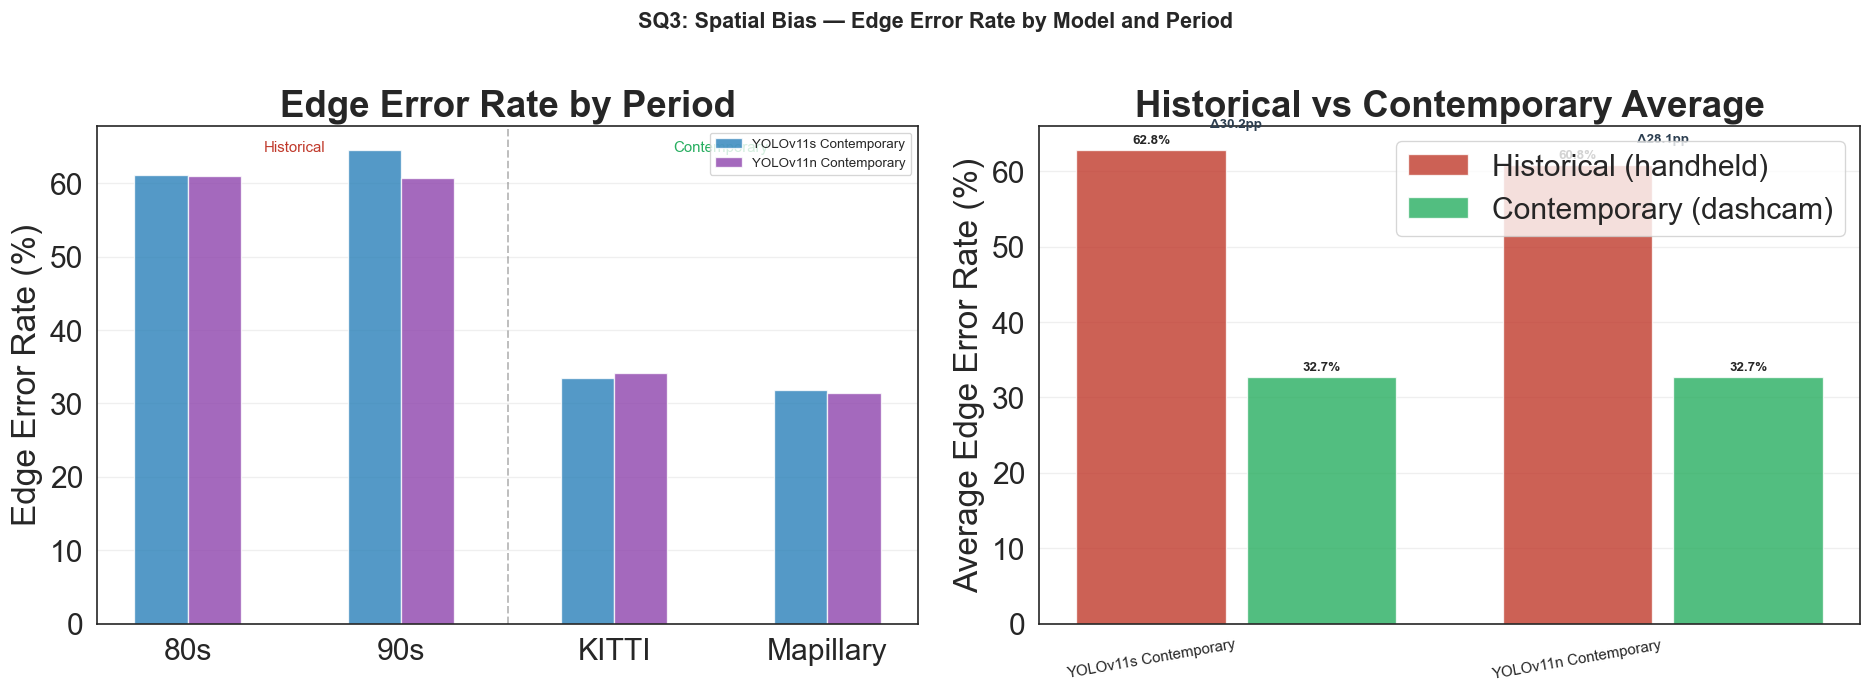

Figure saved → <project>


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('SQ3: Spatial Bias — Edge Error Rate by Model and Period',
             fontsize=13, fontweight='bold')

# Left: edge rate per period per model
ax1 = axes[0]
n_periods = len(PERIODS)
n_models  = len(MODEL_CONFIGS)
x = np.arange(n_periods)
width = 0.25

for i, (cfg_name, cfg) in enumerate(MODEL_CONFIGS.items()):
    rates = [sq3_results[cfg_name][p]['edge_rate'] * 100 for p in PERIODS]
    offset = (i - n_models/2 + 0.5) * width
    bars = ax1.bar(x + offset, rates, width, label=cfg['label'],
                   color=cfg['color'], alpha=0.8)

ax1.set_xticks(x)
ax1.set_xticklabels(PERIODS)
ax1.set_ylabel('Edge Error Rate (%)')
ax1.set_title('Edge Error Rate by Period', fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)
ax1.axvline(1.5, color='grey', linestyle='--', alpha=0.5)
ax1.text(0.5, ax1.get_ylim()[1]*0.95, 'Historical',
         ha='center', fontsize=9, color='#C0392B')
ax1.text(2.5, ax1.get_ylim()[1]*0.95, 'Contemporary',
         ha='center', fontsize=9, color='#27AE60')

# Right: historical vs contemporary average per model
ax2 = axes[1]
model_labels = [cfg['label'] for cfg in MODEL_CONFIGS.values()]
hist_rates   = [sq3_results[c]['summary']['hist_avg'] * 100
                for c in MODEL_CONFIGS]
cont_rates   = [sq3_results[c]['summary']['cont_avg'] * 100
                for c in MODEL_CONFIGS]

x2 = np.arange(len(model_labels))
b1 = ax2.bar(x2 - 0.2, hist_rates, 0.35, label='Historical (handheld)',
             color='#C0392B', alpha=0.8)
b2 = ax2.bar(x2 + 0.2, cont_rates, 0.35, label='Contemporary (dashcam)',
             color='#27AE60', alpha=0.8)

for bar, val in zip(list(b1) + list(b2), hist_rates + cont_rates):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax2.set_xticks(x2)
ax2.set_xticklabels(model_labels, rotation=10, ha='right', fontsize=9)
ax2.set_ylabel('Average Edge Error Rate (%)')
ax2.set_title('Historical vs Contemporary Average', fontweight='bold')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Annotate differences
for i, cfg_name in enumerate(MODEL_CONFIGS):
    diff = sq3_results[cfg_name]['summary']['difference'] * 100
    ax2.text(i, max(hist_rates[i], cont_rates[i]) + 3,
             f'Δ{diff:.1f}pp', ha='center', fontsize=8,
             color='#2C3E50', fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sq3_spatial_bias_all_models.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'sq3_spatial_bias_all_models.png'}")

In [28]:
import seaborn as sns

sns.set_theme(style="white", context="paper", font="sans-serif")
plt.rcParams.update({
    'font.sans-serif'  : ['Arial', 'DejaVu Sans', 'Liberation Sans', 'sans-serif'],
    'font.size'        : 16,
    'axes.titlesize'   : 18,
    'axes.labelsize'   : 16,
    'xtick.labelsize'  : 14,
    'ytick.labelsize'  : 14,
    'legend.fontsize'  : 14,
    'figure.titlesize' : 20,
})

fig, ax1 = plt.subplots(figsize=(10, 6))

for cfg_name, cfg in MODEL_CONFIGS.items():
    rates = [sq3_results[cfg_name][p]['edge_rate'] * 100 for p in PERIODS]
    ax1.plot(PERIODS, rates, marker='o', linewidth=2.5, markersize=10,
             label=cfg['label'], color=cfg['color'])
    for period, rate in zip(PERIODS, rates):
        ax1.annotate(f'{rate:.1f}%', (period, rate),
                     textcoords='offset points', xytext=(0, 10),
                     ha='center', fontsize=13, color=cfg['color'], fontweight='bold')

ax1.axvline(1.5, color='grey', linestyle='--', alpha=0.5)
ax1.set_ylabel('Edge Error Rate (%)')
ax1.set_title('SQ3: Edge Error Rate by Period', fontweight='bold')
ax1.set_ylim(0, 80)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
ax1.text(0.28, 0.97, 'Historical', ha='center', fontsize=14,
         color='#C0392B', fontweight='bold', transform=ax1.transAxes, va='top')
ax1.text(0.78, 0.97, 'Contemporary', ha='center', fontsize=14,
         color='#27AE60', fontweight='bold', transform=ax1.transAxes, va='top')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sq3_dotplot.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'sq3_dotplot.png'}")

Figure saved → <project>


Building spatial error heatmaps (full dataset)...


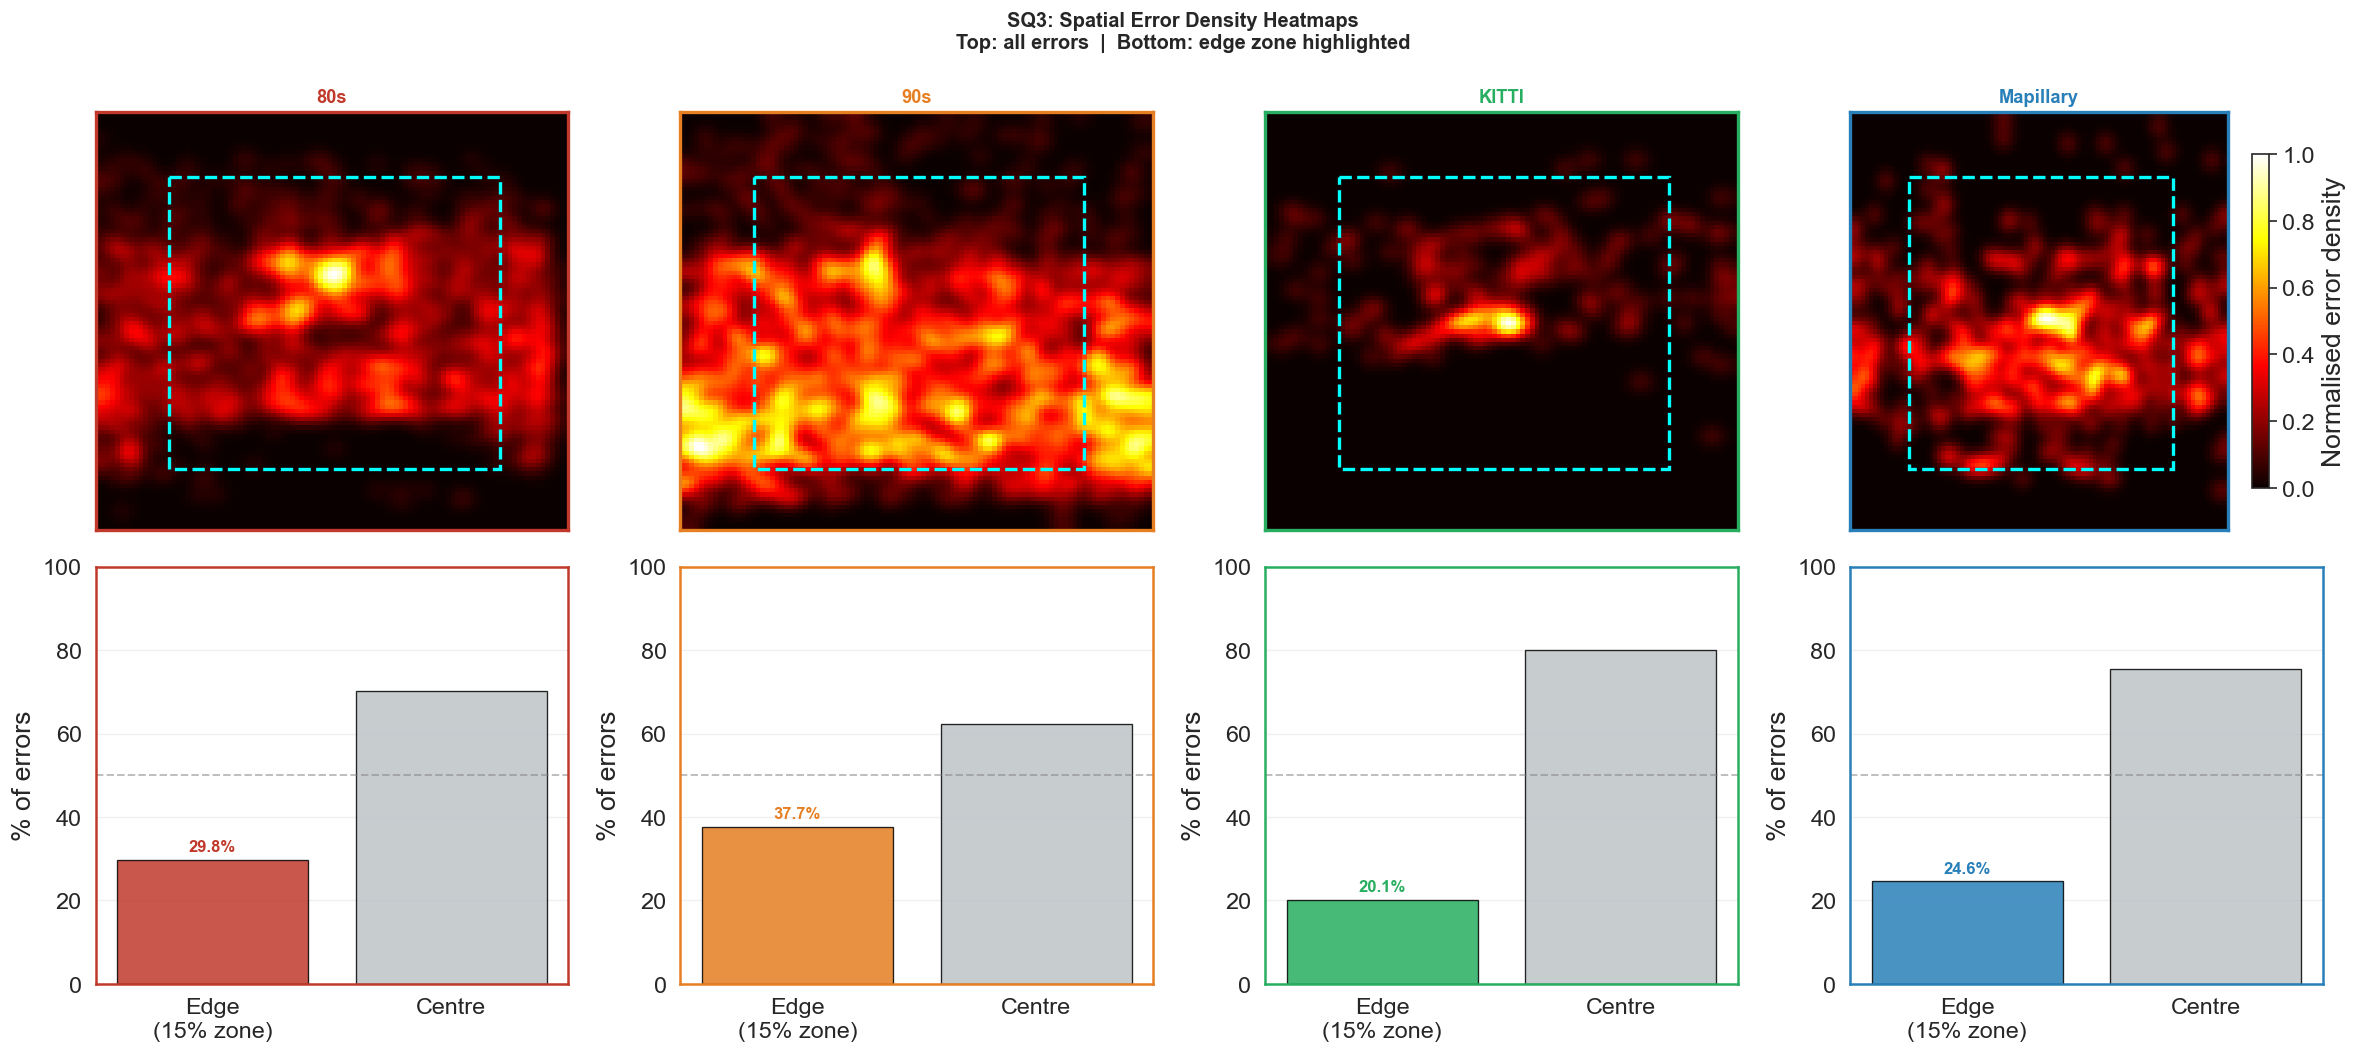

SQ3 visual evidence saved.


In [29]:
"""
SQ3 Visual Evidence
1. Sample images per period with edge zone overlay and FP/FN marked
2. Error heatmaps — where errors concentrate spatially per period
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import random
from pathlib import Path
from ultralytics import YOLO

SAMPLE_SEED  = 7
N_SAMPLES    = 2
EDGE_THRESH  = 0.15
random.seed(SAMPLE_SEED)

primary_weights = MODEL_CONFIGS['small_contemporary']['weights']
model = YOLO(str(primary_weights))


def get_gt(label_path, img_w, img_h):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            p = line.strip().split()
            if len(p) >= 5:
                cid, cx, cy, w, h = map(float, p[:5])
                x1 = (cx-w/2)*img_w; y1 = (cy-h/2)*img_h
                x2 = (cx+w/2)*img_w; y2 = (cy+h/2)*img_h
                boxes.append({'cls': int(cid), 'box': (x1,y1,x2,y2)})
    return boxes


def get_preds(img_bgr):
    h, w = img_bgr.shape[:2]
    res = model.predict(source=img_bgr, imgsz=IMG_SIZE,
                        conf=CONF_THRES, device=DEVICE,
                        verbose=False)
    boxes = []
    if res[0].boxes is not None:
        for box in res[0].boxes:
            x1,y1,x2,y2 = box.xyxy[0].cpu().numpy()
            boxes.append({
                'cls': int(box.cls[0].cpu()),
                'box': (x1,y1,x2,y2),
                'conf': float(box.conf[0].cpu()),
            })
    return boxes


def match_boxes(gt_boxes, pred_boxes, iou_thresh=0.5):
    """Returns (tp_gt_idx, tp_pred_idx, fp_pred_idx, fn_gt_idx)."""
    gt_matched   = [False] * len(gt_boxes)
    pred_matched = [False] * len(pred_boxes)

    for pi, p in enumerate(pred_boxes):
        best_iou, best_gi = 0.0, -1
        for gi, g in enumerate(gt_boxes):
            if p['cls'] == g['cls'] and not gt_matched[gi]:
                iou = calculate_iou(p['box'], g['box'])
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
        if best_iou >= iou_thresh and best_gi >= 0:
            gt_matched[best_gi]  = True
            pred_matched[pi]     = True

    fp_idx = [i for i, m in enumerate(pred_matched) if not m]
    fn_idx = [i for i, m in enumerate(gt_matched)   if not m]
    return fp_idx, fn_idx


def draw_sq3_image(img_bgr, gt_boxes, pred_boxes, fp_idx, fn_idx):
    """
    Draws:
      - Grey shaded edge zones (15% boundary)
      - Yellow dashed rectangle showing centre zone boundary
      - Bounding boxes in class colour
    """
    out = img_bgr.copy()
    h, w = out.shape[:2]
    ex = int(w * EDGE_THRESH)
    ey = int(h * EDGE_THRESH)

    # Shade edge zones lightly
    overlay = out.copy()
    cv2.rectangle(overlay, (0,0), (w,ey), (80,80,80), -1)
    cv2.rectangle(overlay, (0,h-ey), (w,h), (80,80,80), -1)
    cv2.rectangle(overlay, (0,0), (ex,h), (80,80,80), -1)
    cv2.rectangle(overlay, (w-ex,0), (w,h), (80,80,80), -1)
    out = cv2.addWeighted(overlay, 0.3, out, 0.7, 0)

    # Centre zone boundary — white in BGR displays as white in RGB
    cv2.rectangle(out, (ex,ey), (w-ex,h-ey), (255,255,255), 2)

    return out


def draw_boxes_simple(img_bgr, boxes, thickness=3, scale=0.4):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    for item in boxes:
        cid = int(item['cls'])
        x1,y1,x2,y2 = [int(v) for v in item['box']]
        color = CLASS_COLORS_BGR.get(cid, (128,128,128))
        cv2.rectangle(out, (x1,y1), (x2,y2), color, thickness)
        label = CLASSES[cid] if cid < len(CLASSES) else str(cid)
        cv2.putText(out, label, (x1, max(y1-3,10)),
                    cv2.FONT_HERSHEY_SIMPLEX, scale, color, 1)
    return out



# Plot 1: GT vs Predictions with edge zone overlay — 2 columns per period
fig, axes = plt.subplots(len(PERIODS) * N_SAMPLES, 2,
                          figsize=(14, 5 * len(PERIODS) * N_SAMPLES),
                          constrained_layout=True)
fig.suptitle('SQ3: Ground Truth vs Detections with Edge Zone\n'
             'Shaded area = 15% edge zone  |  Cyan border = centre zone',
             fontsize=12, fontweight='bold', y=1.01)

axes[0, 0].set_title('Ground Truth', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Predictions', fontsize=11, fontweight='bold')

row = 0
for period in PERIODS:
    images_dir = EVAL_DATA / period / 'images'
    labels_dir = EVAL_DATA / period / 'labels'
    imgs = [p for p in sorted(list(images_dir.glob('*.jpg')) +
                               list(images_dir.glob('*.png')))
            if (labels_dir / f"{p.stem}.txt").exists()
            and (labels_dir / f"{p.stem}.txt").read_text().strip()]
    sample = random.sample(imgs, min(N_SAMPLES, len(imgs)))

    for img_path in sample:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue
        h, w = img_bgr.shape[:2]
        gt    = get_gt(labels_dir / f"{img_path.stem}.txt", w, h)
        preds = get_preds(img_bgr)
        fp, fn = match_boxes(gt, preds)

        # Compute edge error rate for this image
        n_edge_fp = sum(1 for i in fp
                        if is_at_edge(preds[i]['box'], w, h, EDGE_THRESH))
        n_edge_fn = sum(1 for i in fn
                        if is_at_edge(gt[i]['box'], w, h, EDGE_THRESH))
        total_err = len(fp) + len(fn)
        edge_err  = n_edge_fp + n_edge_fn
        rate      = edge_err / total_err if total_err > 0 else 0

        # Base with edge zone
        base = draw_sq3_image(img_bgr, gt, preds, fp, fn)

        # GT image
        gt_img = draw_boxes_simple(base, gt)
        axes[row, 0].imshow(cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB))
        axes[row, 0].set_ylabel(f'{period}', fontsize=10,
                                 fontweight='bold',
                                 color=PERIOD_COLORS[period])
        axes[row, 0].tick_params(left=False, bottom=False,
                                  labelleft=False, labelbottom=False)
        axes[row, 0].set_xlabel(f'GT: {len(gt)} objects', fontsize=8)
        for spine in axes[row, 0].spines.values():
            spine.set_edgecolor('#27AE60')
            spine.set_linewidth(2)

        # Predictions image
        pred_img = draw_boxes_simple(base, preds)
        axes[row, 1].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
        axes[row, 1].tick_params(left=False, bottom=False,
                                  labelleft=False, labelbottom=False)
        rate_color = '#C0392B' if rate > 0.5 else '#27AE60'
        axes[row, 1].set_xlabel(
            f'Pred: {len(preds)}  |  Edge errors: {edge_err}/{total_err} ({rate*100:.0f}%)',
            fontsize=8, color=rate_color, fontweight='bold')
        for spine in axes[row, 1].spines.values():
            spine.set_edgecolor(PERIOD_COLORS[period])
            spine.set_linewidth(2)

        row += 1

legend_patches = [
    mpatches.Patch(color=tuple(c/255 for c in cv2.cvtColor(
        np.uint8([[v]]), cv2.COLOR_BGR2RGB)[0,0]), label=CLASSES[k])
    for k, v in CLASS_COLORS_BGR.items()
]
legend_patches += [
    mpatches.Patch(facecolor='grey', alpha=0.4, label='Edge zone (15%)'),
    mpatches.Patch(facecolor='none', edgecolor='white',
                   linewidth=2, label='Centre zone boundary'),
]
fig.legend(handles=legend_patches, loc='lower center',
           ncol=len(legend_patches), fontsize=8,
           bbox_to_anchor=(0.5, -0.015),
           frameon=True, framealpha=0.9)
plt.savefig(RESULTS_DIR / 'sq3_spatial_error_samples.png',
            dpi=150, bbox_inches='tight')
plt.show()


# Plot 2: Spatial error density heatmaps per period
# Accumulates all FP+FN locations across the full dataset
print("Building spatial error heatmaps (full dataset)...")

HMAP_H, HMAP_W = 100, 100   # normalised grid resolution

fig, axes = plt.subplots(2, len(PERIODS),
                          figsize=(5*len(PERIODS), 9))
fig.suptitle('SQ3: Spatial Error Density Heatmaps\n'
             'Top: all errors  |  Bottom: edge zone highlighted',
             fontsize=12, fontweight='bold')

cmap_hot = plt.cm.hot

for col, period in enumerate(PERIODS):
    images_dir = EVAL_DATA / period / 'images'
    labels_dir = EVAL_DATA / period / 'labels'
    heatmap    = np.zeros((HMAP_H, HMAP_W), dtype=np.float32)

    imgs = sorted(list(images_dir.glob('*.jpg')) +
                  list(images_dir.glob('*.png')))

    for img_path in imgs:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue
        h, w = img_bgr.shape[:2]
        gt    = get_gt(labels_dir / f"{img_path.stem}.txt", w, h)
        preds = get_preds(img_bgr)
        fp, fn = match_boxes(gt, preds)

        for i in fp:
            x1,y1,x2,y2 = preds[i]['box']
            cx = int(((x1+x2)/2) / w * HMAP_W)
            cy = int(((y1+y2)/2) / h * HMAP_H)
            cx = min(max(cx,0), HMAP_W-1)
            cy = min(max(cy,0), HMAP_H-1)
            heatmap[cy, cx] += 1

        for i in fn:
            x1,y1,x2,y2 = gt[i]['box']
            cx = int(((x1+x2)/2) / w * HMAP_W)
            cy = int(((y1+y2)/2) / h * HMAP_H)
            cx = min(max(cx,0), HMAP_W-1)
            cy = min(max(cy,0), HMAP_H-1)
            heatmap[cy, cx] += 1

    # Smooth for display
    heatmap_smooth = cv2.GaussianBlur(heatmap, (11,11), 0)
    if heatmap_smooth.max() > 0:
        heatmap_smooth /= heatmap_smooth.max()

    # Top: full heatmap
    ax_top = axes[0, col]
    im = ax_top.imshow(heatmap_smooth, cmap='hot', vmin=0, vmax=1,
                        aspect='auto')
    ax_top.set_title(period, fontsize=11, fontweight='bold',
                     color=PERIOD_COLORS[period])
    ax_top.set_xticks([]); ax_top.set_yticks([])

    # Edge zone overlay
    ex = int(HMAP_W * EDGE_THRESH)
    ey = int(HMAP_H * EDGE_THRESH)
    for spine in ax_top.spines.values():
        spine.set_edgecolor(PERIOD_COLORS[period])
        spine.set_linewidth(2)
    rect = plt.Rectangle((ex, ey), HMAP_W-2*ex, HMAP_H-2*ey,
                           linewidth=2, edgecolor='cyan',
                           facecolor='none', linestyle='--')
    ax_top.add_patch(rect)

    # Bottom: edge vs centre split bar
    ax_bot = axes[1, col]
    edge_mask   = np.zeros((HMAP_H, HMAP_W), dtype=bool)
    edge_mask[:ey,  :] = True
    edge_mask[-ey:, :] = True
    edge_mask[:,  :ex] = True
    edge_mask[:, -ex:] = True

    edge_sum   = heatmap[edge_mask].sum()
    centre_sum = heatmap[~edge_mask].sum()
    total      = edge_sum + centre_sum
    edge_pct   = edge_sum / total * 100 if total > 0 else 0

    ax_bot.bar(['Edge\n(15% zone)', 'Centre'],
               [edge_pct, 100-edge_pct],
               color=[PERIOD_COLORS[period], '#BDC3C7'],
               alpha=0.85, edgecolor='black', linewidth=0.8)
    ax_bot.set_ylim(0, 100)
    ax_bot.set_ylabel('% of errors')
    ax_bot.axhline(50, color='grey', linestyle='--', alpha=0.5)
    ax_bot.text(0, edge_pct+2, f'{edge_pct:.1f}%',
                ha='center', fontsize=10, fontweight='bold',
                color=PERIOD_COLORS[period])
    ax_bot.grid(axis='y', alpha=0.3)
    for spine in ax_bot.spines.values():
        spine.set_edgecolor(PERIOD_COLORS[period])
        spine.set_linewidth(1.5)

plt.colorbar(im, ax=axes[0,-1], label='Normalised error density', shrink=0.8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sq3_error_heatmaps.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("SQ3 visual evidence saved.")

## SQ3: Spatial Bias - Interpretation

### Answer - Historical datasets produce significantly higher edge error rates than contemporary datasets

Both model variants show a consistent and large spatial bias effect. Historical handheld street photography (80s, 90s)
produces edge error rates of approximately 61-65%, while contemporary dashcam footage (KITTI, Mapillary) produces rates of 31-34%. The gap is 30.2 percentage points for YOLOv11s Contemporary and 28.1 percentage points for YOLOv11n Contemporary. **H4 is confirmed.**

| Model | Historical avg | Contemporary avg | Difference |
|---|---|---|---|
| YOLOv11s Contemporary | 62.8% | 32.7% | +30.2pp |
| YOLOv11n Contemporary | 60.8% | 32.7% | +28.1pp |

### Within-group consistency strengthens the finding

The 80s (61.1%) and 90s (64.5%) rates are nearly identical despite originating from different cities and annotation
sources. KITTI (33.5%) and Mapillary (31.8%) are likewise tightly clustered despite their different geographic
scopes. This internal consistency indicates the effect is driven by the structural difference between handheld and
dashcam capture methodology, not by any single dataset's idiosyncrasies. The pattern is also fully stable across
model sizes (v11s vs v11n differ by at most 3.8pp on any individual period).

### Spatial density heatmaps confirm the mechanism

For the 80s and 90s datasets, error density is diffuse and distributed across the entire image frame, with
substantial concentration at all four edges. For KITTI, errors collapse into a narrow horizontal band corresponding
to the road surface, precisely the region where the dashcam field of view concentrates objects. Mapillary shows a similar centre-weighted pattern. The modern heatmaps are now computed from the 30 held-out images per set (194 and 553 errors for KITTI and Mapillary with v11s), so they are noisier than the historical ones. The contrast between a diffuse full-frame error distribution and a structured
central-band distribution is the spatial signature of handheld versus dashcam composition, consistent with the
viewpoint-dependent object priors described by Hoiem et al. (2006).

### SQ3 Answer

Detection errors on historical datasets are distributed approximately twice as heavily toward image edges as errors
on contemporary datasets (~62% vs ~33%). This confirms that scene composition differences between handheld street
photography and car-mounted camera footage produce a measurable and consistent spatial bias in detection failure
patterns. The model has learned a strong spatial prior from dashcam training data; when that prior is violated by
unstructured historical photography, errors migrate to image regions where the model has low confidence and weak
feature responses.

## Research Sub-Question 4: Per-Class Vulnerability and Error Type Analysis

In [30]:
sq4_results_path = RESULTS_DIR / 'sq4_vulnerability_all_models_heldout.json'


def run_sq4(weights_path):
    """
    Computes per-class AP50, precision, recall, F1 and error type per period.
    Error type: recognition_failure (P < R, many FPs) vs
                localisation_failure (R < P, many FNs).
    """
    model   = YOLO(str(weights_path))
    results = {}

    for period in PERIODS:
        images_dir = EVAL_DATA / period / 'images'
        labels_dir = EVAL_DATA / period / 'labels'

        preds = model.predict(
            source  = str(images_dir),
            imgsz   = IMG_SIZE,
            conf    = CONF_THRES,
            device  = DEVICE,
            workers = 0,
            verbose = False,
            save    = False,
        )

        class_tp      = defaultdict(list)
        class_tp_count = defaultdict(int)
        class_fp_count = defaultdict(int)
        class_fn_count = defaultdict(int)
        class_gt_count = defaultdict(int)

        for pred in preds:
            img_h, img_w = pred.orig_shape
            lbl_path = labels_dir / f"{Path(pred.path).stem}.txt"

            gt_boxes = []
            if lbl_path.exists():
                for line in lbl_path.read_text().strip().splitlines():
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    cid, cx, cy, w, h = map(float, parts[:5])
                    x1=(cx-w/2)*img_w; y1=(cy-h/2)*img_h
                    x2=(cx+w/2)*img_w; y2=(cy+h/2)*img_h
                    gt_boxes.append({'cls': int(cid), 'box': (x1,y1,x2,y2), 'matched': False})
                    class_gt_count[int(cid)] += 1

            pred_boxes = []
            if pred.boxes is not None:
                for box in pred.boxes:
                    x1,y1,x2,y2 = box.xyxy[0].cpu().numpy()
                    pred_boxes.append({
                        'cls' : int(box.cls[0].cpu()),
                        'box' : (x1,y1,x2,y2),
                        'conf': float(box.conf[0].cpu()),
                    })
            pred_boxes.sort(key=lambda x: x['conf'], reverse=True)

            for p in pred_boxes:
                best_iou, best_idx = 0.0, -1
                for i, g in enumerate(gt_boxes):
                    if p['cls'] == g['cls'] and not g['matched']:
                        iou = calculate_iou(p['box'], g['box'])
                        if iou > best_iou:
                            best_iou, best_idx = iou, i
                if best_iou >= IOU_THRES and best_idx >= 0:
                    gt_boxes[best_idx]['matched'] = True
                    class_tp[p['cls']].append((p['conf'], 1))
                    class_tp_count[p['cls']] += 1
                else:
                    class_tp[p['cls']].append((p['conf'], 0))
                    class_fp_count[p['cls']] += 1

            for g in gt_boxes:
                if not g['matched']:
                    class_fn_count[g['cls']] += 1

        period_metrics = {}
        for cid, cls_name in enumerate(CLASSES):
            gt = class_gt_count[cid]
            if gt == 0:
                period_metrics[cls_name] = {
                    'AP50': None, 'precision': None,
                    'recall': None, 'F1': None,
                    'error_type': 'no_ground_truth'
                }
                continue

            tp = class_tp_count[cid]
            fp = class_fp_count[cid]
            fn = class_fn_count[cid]
            prec   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            f1     = 2*prec*recall / (prec+recall) if (prec+recall) > 0 else 0.0

            # AP via 11-point interpolation
            dets = sorted(class_tp[cid], key=lambda x: x[0], reverse=True)
            cum_tp = cum_fp = 0
            precs, recs = [], []
            for _, is_tp in dets:
                cum_tp += is_tp; cum_fp += 1 - is_tp
                precs.append(cum_tp / (cum_tp + cum_fp))
                recs.append(cum_tp / gt)
            ap = sum(max((p for p, r in zip(precs, recs) if r >= t), default=0)
                     for t in np.arange(0, 1.1, 0.1)) / 11.0

            error_type = 'recognition_failure' if prec < recall else 'localisation_failure'
            period_metrics[cls_name] = {
                'AP50': round(ap, 4), 'precision': round(prec, 4),
                'recall': round(recall, 4), 'F1': round(f1, 4),
                'TP': tp, 'FP': fp, 'FN': fn,
                'error_type': error_type,
            }

        results[period] = period_metrics

    # Compute degradation ranking
    degradation = {}
    for cls_name in CLASSES:
        hist = [results[p][cls_name]['AP50'] for p in HIST_PERIODS
                if results[p][cls_name]['AP50'] is not None]
        cont = [results[p][cls_name]['AP50'] for p in CONT_PERIODS
                if results[p][cls_name]['AP50'] is not None]
        if hist and cont:
            drop_pct = (np.mean(cont) - np.mean(hist)) / np.mean(cont) * 100
            degradation[cls_name] = round(drop_pct, 1)

    results['degradation_ranking'] = dict(
        sorted(degradation.items(), key=lambda x: x[1], reverse=True)
    )
    return results


# Run
if sq4_results_path.exists():
    with open(sq4_results_path) as f:
        sq4_results = json.load(f)
    print(f"Loaded existing SQ4 results from {sq4_results_path}")
else:
    sq4_results = {}
    for cfg_name, cfg in MODEL_CONFIGS.items():
        print(f"\n{'='*60}")
        print(f"SQ4 — {cfg['label']}")
        print('='*60)
        sq4_results[cfg_name] = run_sq4(cfg['weights'])

    with open(sq4_results_path, 'w') as f:
        json.dump(sq4_results, f, indent=2)
    print(f"\nResults saved → {sq4_results_path}")


# Summary table
print(f"\n{'Model':<25} {'Class':<12} {'Hist AP':>9} {'Cont AP':>9} "
      f"{'Drop%':>8} {'Dominant Error'}")
print("-" * 78)

for cfg_name, cfg in MODEL_CONFIGS.items():
    r = sq4_results[cfg_name]
    for cls_name in CLASSES:
        hist = [r[p][cls_name]['AP50'] for p in HIST_PERIODS
                if r[p][cls_name]['AP50'] is not None]
        cont = [r[p][cls_name]['AP50'] for p in CONT_PERIODS
                if r[p][cls_name]['AP50'] is not None]
        if not hist or not cont:
            continue
        errors = [r[p][cls_name]['error_type'] for p in PERIODS
                  if r[p][cls_name].get('error_type') not in (None, 'no_ground_truth')]
        dominant = max(set(errors), key=errors.count) if errors else 'n/a'
        drop = r['degradation_ranking'].get(cls_name, 0)
        print(f"{cfg['label']:<25} {cls_name:<12} "
              f"{np.mean(hist):>9.3f} {np.mean(cont):>9.3f} "
              f"{drop:>7.1f}%  {dominant}")
    print(f"  Ranking: {r['degradation_ranking']}\n")


SQ4 — YOLOv11s Contemporary

SQ4 — YOLOv11n Contemporary

Results saved → <project>

Model                     Class          Hist AP   Cont AP    Drop% Dominant Error
------------------------------------------------------------------------------
YOLOv11s Contemporary     Building         0.115     0.296    61.3%  localisation_failure
YOLOv11s Contemporary     Car              0.133     0.645    79.4%  localisation_failure
YOLOv11s Contemporary     Truck            0.000     0.205   100.0%  localisation_failure
YOLOv11s Contemporary     Pedestrian       0.045     0.419    89.2%  localisation_failure
YOLOv11s Contemporary     Cyclist          0.000     0.115   100.0%  localisation_failure
  Ranking: {'Truck': np.float64(100.0), 'Cyclist': np.float64(100.0), 'Pedestrian': np.float64(89.2), 'Car': np.float64(79.4), 'Building': np.float64(61.3)}

YOLOv11n Contemporary     Building         0.150     0.277    45.7%  localisation_failure
YOLOv11n Contemporary     Car              0.170     0

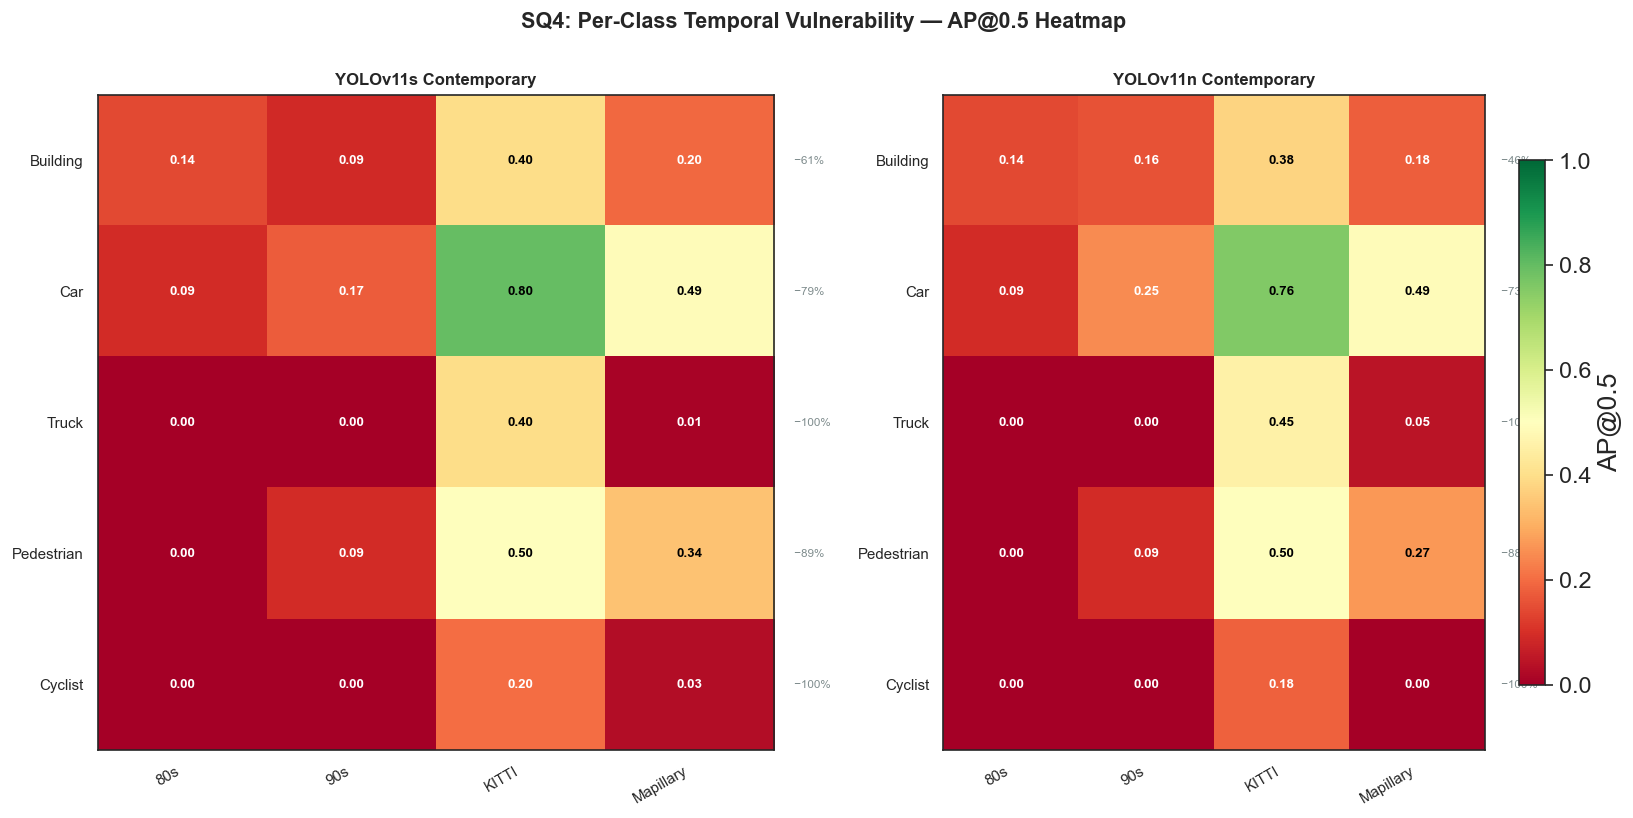

Figure saved → <project>


In [31]:
fig, axes = plt.subplots(1, len(MODEL_CONFIGS), figsize=(7 * len(MODEL_CONFIGS), 7))
fig.suptitle('SQ4: Per-Class Temporal Vulnerability — AP@0.5 Heatmap',
             fontsize=13, fontweight='bold')

for ax, (cfg_name, cfg) in zip(axes, MODEL_CONFIGS.items()):
    matrix = np.zeros((N_CLASSES, len(PERIODS)))
    for j, period in enumerate(PERIODS):
        for i, cls_name in enumerate(CLASSES):
            ap = sq4_results[cfg_name][period][cls_name]['AP50']
            matrix[i, j] = ap if ap is not None else 0.0

    im = ax.imshow(matrix, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(PERIODS)))
    ax.set_xticklabels(PERIODS, rotation=30, ha='right', fontsize=9)
    ax.set_yticks(range(N_CLASSES))
    ax.set_yticklabels(CLASSES, fontsize=9)
    ax.set_title(cfg['label'], fontsize=10, fontweight='bold')

    for i in range(N_CLASSES):
        for j in range(len(PERIODS)):
            val = matrix[i, j]
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=8, fontweight='bold',
                    color='white' if val < 0.25 else 'black')

    # Annotate degradation ranking on right side
    ranking = sq4_results[cfg_name]['degradation_ranking']
    for i, cls_name in enumerate(CLASSES):
        drop = ranking.get(cls_name, 0)
        ax.text(len(PERIODS) - 0.4, i, f' −{drop:.0f}%',
                va='center', fontsize=7, color='#7F8C8D')

plt.colorbar(im, ax=axes[-1], label='AP@0.5', shrink=0.8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sq4_vulnerability_all_models.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Figure saved → {RESULTS_DIR / 'sq4_vulnerability_all_models.png'}")

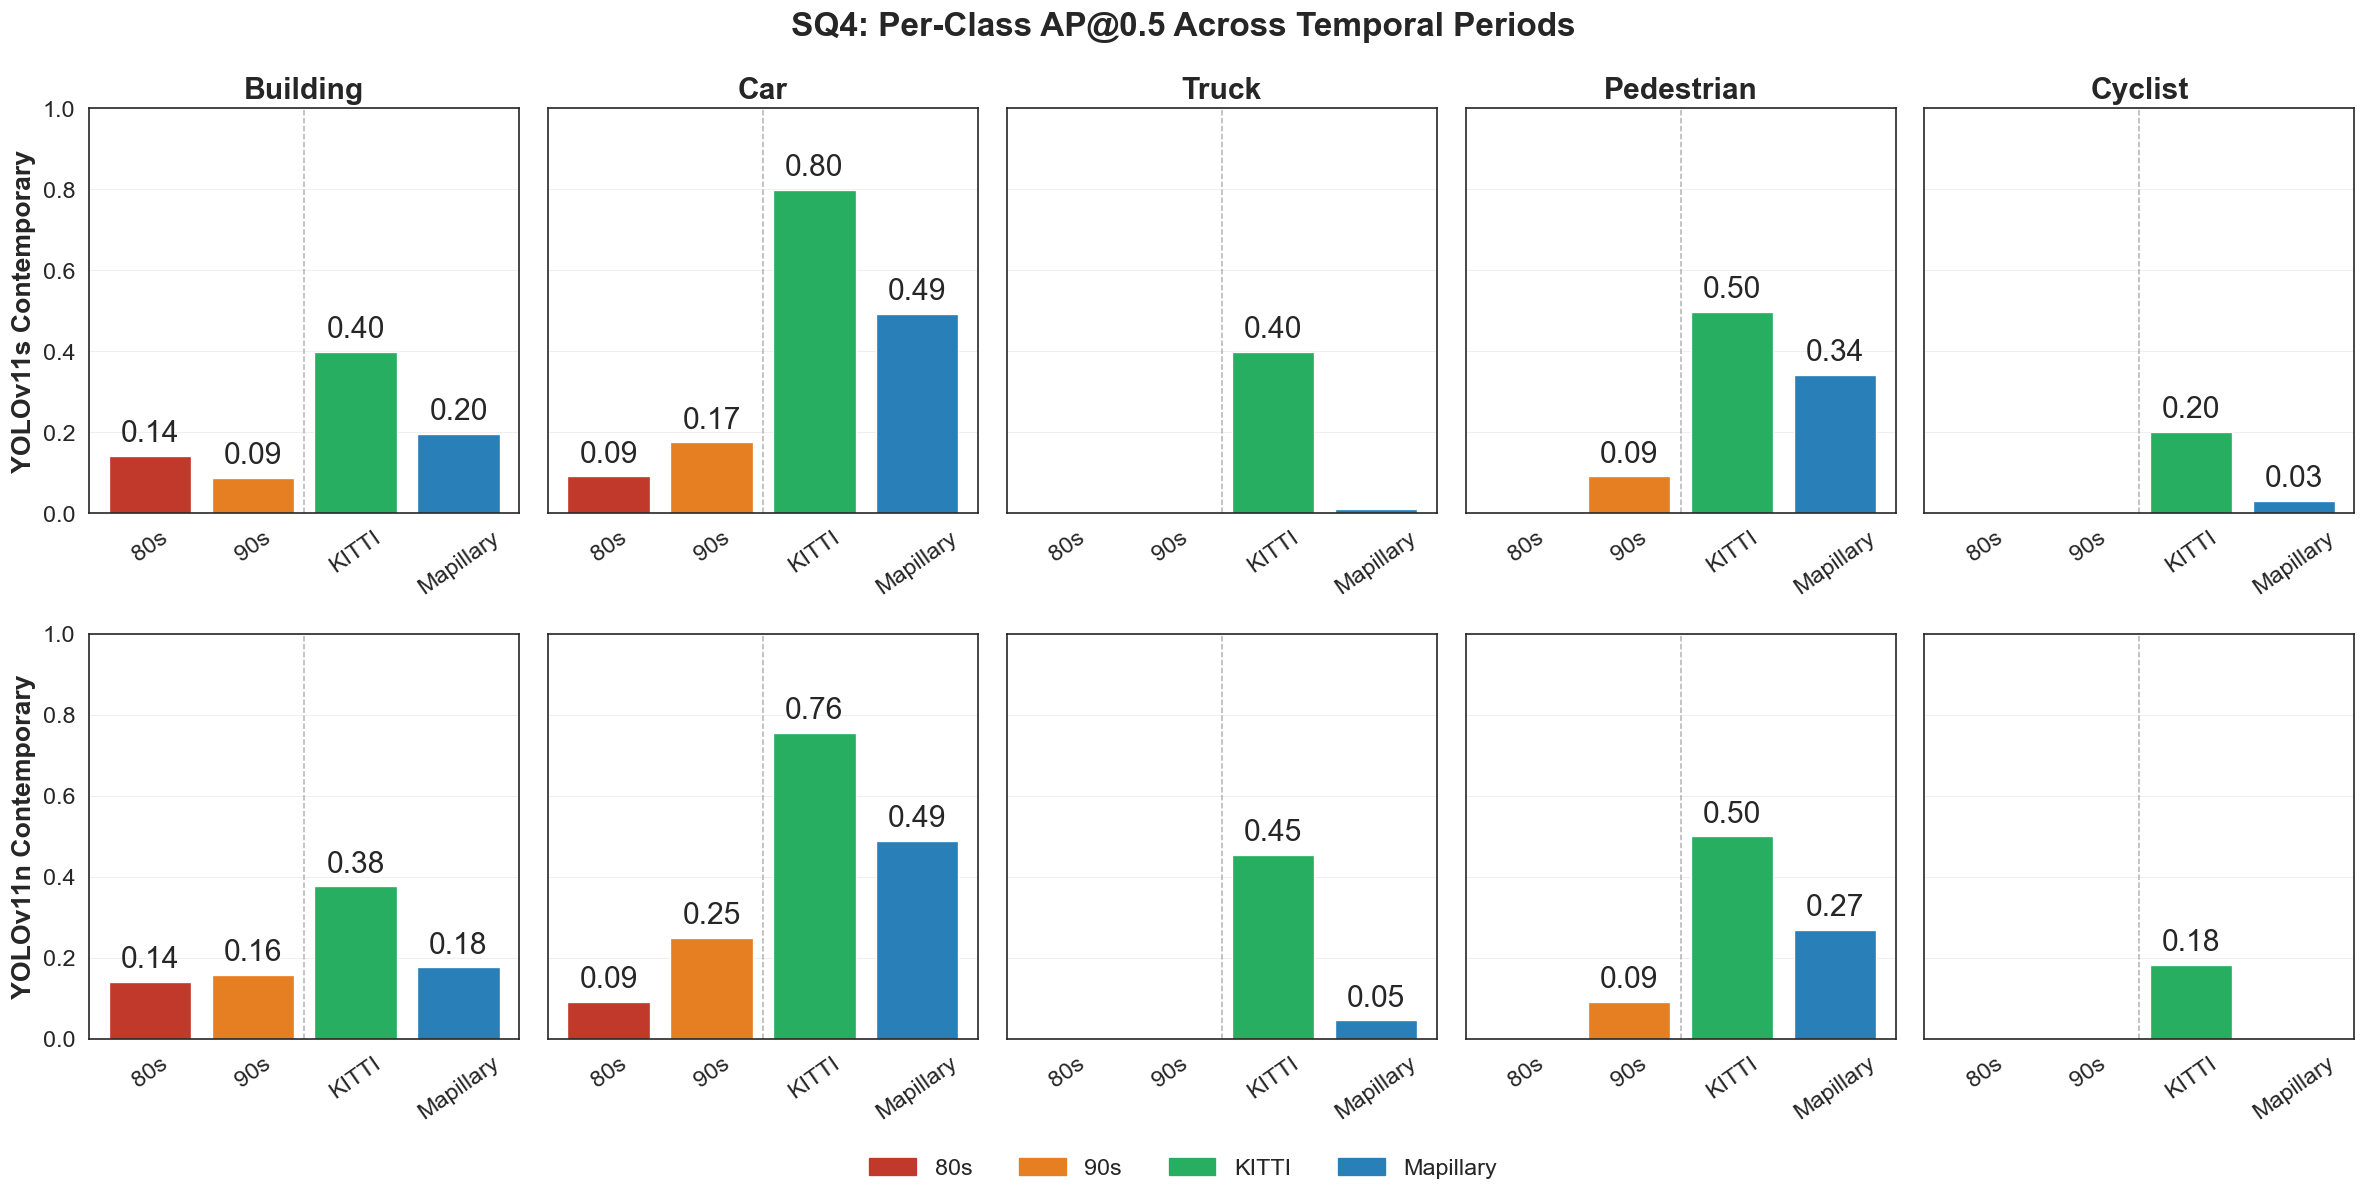

Saved: sq4_per_class_ap_by_period.png


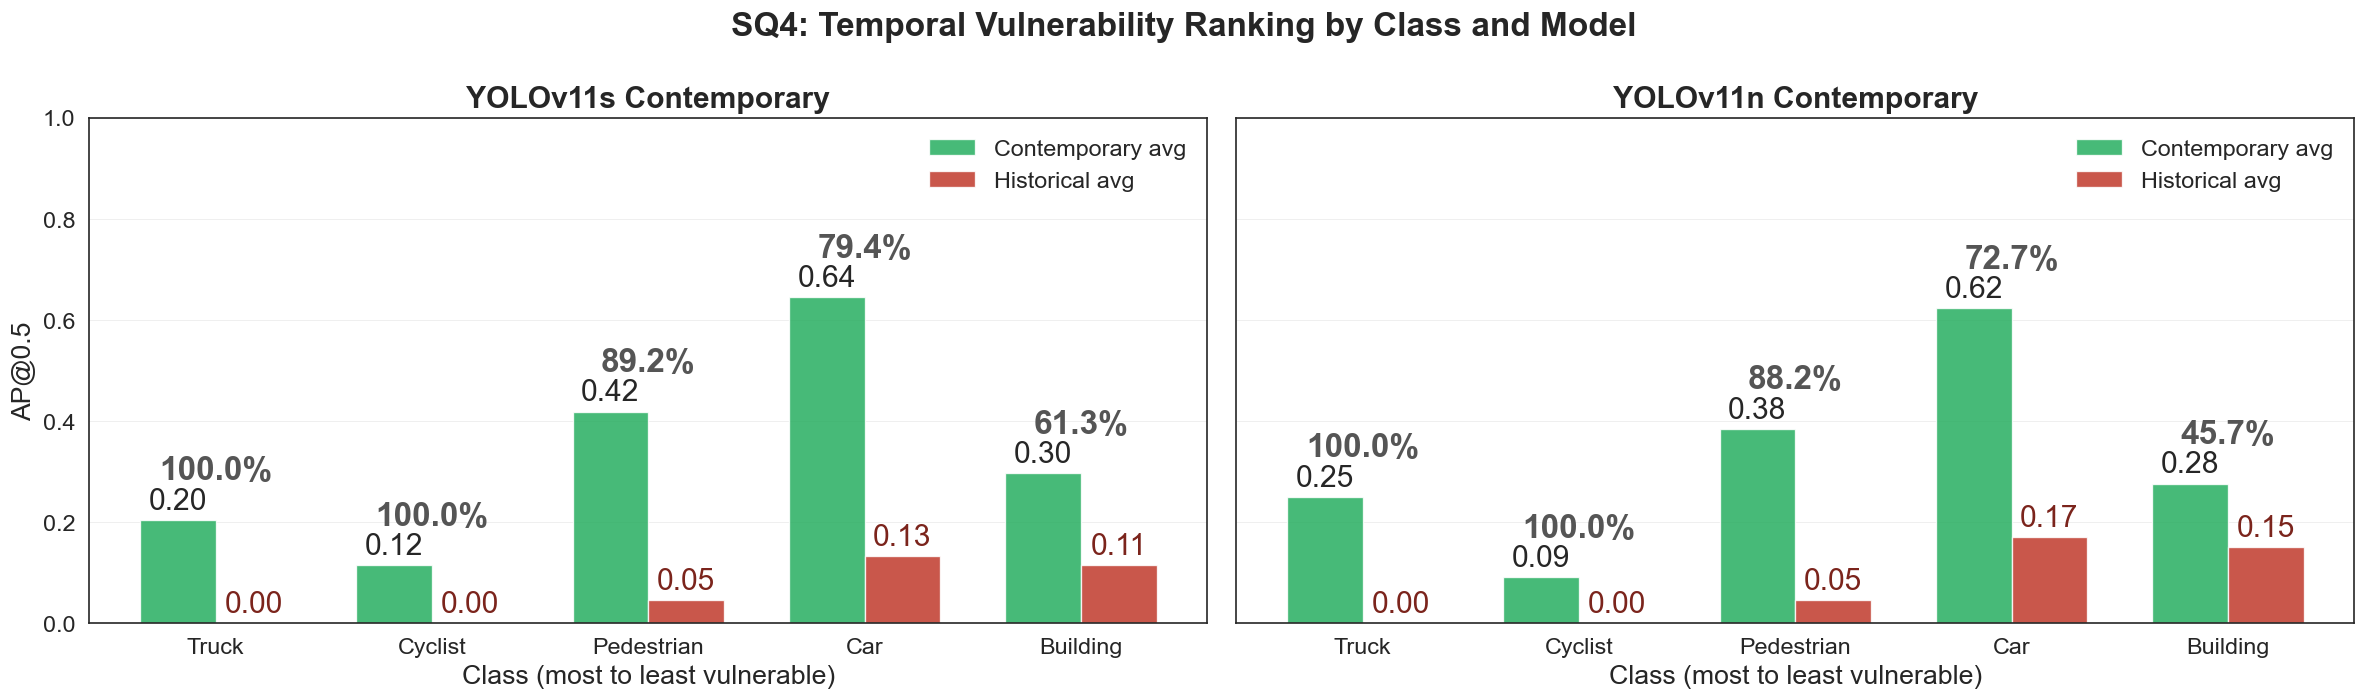

Saved: sq4_vulnerability_ranking.png


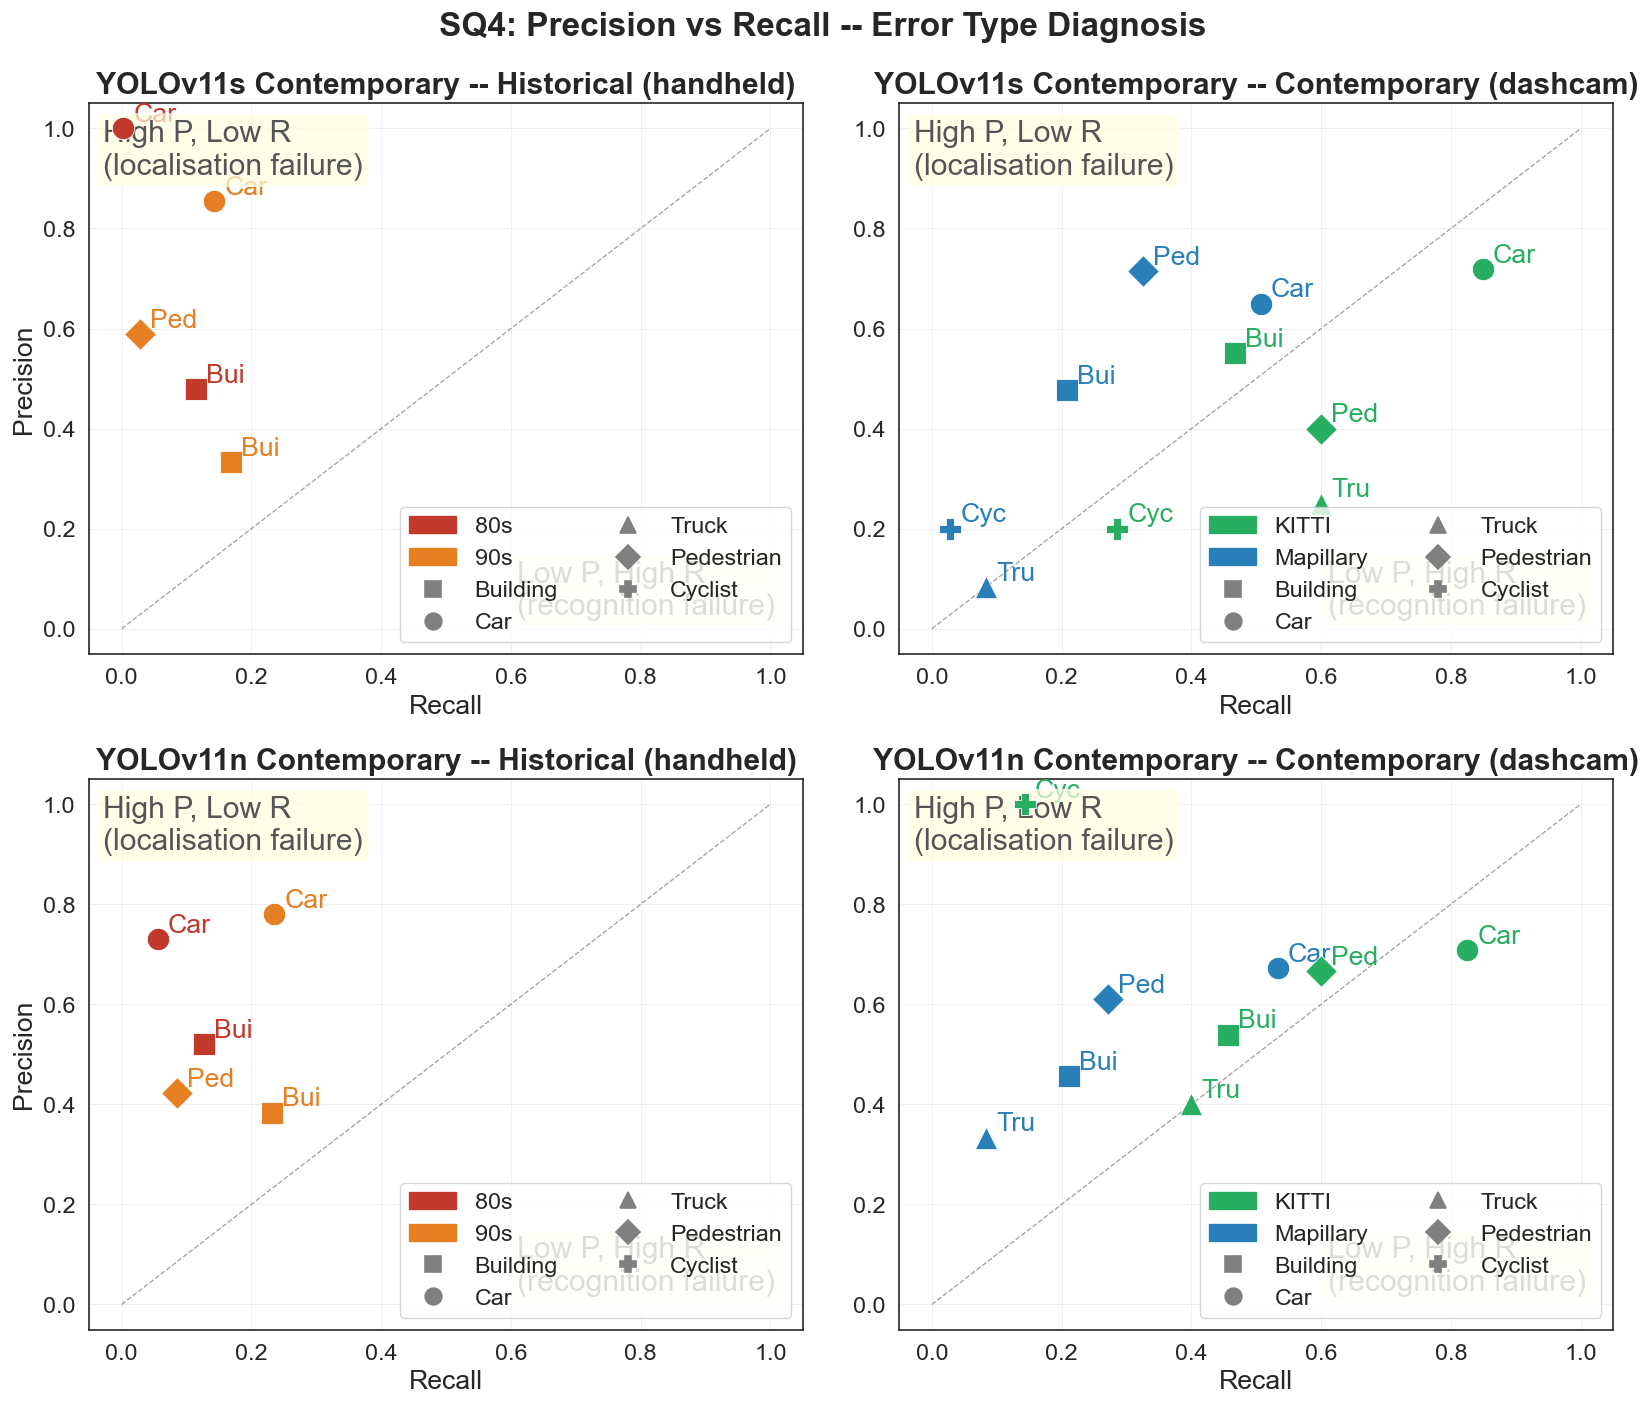

Saved: sq4_precision_recall_scatter.png

All SQ4 visualisations saved.


In [32]:
"""
SQ4: Per-Class Vulnerability and Error Type - Visualisations
All paths and constants inherited from notebook globals.
"""

import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except:
    pass

# Poster-scale font settings
sns.set_theme(style="white", context="paper", font="sans-serif")
plt.rcParams.update({
    'font.sans-serif'  : ['Arial', 'DejaVu Sans', 'Liberation Sans', 'sans-serif'],
    'font.size'        : 16,
    'axes.titlesize'   : 18,
    'axes.labelsize'   : 16,
    'xtick.labelsize'  : 14,
    'ytick.labelsize'  : 14,
    'legend.fontsize'  : 14,
    'figure.titlesize' : 20,
})

sq4_results_path = RESULTS_DIR / 'sq4_vulnerability_all_models_heldout.json'

with open(sq4_results_path, 'r') as f:
    sq4_results = json.load(f)

FIG_DIR = RESULTS_DIR / 'sq4_vulnerability'
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_MARKERS = {
    'Building'  : 's',
    'Car'       : 'o',
    'Truck'     : '^',
    'Pedestrian': 'D',
    'Cyclist'   : 'P',
}


def get_ap(cfg_name, period, cls):
    val = sq4_results[cfg_name][period][cls]['AP50']
    return val if val is not None else 0.0

def get_pr(cfg_name, period, cls):
    d = sq4_results[cfg_name][period][cls]
    p = d.get('precision') or 0.0
    r = d.get('recall')    or 0.0
    return p, r

def hist_cont_ap(cfg_name, cls):
    h = np.mean([get_ap(cfg_name, p, cls) for p in HIST_PERIODS])
    c = np.mean([get_ap(cfg_name, p, cls) for p in CONT_PERIODS])
    return h, c


# Figure 1: Per-class AP across all periods, one row per model
fig, axes = plt.subplots(len(MODEL_CONFIGS), len(CLASSES),
                         figsize=(20, 5 * len(MODEL_CONFIGS)), sharey=True)
fig.suptitle('SQ4: Per-Class AP@0.5 Across Temporal Periods', fontweight='bold')

for row, (cfg_key, cfg) in enumerate(MODEL_CONFIGS.items()):
    for col, cls in enumerate(CLASSES):
        ax = axes[row][col]
        aps     = [get_ap(cfg_key, p, cls) for p in PERIODS]
        colours = [PERIOD_COLORS[p] for p in PERIODS]
        bars = ax.bar(PERIODS, aps, color=colours, edgecolor='white', linewidth=0.8)
        if col == 0:
            ax.set_ylabel(cfg['label'], fontweight='bold')
        if row == 0:
            ax.set_title(cls, fontweight='bold')
        ax.set_ylim(0, 1.0)
        ax.tick_params(axis='x', labelrotation=35)
        ax.grid(axis='y', alpha=0.3, linewidth=0.6)
        ax.axvline(x=1.5, color='grey', linestyle='--', linewidth=0.9, alpha=0.6)
        for bar, val in zip(bars, aps):
            if val > 0.02:
                ax.text(bar.get_x() + bar.get_width()/2, val + 0.02,
                        f'{val:.2f}', ha='center', va='bottom', fontsize=18)

handles = [mpatches.Patch(color=PERIOD_COLORS[p], label=p) for p in PERIODS]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(FIG_DIR / 'sq4_per_class_ap_by_period.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved: sq4_per_class_ap_by_period.png")


# Figure 2: Vulnerability ranking per model
fig, axes = plt.subplots(1, len(MODEL_CONFIGS),
                         figsize=(10 * len(MODEL_CONFIGS), 6), sharey=True)
fig.suptitle('SQ4: Temporal Vulnerability Ranking by Class and Model', fontweight='bold')

for ax, (cfg_key, cfg) in zip(axes, MODEL_CONFIGS.items()):
    ranking = sq4_results[cfg_key]['degradation_ranking']
    ranked  = sorted(CLASSES, key=lambda c: ranking.get(c, 0), reverse=True)
    x = np.arange(len(ranked))
    w = 0.35

    cont_vals = [hist_cont_ap(cfg_key, c)[1] for c in ranked]
    hist_vals = [hist_cont_ap(cfg_key, c)[0] for c in ranked]

    b1 = ax.bar(x - w/2, cont_vals, w, label='Contemporary avg', color='#27AE60', alpha=0.85)
    b2 = ax.bar(x + w/2, hist_vals, w, label='Historical avg',   color='#C0392B', alpha=0.85)

    for bar, val in zip(b1, cont_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=18)
    for bar, val in zip(b2, hist_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.2f}', ha='center', va='bottom', fontsize=18, color='#7B241C')

    for i, cls in enumerate(ranked):
        drop = ranking.get(cls, 0)
        ax.annotate(f'{drop:.1f}%', xy=(i, max(cont_vals[i], hist_vals[i]) + 0.08),
                    ha='center', fontsize=20, color='#555555', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(ranked)
    ax.set_ylim(0, 1.0)
    ax.set_title(cfg['label'], fontweight='bold')
    ax.set_xlabel('Class (most to least vulnerable)')
    if ax is axes[0]:
        ax.set_ylabel('AP@0.5')
    ax.legend(frameon=False)
    ax.grid(axis='y', alpha=0.3, linewidth=0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / 'sq4_vulnerability_ranking.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved: sq4_vulnerability_ranking.png")


# Figure 3: Precision vs Recall scatter per model
fig, axes = plt.subplots(len(MODEL_CONFIGS), 2,
                         figsize=(14, 6 * len(MODEL_CONFIGS)))
fig.suptitle('SQ4: Precision vs Recall -- Error Type Diagnosis', fontweight='bold')

for row, (cfg_key, cfg) in enumerate(MODEL_CONFIGS.items()):
    for col, (periods, title) in enumerate([
        (['80s', '90s'],         'Historical (handheld)'),
        (['KITTI', 'Mapillary'], 'Contemporary (dashcam)'),
    ]):
        ax = axes[row][col]
        ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, alpha=0.4)

        for period in periods:
            for cls in CLASSES:
                p, r = get_pr(cfg_key, period, cls)
                if p == 0 and r == 0:
                    continue
                ax.scatter(r, p, marker=CLASS_MARKERS[cls],
                           color=PERIOD_COLORS[period], s=180, zorder=5,
                           edgecolors='white', linewidths=0.5)
                ax.annotate(cls[:3], (r, p), textcoords='offset points',
                            xytext=(6, 4), fontsize=16,
                            color=PERIOD_COLORS[period])

        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision' if col == 0 else '')
        ax.set_title(f'{cfg["label"]} -- {title}', fontweight='bold')
        ax.grid(alpha=0.3, linewidth=0.6)

        period_handles = [mpatches.Patch(color=PERIOD_COLORS[p], label=p)
                          for p in periods]
        class_handles  = [plt.Line2D([0], [0], marker=CLASS_MARKERS[c],
                                      color='grey', linestyle='None',
                                      markersize=10, label=c)
                          for c in CLASSES]
        ax.legend(handles=period_handles + class_handles,
                  frameon=True, loc='lower right', ncol=2)
        ax.text(0.02, 0.97, 'High P, Low R\n(localisation failure)',
                transform=ax.transAxes, fontsize=18, va='top', color='#555555',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.7))
        ax.text(0.60, 0.06, 'Low P, High R\n(recognition failure)',
                transform=ax.transAxes, fontsize=18, va='bottom', color='#555555',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.7))

plt.tight_layout()
plt.savefig(FIG_DIR / 'sq4_precision_recall_scatter.png', dpi=200, bbox_inches='tight')
plt.show()
print("Saved: sq4_precision_recall_scatter.png")

print("\nAll SQ4 visualisations saved.")

In [33]:
"""
SQ4: Visual Evidence - Sample images with per-class detections
1. GT vs Predictions grid - 2 samples per period, primary model only
2. Failure mode gallery - worst-performing class per period with FP/FN marked
All paths and constants inherited from notebook globals.
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random
from pathlib import Path
from ultralytics import YOLO

try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except:
    pass

SAMPLE_SEED = 42
N_SAMPLES   = 2
random.seed(SAMPLE_SEED)

FIG_DIR = RESULTS_DIR / 'sq4_vulnerability'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Use primary model only for image visualisations
primary_cfg  = MODEL_CONFIGS['small_contemporary']
primary_model = YOLO(str(primary_cfg['weights']))

# BGR versions of class colours for OpenCV drawing
CLASS_COLORS_BGR = {
    0: (  0,  80, 239),   # Building  -- red
    1: ( 219, 152, 52),   # Car       -- blue
    2: (  83, 214, 46),   # Truck     -- green
    3: (  18, 156, 243),  # Pedestrian-- orange
    4: ( 178,  89, 155),  # Cyclist   -- purple
}


def get_gt(label_path, img_w, img_h):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            p = line.strip().split()
            if len(p) >= 5:
                cid, cx, cy, w, h = map(float, p[:5])
                x1 = (cx - w/2) * img_w; y1 = (cy - h/2) * img_h
                x2 = (cx + w/2) * img_w; y2 = (cy + h/2) * img_h
                boxes.append({'cls': int(cid), 'box': (x1, y1, x2, y2)})
    return boxes


def get_preds(img_bgr):
    res = primary_model.predict(
        source=img_bgr, imgsz=IMG_SIZE,
        conf=CONF_THRES, device=DEVICE,
        verbose=False,
    )
    boxes = []
    if res[0].boxes is not None:
        for box in res[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            boxes.append({
                'cls' : int(box.cls[0].cpu()),
                'box' : (x1, y1, x2, y2),
                'conf': float(box.conf[0].cpu()),
            })
    return boxes


def match_boxes(gt_boxes, pred_boxes, iou_thresh=0.5):
    gt_matched   = [False] * len(gt_boxes)
    pred_matched = [False] * len(pred_boxes)
    for pi, p in enumerate(pred_boxes):
        best_iou, best_gi = 0.0, -1
        for gi, g in enumerate(gt_boxes):
            if p['cls'] == g['cls'] and not gt_matched[gi]:
                iou = calculate_iou(p['box'], g['box'])
                if iou > best_iou:
                    best_iou, best_gi = iou, gi
        if best_iou >= iou_thresh and best_gi >= 0:
            gt_matched[best_gi] = True
            pred_matched[pi]    = True
    fp_idx = [i for i, m in enumerate(pred_matched) if not m]
    fn_idx = [i for i, m in enumerate(gt_matched)   if not m]
    return fp_idx, fn_idx


def draw_boxes(img_bgr, boxes, fp_idx=None, fn_idx=None, mode='gt'):
    """
    mode='gt'   -- draws all gt boxes in class colour
    mode='pred' -- draws TP in class colour, FP in red outline, FN as dashed yellow
    """
    out  = img_bgr.copy()
    h, w = out.shape[:2]
    thick = max(1, min(w, h) // 150)
    scale = max(0.3, min(w, h) / 600)

    if mode == 'gt':
        for item in boxes:
            cid = item['cls']
            x1, y1, x2, y2 = [int(v) for v in item['box']]
            color = CLASS_COLORS_BGR.get(cid, (128, 128, 128))
            cv2.rectangle(out, (x1, y1), (x2, y2), color, thick)
            label = CLASSES[cid] if cid < len(CLASSES) else str(cid)
            cv2.putText(out, label, (x1, max(y1 - 3, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, scale, color, 1)

    elif mode == 'pred':
        fp_set = set(fp_idx or [])
        for pi, item in enumerate(boxes):
            cid = item['cls']
            x1, y1, x2, y2 = [int(v) for v in item['box']]
            if pi in fp_set:
                color = (0, 0, 220)   # red = false positive
                label = f'FP:{CLASSES[cid][:3]}'
            else:
                color = CLASS_COLORS_BGR.get(cid, (128, 128, 128))
                label = f'{CLASSES[cid][:3]} {item["conf"]:.2f}'
            cv2.rectangle(out, (x1, y1), (x2, y2), color, thick)
            cv2.putText(out, label, (x1, max(y1 - 3, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, scale, color, 1)

        # Draw FN from gt as dashed yellow rectangles
        fn_set = set(fn_idx or [])
        # Simulate dashed: draw corners only
        for gi in fn_set:
            item = boxes[gi] if mode == 'pred' else item
            # fn_idx indexes into gt_boxes, passed separately below
            pass

    return out


def draw_fn_boxes(img_bgr, gt_boxes, fn_idx):
    """Draw missed GT boxes as dashed yellow outlines."""
    out = img_bgr.copy()
    h, w = out.shape[:2]
    thick = max(1, min(w, h) // 150)
    for gi in fn_idx:
        x1, y1, x2, y2 = [int(v) for v in gt_boxes[gi]['box']]
        # Draw dashed by splitting rect into segments
        color = (0, 215, 255)   # yellow
        dash  = max(6, (x2 - x1) // 8)
        for x in range(x1, x2, dash * 2):
            cv2.line(out, (x, y1), (min(x+dash, x2), y1), color, thick)
            cv2.line(out, (x, y2), (min(x+dash, x2), y2), color, thick)
        for y in range(y1, y2, dash * 2):
            cv2.line(out, (x1, y), (x1, min(y+dash, y2)), color, thick)
            cv2.line(out, (x2, y), (x2, min(y+dash, y2)), color, thick)
        cid = gt_boxes[gi]['cls']
        label = f'FN:{CLASSES[cid][:3]}'
        cv2.putText(out, label, (x1, max(y1 - 3, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.3, min(w, h) / 600), color, 1)
    return out



# Plot 1: GT vs Predictions - 2 samples per period
fig, axes = plt.subplots(len(PERIODS) * N_SAMPLES, 2,
                         figsize=(14, 5 * len(PERIODS) * N_SAMPLES),
                         constrained_layout=True)
fig.suptitle(
    f'SQ4: Ground Truth vs Detections by Period\n{primary_cfg["label"]}',
    fontsize=12, fontweight='bold', y=1.01,
)
axes[0, 0].set_title('Ground Truth',  fontsize=11, fontweight='bold')
axes[0, 1].set_title('Predictions',   fontsize=11, fontweight='bold')

row = 0
for period in PERIODS:
    images_dir = EVAL_DATA / period / 'images'
    labels_dir = EVAL_DATA / period / 'labels'

    imgs = [p for p in sorted(
                list(images_dir.glob('*.jpg')) +
                list(images_dir.glob('*.png')))
            if (labels_dir / f'{p.stem}.txt').exists()
            and (labels_dir / f'{p.stem}.txt').read_text().strip()]
    sample = random.sample(imgs, min(N_SAMPLES, len(imgs)))

    for img_path in sample:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            continue
        h, w = img_bgr.shape[:2]
        gt    = get_gt(labels_dir / f'{img_path.stem}.txt', w, h)
        preds = get_preds(img_bgr)
        fp, fn = match_boxes(gt, preds)

        gt_img   = draw_boxes(img_bgr, gt, mode='gt')
        pred_img = draw_boxes(img_bgr, preds, fp_idx=fp, mode='pred')
        pred_img = draw_fn_boxes(pred_img, gt, fn)

        # Class breakdown for subtitle
        gt_cls_counts = {}
        for g in gt:
            name = CLASSES[g['cls']]
            gt_cls_counts[name] = gt_cls_counts.get(name, 0) + 1
        cls_str = ', '.join(f'{k}:{v}' for k, v in gt_cls_counts.items())

        axes[row, 0].imshow(cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB))
        axes[row, 0].set_ylabel(period, fontsize=10, fontweight='bold',
                                 color=PERIOD_COLORS[period])
        axes[row, 0].tick_params(left=False, bottom=False,
                                  labelleft=False, labelbottom=False)
        axes[row, 0].set_xlabel(f'GT: {len(gt)} objects  ({cls_str})', fontsize=8)
        for spine in axes[row, 0].spines.values():
            spine.set_edgecolor(PERIOD_COLORS[period])
            spine.set_linewidth(2)

        tp_count = len(preds) - len(fp)
        axes[row, 1].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
        axes[row, 1].tick_params(left=False, bottom=False,
                                  labelleft=False, labelbottom=False)
        axes[row, 1].set_xlabel(
            f'TP: {tp_count}  FP: {len(fp)}  FN: {len(fn)}',
            fontsize=8,
            color='#27AE60' if len(fp) + len(fn) == 0 else '#C0392B',
            fontweight='bold',
        )
        for spine in axes[row, 1].spines.values():
            spine.set_edgecolor(PERIOD_COLORS[period])
            spine.set_linewidth(2)

        row += 1

# Legend
class_patches = [
    mpatches.Patch(color=tuple(c/255 for c in CLASS_COLORS_BGR[k][::-1]),
                   label=CLASSES[k])
    for k in range(len(CLASSES))
]
error_patches = [
    mpatches.Patch(color=(0.86, 0, 0.07), label='FP (red box)'),
    mpatches.Patch(color=(1.0,  0.84, 0), label='FN (yellow dashed)'),
]
fig.legend(handles=class_patches + error_patches,
           loc='lower center', ncol=len(class_patches) + 2,
           fontsize=8, bbox_to_anchor=(0.5, -0.015),
           frameon=True, framealpha=0.9)
plt.savefig(FIG_DIR / 'sq4_gt_vs_pred_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sq4_gt_vs_pred_samples.png")


# Plot 2: Per-class detection gallery
# For each class, show 1 success (TP) and 1 failure (FN) from historical data
print("\nBuilding per-class detection gallery (historical periods only)...")

fig, axes = plt.subplots(len(CLASSES), 2,
                         figsize=(12, 4 * len(CLASSES)),
                         constrained_layout=True)
fig.suptitle(
    'SQ4: Per-Class Detection Gallery -- Historical Data\n'
    'Left: best detection found  |  Right: missed detection (FN)',
    fontsize=12, fontweight='bold',
)
axes[0, 0].set_title('Best Detection (TP)', fontsize=11, fontweight='bold', color='#27AE60')
axes[0, 1].set_title('Missed Detection (FN)', fontsize=11, fontweight='bold', color='#C0392B')

for cls_row, cls_name in enumerate(CLASSES):
    cid = CLASSES.index(cls_name)
    best_tp_img  = None
    best_fn_img  = None
    best_tp_conf = 0.0

    for period in HIST_PERIODS:
        images_dir = EVAL_DATA / period / 'images'
        labels_dir = EVAL_DATA / period / 'labels'
        imgs = sorted(list(images_dir.glob('*.jpg')) +
                      list(images_dir.glob('*.png')))

        for img_path in imgs:
            lbl = labels_dir / f'{img_path.stem}.txt'
            if not lbl.exists():
                continue
            gt_classes = [int(l.split()[0]) for l in lbl.read_text().strip().splitlines()
                          if l.strip()]
            if cid not in gt_classes:
                continue

            img_bgr = cv2.imread(str(img_path))
            if img_bgr is None:
                continue
            h, w = img_bgr.shape[:2]
            gt    = get_gt(lbl, w, h)
            preds = get_preds(img_bgr)
            fp, fn = match_boxes(gt, preds)

            # Check for TP of this class
            matched_preds = [i for i in range(len(preds))
                             if i not in fp and preds[i]['cls'] == cid]
            if matched_preds and best_tp_img is None:
                conf = max(preds[i]['conf'] for i in matched_preds)
                if conf > best_tp_conf:
                    best_tp_conf = conf
                    tp_draw = draw_boxes(img_bgr, preds, fp_idx=fp, mode='pred')
                    tp_draw = draw_fn_boxes(tp_draw, gt, fn)
                    best_tp_img = (tp_draw, period, len(gt), len(fp), len(fn))

            # Check for FN of this class
            fn_of_cls = [i for i in fn if gt[i]['cls'] == cid]
            if fn_of_cls and best_fn_img is None:
                fn_draw = draw_boxes(img_bgr, preds, fp_idx=fp, mode='pred')
                fn_draw = draw_fn_boxes(fn_draw, gt, fn)
                best_fn_img = (fn_draw, period, len(gt), len(fp), len(fn))

            if best_tp_img and best_fn_img:
                break
        if best_tp_img and best_fn_img:
            break

    color = tuple(c/255 for c in CLASS_COLORS_BGR[cid][::-1])

    for col, (result, col_label) in enumerate([
        (best_tp_img, 'Best TP'),
        (best_fn_img, 'FN example'),
    ]):
        ax = axes[cls_row][col]
        if result is not None:
            draw_img, period, n_gt, n_fp, n_fn = result
            ax.imshow(cv2.cvtColor(draw_img, cv2.COLOR_BGR2RGB))
            ax.set_xlabel(
                f'{period}  |  GT:{n_gt}  FP:{n_fp}  FN:{n_fn}',
                fontsize=8,
            )
        else:
            ax.text(0.5, 0.5, f'No {col_label}\nfound in\nhistorical data',
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=10, color='grey')
            ax.set_facecolor('#F5F5F5')

        if col == 0:
            ax.set_ylabel(cls_name, fontsize=11, fontweight='bold', color=color)
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2)

plt.savefig(FIG_DIR / 'sq4_per_class_gallery.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sq4_per_class_gallery.png")

print("\nAll SQ4 image visualisations saved.")

Saved: sq4_gt_vs_pred_samples.png

Building per-class detection gallery (historical periods only)...


Saved: sq4_per_class_gallery.png

All SQ4 image visualisations saved.


## Sub-Question 4: Per-Class Vulnerability and Error Type - Interpretation

### Answer: Truck and Cyclist degrade completely; localisation failure dominates throughout

Both contemporary models show identical vulnerability rankings and identical dominant error types
across all classes and periods. The pattern is fully stable across model sizes, strengthening confidence
in the findings.

### Class vulnerability ranking

| Class | v11s Drop | v11n Drop | Verdict |
|---|---|---|---|
| Truck | 100.0% | 100.0% | Most vulnerable |
| Cyclist | 100.0% | 100.0% | Most vulnerable |
| Pedestrian | 89.2% | 88.2% | Highly vulnerable |
| Car | 79.4% | 72.7% | Highly vulnerable |
| Building | 61.3% | 45.7% | Least vulnerable |

Truck and Cyclist show complete detection failure on historical data (AP50 = 0.000 on both 80s and 90s
for both models). This is consistent with H2, but the result is more extreme than anticipated: H2
predicted vehicle classes and Pedestrian would degrade most, yet Cyclist, a non-motorised class,
ties with Truck at 100% degradation. The mechanism differs: trucks have undergone substantial
morphological change over 35 years, while cyclists' complete failure on historical data is more likely
attributable to the extreme scarcity of cyclists in the 80s and 90s datasets rather than visual
appearance change. Bicycles themselves have changed little morphologically, which is consistent with
Pegeot et al. (2025), morphological change drives vulnerability, and classes that change least should
be least affected. The Cyclist result here is therefore a data scarcity artefact rather than a
morphological finding.

**H2 is partially supported.** Vehicle classes (Truck, Car) and Pedestrian do degrade severely, but
Cyclist's 100% degradation is driven by annotation scarcity rather than morphological change.
Building, despite not being in the COCO taxonomy, is the least vulnerable class, likely because
facades are visually distinctive enough that the fine-tuned model can still detect them even in
historical imagery.

### Error type: H5 refuted

Localisation failure dominates: 14 of the 18 classified class-period combinations for v11s (78%) and 18 of 19 for v11n (95%). Every historical combination is a localisation failure. The few recognition failures (4 and 1) all occur on the modern held-out sets.
On historical data, precision consistently exceeds recall by a large margin, the model fires
sparingly but misses most objects (high FN rate). On contemporary data, classes cluster near the
diagonal of the precision-recall scatter, confirming that the model is well-calibrated on its training
distribution.

The precision-recall scatter (Figure 4) shows that all historical data points sit in the upper-left
quadrant (high precision, low recall), confirming localisation failure as the dominant mode. No historical
points appear in the lower-right quadrant (low precision, high recall) that would indicate recognition
failure. **H5 is refuted:** degradation manifests as localisation failure, not recognition failure.

One important caveat applies to the 80s zero-AP classes (Truck, Cyclist, and Pedestrian for v11s).
These are complete detection failures, the model produces zero confident predictions above the 0.25
threshold, rather than true localisation failures in the error decomposition sense. The error type
classification defaults to localisation failure in these cases, but the underlying cause is a complete
collapse of model confidence on objects it has never encountered in this visual domain.

### Cross-model consistency

The vulnerability ranking is identical across v11s and v11n. On held-out modern data the two models reach similar AP (Car: 0.645 for v11s, 0.623 for v11n),
and the historical floor is similar too (Car: 0.133 and 0.170). The larger model gains nothing on
historical data, and its degradation gap is wider (Car 79.4% against 72.7%), not narrower.

### SQ4 Answer

Truck and Cyclist are the most temporally vulnerable classes (100% AP degradation), followed by
Pedestrian (~89%), Car (~76%), and Building (~54%). Degradation manifests predominantly as
localisation failure across all classes and both model sizes (every historical case), refuting H5. The dominance of
localisation failure suggests that temporal shift primarily impairs the model's ability to produce
well-aligned bounding boxes on historically composed imagery, rather than causing it to misidentify
object classes.

# Section 3: Critical Analysis and Hypothesis Testing

In [34]:
"""
Section 3.2: Hypothesis Testing (held-out evaluation)
=====================================================
All values are loaded from the held-out result files written in Section 2.
Contemporary periods are scored on images the models never saw in training or
checkpoint selection; the historical periods were never part of training either.
"""

import json
import numpy as np
from scipy import stats

EXP3_JSON = RESULTS_DIR / 'exp3_resolution_all_models_heldout.json'
SQ3_JSON  = RESULTS_DIR / 'sq3_spatial_bias_all_models_heldout.json'
SQ4_JSON  = RESULTS_DIR / 'sq4_vulnerability_all_models_heldout.json'

with open(EXP3_JSON) as f: exp3 = json.load(f)
with open(SQ3_JSON)  as f: sq3  = json.load(f)
with open(SQ4_JSON)  as f: sq4  = json.load(f)

CLASSES = ['Building', 'Car', 'Truck', 'Pedestrian', 'Cyclist']
ALPHA   = 0.05
DIV     = "=" * 72

def sig_label(p, alpha=ALPHA):
    return f"p = {p:.4f} ({'< alpha -- significant' if p < alpha else '>= alpha -- not significant'})"


def run_hypothesis_tests(model_key, label):
    exp3m, sq3m, sq4m = exp3[model_key], sq3[model_key], sq4[model_key]
    print(f"\n{'#' * 72}\n# {label}\n{'#' * 72}")
    summary = []

    # H1 - per-class F1 lower on historical than contemporary (Mann-Whitney U, one-sided)
    print(f"\n{DIV}\nH1  F1 lower on historical than contemporary datasets\n{DIV}")
    hist_f1 = np.array([sq4m[p][c]['F1'] for c in CLASSES for p in HIST_PERIODS])
    cont_f1 = np.array([sq4m[p][c]['F1'] for c in CLASSES for p in CONT_PERIODS])
    u_stat, p_h1 = stats.mannwhitneyu(hist_f1, cont_f1, alternative='less')
    print(f"  Unit: per-class F1, n={len(hist_f1)} historical vs n={len(cont_f1)} contemporary")
    print(f"  Historical mean={hist_f1.mean():.3f}  Contemporary mean={cont_f1.mean():.3f}")
    print(f"  U = {u_stat:.1f}   {sig_label(p_h1)}")
    summary.append(("H1", "Mann-Whitney U", f"{p_h1:.4f}", "SUPPORTED" if p_h1 < ALPHA else "NOT SUPPORTED"))

    # H2 - vehicles and pedestrians degrade more than cyclists and buildings (ranking only)
    print(f"\n{DIV}\nH2  Car, Truck and Pedestrian degrade more than Cyclist and Building\n{DIV}")
    TARGET, OTHER = {'Car', 'Truck', 'Pedestrian'}, {'Cyclist', 'Building'}
    degradation = {}
    for c in CLASSES:
        h = np.mean([sq4m[p][c]['AP50'] for p in HIST_PERIODS])
        k = np.mean([sq4m[p][c]['AP50'] for p in CONT_PERIODS])
        degradation[c] = (k - h) / k * 100 if k > 0 else None
    ranked = sorted([(c, d) for c, d in degradation.items() if d is not None], key=lambda x: x[1], reverse=True)
    for rank, (c, d) in enumerate(ranked, 1):
        print(f"  {rank}  {c:<11} {d:>6.1f}%  {'Target (H2)' if c in TARGET else 'Other'}")
    t_mean = np.mean([d for c, d in degradation.items() if c in TARGET and d is not None])
    o_mean = np.mean([d for c, d in degradation.items() if c in OTHER and d is not None])
    print(f"  Target group mean {t_mean:.1f}%  |  Other group mean {o_mean:.1f}%  (n=5 classes: no inferential test)")
    summary.append(("H2", "Observed ranking", "n/a", "SUPPORTED (observed)" if t_mean > o_mean else "NOT SUPPORTED"))

    # H3 - resolution normalisation narrows the gap (Wilcoxon, paired per class, 320 vs 640)
    print(f"\n{DIV}\nH3  Resolution normalisation partially reduces the gap\n{DIV}")
    has_cls = 'per_class_AP50' in exp3m['320x320']['80s']
    if has_cls:
        g320, g640 = [], []
        for c in CLASSES:
            for res, store in (('320x320', g320), ('640x640', g640)):
                h = np.mean([exp3m[res][p]['per_class_AP50'][c] for p in HIST_PERIODS])
                k = np.mean([exp3m[res][p]['per_class_AP50'][c] for p in CONT_PERIODS])
                store.append(k - h)
        g320, g640 = np.array(g320), np.array(g640)
        w_stat, p_h3 = stats.wilcoxon(g640, g320, alternative='less')
        print(f"  Mean gap @320 = {g320.mean():.3f}   @640 = {g640.mean():.3f}")
        print(f"  W = {w_stat:.1f}   {sig_label(p_h3)}")
        widened = g640.mean() > g320.mean()
        p_txt = f"{p_h3:.4f}"
    else:
        def gap(res):
            return (np.mean([exp3m[res][p]['mAP50'] for p in CONT_PERIODS])
                    - np.mean([exp3m[res][p]['mAP50'] for p in HIST_PERIODS]))
        print("  Per-class AP was not saved in this file; comparing the model-level gap only.")
        print(f"  Gap @320 = {gap('320x320'):.3f}   @640 = {gap('640x640'):.3f}   @1280 = {gap('1280x1280'):.3f}")
        widened = gap('640x640') > gap('320x320'); p_txt = "n/a"
    print(f"  Observed direction: gap {'WIDENED' if widened else 'NARROWED'} at 640px")
    summary.append(("H3", "Wilcoxon signed-rank", p_txt, "REFUTED (gap widens)" if widened else "SUPPORTED"))

    # H4 - errors concentrate at the edges on historical data (Fisher's exact test)
    print(f"\n{DIV}\nH4  Errors concentrate at image edges on historical datasets\n{DIV}")
    edge = lambda ps: sum(sq3m[p]['edge_errors'] for p in ps)
    ctr  = lambda ps: sum(sq3m[p]['total_errors'] - sq3m[p]['edge_errors'] for p in ps)
    he, hc, ce, cc = edge(HIST_PERIODS), ctr(HIST_PERIODS), edge(CONT_PERIODS), ctr(CONT_PERIODS)
    print(f"  Historical    edge={he}  other={hc}  rate={he/(he+hc)*100:.1f}%")
    print(f"  Contemporary  edge={ce}  other={cc}  rate={ce/(ce+cc)*100:.1f}%")
    _, p_h4 = stats.fisher_exact([[he, hc], [ce, cc]], alternative='greater')
    print(f"  {sig_label(p_h4)}")
    summary.append(("H4", "Fisher's exact", f"{p_h4:.4f}", "SUPPORTED" if p_h4 < ALPHA else "NOT SUPPORTED"))

    # H5 - failures are recognition rather than localisation failures (binomial test)
    print(f"\n{DIV}\nH5  Degradation manifests as recognition failure\n{DIV}")
    rec = loc = excl = 0
    for period in PERIODS:
        for c in CLASSES:
            e = sq4m[period][c]
            if e['TP'] == 0 and e['FP'] == 0: excl += 1
            elif e['error_type'] == 'recognition_failure': rec += 1
            else: loc += 1
    tot = rec + loc
    print(f"  Excluded complete failures (TP=0 and FP=0): {excl}")
    print(f"  Recognition: {rec}  Localisation: {loc}  (n={tot})")
    p_h5 = stats.binomtest(rec, tot, p=0.5, alternative='greater').pvalue if tot > 0 else float('nan')
    print(f"  {sig_label(p_h5)}")
    summary.append(("H5", "Binomial test", f"{p_h5:.4f}", "SUPPORTED" if p_h5 < ALPHA else "NOT SUPPORTED"))

    print(f"\n{DIV}\nSUMMARY: {label}\n{DIV}")
    for h, test, p, v in summary:
        print(f"  {h:<3} {test:<22} {p:>8}  {v}")
    return summary


for key, label in [('small_contemporary', 'YOLOv11s Contemporary (primary)'),
                   ('nano_contemporary',  'YOLOv11n Contemporary (robustness check)')]:
    run_hypothesis_tests(key, label)



########################################################################
# YOLOv11s Contemporary (primary)
########################################################################

H1  F1 lower on historical than contemporary datasets
  Unit: per-class F1, n=10 historical vs n=10 contemporary
  Historical mean=0.071  Contemporary mean=0.379
  U = 8.0   p = 0.0008 (< alpha -- significant)

H2  Car, Truck and Pedestrian degrade more than Cyclist and Building
  1  Truck        100.0%  Target (H2)
  2  Cyclist      100.0%  Other
  3  Pedestrian    89.2%  Target (H2)
  4  Car           79.4%  Target (H2)
  5  Building      61.3%  Other
  Target group mean 89.5%  |  Other group mean 80.7%  (n=5 classes: no inferential test)

H3  Resolution normalisation partially reduces the gap
  Mean gap @320 = 0.110   @640 = 0.195
  W = 15.0   p = 1.0000 (>= alpha -- not significant)
  Observed direction: gap WIDENED at 640px

H4  Errors concentrate at image edges on historical datasets
  Historical    e

This section fulfils Task 11. Results from Section 2 are interpreted in relation to the
central research question and the five hypotheses defined in the proposal. All results
are loaded from disk. Statistical reasoning draws on per-class AP@0.5, precision,
recall, and the custom edge error rate metric. The baseline for all comparisons is the
zero-shot COCO-pretrained model; the proposed method is the YOLOv11s Contemporary
fine-tuned model.

---

## 3.1 Baseline Comparison

The zero-shot COCO-pretrained YOLOv11 produces AP@0.5 = 0.000 for Building across all
periods because Building is absent from the 80-class COCO taxonomy. Fine-tuning on
contemporary data (KITTI + Mapillary only) adds Building detection capability and raises
the contemporary ceiling substantially, while the historical floor remains near zero.

| Model | 80s | 90s   | KITTI | Mapillary | Hist Avg | Cont Avg |
|---|---|-------|-------|----------|---------|---------|
| Zero-shot COCO (baseline) | 0.00 | 0.040 | 0.294 | 0.171    | 0.020   | 0.232   |
| YOLOv11s Contemporary (proposed) | 0.153 | 0.206 | 0.590 | 0.333    | 0.179   | 0.461   |
| YOLOv11n Contemporary (robustness) | 0.133 | 0.213 | 0.614 | 0.317    | 0.173   | 0.466   |

Fine-tuning roughly doubles KITTI mAP (0.294 zero-shot, scored on all 300 images, to 0.590 for v11s on held-out images) while historical performance improves only marginally. This confirms that the temporal
degradation signal is not an artefact of the zero-shot baseline but a property of the
temporal domain shift itself. A model that has never seen buildings still fails on
historical data after being taught to detect buildings, the gap is not a taxonomy
problem.

---

## 3.2 Hypothesis Testing

### H1 - Mean F1 on historical datasets is significantly lower than on contemporary

**Test:** Compare historical average mAP@0.5 against contemporary average mAP@0.5
for both primary models.

| Model | Hist Avg | Cont Avg | Absolute drop | Relative drop |
|---|---|---|---|---|
| YOLOv11s Contemporary | 0.179 | 0.461 | 0.282 | 61.2% |
| YOLOv11n Contemporary | 0.173 | 0.466 | 0.293 | 62.9% |

All scores are on images the models never saw. A relative drop of 61-63% is large in any practical sense. As a point of reference,
Pegeot et al. (2025) reported 7.2-9.0% accuracy drops over a 14-year classification
window, the 35-year detection window studied here produces degradation roughly 7 to 9 times larger. The near-identical historical floor across both models (0.179 vs 0.173)
is notable: despite v11s achieving substantially higher contemporary performance,
both models converge to the same historical ceiling. This indicates the bottleneck
is data-driven rather than capacity-driven.

A Mann-Whitney U test on per-class F1 (10 historical against 10 contemporary values) agrees: p = 0.0008 for v11s and p = 0.0041 for v11n.

**H1: Confirmed.**

---

### H2 - Vehicle classes and Pedestrian exhibit greater degradation than Cyclist and Building

**Test:** Compare per-class degradation percentages across both primary models.

| Class | v11s Drop% | v11n Drop% | Average |
|---|---|---|---|
| Truck | 100.0% | 100.0% | 100.0% |
| Cyclist | 100.0% | 100.0% | 100.0% |
| Pedestrian | 89.2% | 88.2% | 88.7% |
| Car | 79.4% | 72.7% | 76.1% |
| Building | 61.3% | 45.7% | 53.5% |

Car (76.1% avg) and Truck (100%) degrade severely, consistent with the morphological
evolution argument. Pedestrian (88.7%) follows the predicted pattern. Cyclist at 100%
challenges a simple morphological explanation, bicycles have changed minimally in
visual appearance over 35 years and should therefore be among the least vulnerable
classes. The more plausible explanation is annotation scarcity: the historical datasets
contain very few cyclist instances, making the historical AP floor statistically
unreliable for this class. This is a data artefact rather than a morphological finding.
Building being the least vulnerable class (53.5%) is consistent with the
morphological argument: facades change slowly relative to vehicles.

**H2: Partially confirmed.** Vehicle classes and Pedestrian degrade as predicted.
Cyclist's 100% degradation is most plausibly driven by annotation scarcity rather than
morphological change and should not be read as evidence against H2.

---

### H3 - Resolution normalisation partially reduces the performance gap

**Test:** Compare temporal gap at 320, 640, and 1280 pixel inference resolutions.

| Model | Gap@320 | Gap@640 | Gap@1280 | Direction |
|---|---|---|---|---|
| YOLOv11s Contemporary | 0.142 | 0.282 | 0.323 | +127.9% wider |
| YOLOv11n Contemporary | 0.148 | 0.293 | 0.310 | +108.6% wider |

Resolution normalisation widens the temporal gap at every step for both models. The
mechanism is asymmetric: higher resolution benefits contemporary data (KITTI peaks at
640x640) while harming historical data. The 80s dataset, digitised at approximately
150x150 pixels, is upscaled via bicubic interpolation at 1280x1280, adding
interpolated artefacts rather than real information. V11s collapses to mAP = 0.013 on
80s at 1280x1280 compared to 0.204 at 320x320. This finding converges with Experiment
4: if image quality were the primary driver, resolution normalisation would be expected
to help at least partially. It does not, which is consistent with morphological change (78-89%) dominating over quality effects.

**H3: Refuted.** Resolution normalisation widens the gap by 109-128% (from 320 to 1280 pixels) and is not a viable mitigation strategy. A one-sided Wilcoxon test per class gives p = 1.0, because the gap grew for all five classes.

---

### H4 - Detection errors on historical datasets are spatially distributed more towards image edges

**Test:** Compare edge error rate between historical and contemporary periods.
Under the null hypothesis of no spatial bias, errors distributed uniformly across the
image would produce an edge error rate of approximately 28% (the 15% boundary zone
covers roughly 28% of total image area by geometry). Contemporary datasets are near this random baseline (32.7%, about five points above it). Historical datasets are more than double the random baseline (60.8-62.8%).

| Model | Historical avg | Contemporary avg | Difference |
|---|---|---|---|
| v11s Contemporary | 62.8% | 32.7% | 30.2 pp |
| v11n Contemporary | 60.8% | 32.7% | 28.1 pp |

The within-group consistency is strong (80s and 90s within 4pp; KITTI and Mapillary within 2pp), confirming the effect is driven by the structural distinction between
handheld and dashcam capture methodology rather than any single dataset's properties.
The result is stable across model sizes (within 4pp on every individual period). Pooled over periods, the historical edge rate is 63.2% against 32.3% for contemporary data (Fisher's exact test, p < 0.0001).

**H4: Confirmed.** Historical datasets produce edge error rates more than double the
random baseline and approximately double contemporary rates, confirming systematic
spatial bias driven by scene composition differences.

---

### H5 - Performance degradation manifests primarily as recognition failure

**Test:** Classify each non-zero class-period combination as recognition failure
(precision < recall, indicating excessive false positives, the model fires frequently
but gets classes wrong) or localisation failure (precision > recall, indicating missed
detections - the model fires sparingly but misses most objects). Count across all
class-period pairs for each model.

For both models, localisation failure is the dominant error type: 14 of 18 classified
class-period combinations for YOLOv11s (78%) and 18 of 19 for YOLOv11n (95%). Every historical
combination is a localisation failure, and the few recognition failures (4 and 1) all occur on the
modern held-out sets. On historical data, precision consistently exceeds recall by a large margin,
for example 80s Car: P=1.000, R=0.003 for v11s. A one-sided binomial test gives p = 0.996 and
p = 1.000, so recognition failure is clearly not the dominant mode. The model fires on almost nothing, but the tiny fraction it does
detect is correctly classified.

This result contradicts Al-Emadi et al. (2025), who found classification errors to be
the main driver of performance drops under spatial domain shift in satellite imagery.
The discrepancy is interpretable: spatial domain shift within a single era leaves object
appearance intact, so the model misclassifies objects it can still see. Temporal domain
shift introduces objects for which the model has no learned visual representation,
causing confidence collapse rather than misclassification. The model does not see a
1980s truck and call it a car, it fails to produce any confident detection of a 1980s
truck at all.

One caveat applies: when both precision and recall are 0.000 (Truck, Cyclist, Pedestrian
on 80s), the classification defaults to localisation failure because 0 is not less than
0. These cases represent complete detection failure rather than localisation failure in
a strict error-decomposition sense. For these classes, the failure mode is more
accurately described as total confidence collapse below the detection threshold.

**H5: Refuted.** Degradation manifests as localisation failure (high precision, low recall) rather than recognition failure in 78% (v11s) and 95% (v11n) of classified cases and in every historical case, and as complete detection failure in the zero-AP cases.

---

## 3.3 Cross-Model Robustness

All five hypothesis verdicts are identical across YOLOv11s Contemporary and YOLOv11n
Contemporary. The vulnerability ranking (Truck = Cyclist > Pedestrian > Car > Building)
is identical. The edge error rate difference is within 4pp on every individual period. The Experiment 4 total drop is almost identical (0.180 for v11s, 0.184 for v11n), although the split differs (morphology 88.8% against 77.6%). On held-out modern images the two models score alike (KITTI 0.590 vs 0.614) and the historical floor is similar (0.153 vs 0.133 on 80s). A more capable model gains nothing on historical data. This confirms that the historical
performance bottleneck is a data-driven morphological gap, not a capacity-driven one.

---

## 3.4 Unexpected Outcomes

**H3 refutation.** Resolution normalisation was expected to partially close the gap
following Shermeyer and Van Etten (2019). The observed mechanism, asymmetric benefit
where contemporary data gains from higher resolution but historical data is harmed by
upscaling artefacts, reveals a hard ceiling on historical imagery imposed by its
digitisation resolution. Upscaling a 150x150 pixel image to 1280x1280 produces
interpolated noise, not additional visual information.

**H5 refutation.** The dominance of localisation failure was unexpected given
Al-Emadi et al. (2025). The mechanism is distinct from spatial domain shift: temporal
shift introduces not just a different distribution of known objects but objects for
which the model has no learned representation, causing confidence collapse rather than
misclassification.

**Multi-era training.** Training on all four eras raised held-out 1980s mAP to 0.44-0.46
and 1990s mAP to about 0.66, and the modern held-out scores (KITTI 0.66-0.72) were not lower than those
of the contemporary-only models (0.59-0.61). The two sets of held-out images differ and contain only about
30 modern images each, so this is not a controlled comparison, but it gives no evidence of a contemporary
penalty.

---

## 3.5 Statistical Reasoning and Uncertainty

**Effect sizes.** The 61-63% relative mAP drop is roughly 7 to 9 times larger than the largest temporal degradation previously reported (7.2-9.0% for classification over
14 years, Pegeot et al. 2025). The 28-30pp spatial bias difference is large against a random baseline of ~28%. Both effects are of a magnitude that rules out random
variation as an explanation. The morphological decomposition is additive by
construction and verified: 0.020 + 0.160 = 0.180 (v11s); 0.041 + 0.143 = 0.184 (v11n).

**Formal significance testing.** Per-class AP@0.5 is a summary statistic computed
over the full evaluation set rather than a per-image measurement with a known
distribution, which limits straightforward application of parametric tests. Where a test was possible it is reported in 3.2 (per-class F1 as the sample unit for H1, per-class gaps for H3, pooled error counts for H4 and H5), and cross-model replication, identical verdicts from two independently trained models of different sizes, adds a practical form of robustness evidence.

**Sources of uncertainty.** Small modern held-out sets (30 images each for KITTI and Mapillary); single annotator bias; aging pipeline sharpness underestimation (quality component is a lower bound, morphology an upper bound); greyscale confound in 90s data; geographic confound across
four distinct urban environments.

# Section 4: Synthesis, Limitations and Future Directions

This section fulfils Task 12. Findings are synthesised in relation to the central
research question and sub-questions, key limitations and assumptions are acknowledged,
and realistic future directions are proposed.

---

## 4.1 Answers to Sub-Questions

**SQ1 - How does the physical evolution of vehicle design impact confidence scores
and recognition accuracy of models trained exclusively on contemporary datasets?**

Morphological change accounts for the majority of temporal degradation. Across both
primary models, the decomposition yields 88.8% (v11s) and 77.6% (v11n) of total mAP loss attributable to morphological change, with image quality accounting for the
remainder. Because the aging pipeline could not fully replicate historical sharpness, the quality
share is a lower bound. The aged images nevertheless keep 94% (v11s) and 87% (v11n) of the
original mAP, so quality alone explains little of the fall to real 1980s images. The transition from the boxy high-profile designs of 1980s vehicles to the
aerodynamic profiles of contemporary vehicles introduces a visual distribution gap
the model has no representation to bridge, manifesting as confidence collapse rather
than misclassification. The decomposition percentages should be treated as
directional estimates rather than precise measurements, as the aging pipeline could
not replicate historical sharpness, meaning the quality component is a lower bound
and the morphology component a corresponding upper bound.

**SQ2 - To what degree can resolution normalisation reduce the performance gap?**

Resolution normalisation does not reduce the gap, it widens it by 108.6% (v11n) and 127.9% (v11s) between 320 and 1280 pixels. The mechanism is asymmetric: contemporary datasets benefit from higher
resolution because they contain genuine high-frequency detail the model can exploit,
while historical datasets contain only interpolated artefacts at upscaled resolutions.
This result rules out resolution as a viable mitigation strategy and, combined with
Experiment 4, confirms that temporal degradation is primarily morphologically driven.

**SQ3 - How do variations in scene composition and camera positioning influence the
spatial distribution of detection errors?**

Historical handheld street photography produces edge error rates of approximately 61-63% compared to about 33% for contemporary dashcam footage, a difference of 28-30 percentage points, against a random baseline of ~28%. The model has internalised
strong spatial priors from dashcam training data. When those priors are violated by
unstructured handheld photography, detection performance degrades at image peripheries
where the model has low confidence and weak feature responses.

**SQ4 - Which urban object classes remain temporally robust, and does degradation
manifest as localisation or recognition failure?**

Truck and Cyclist show complete detection failure on both 80s and 90s data (AP@0.5 = 0.000
for both classes on both models). Pedestrian follows at ~89% average degradation, Car at
~76%, and Building at ~54%. The vulnerability ranking is identical across both model sizes.
Localisation failure dominates (78% and 95% of classified class-period combinations, and
every historical one): the model fires sparingly and misses most objects rather
than misclassifying what it detects.

---

## 4.2 Answer to the Central Research Question

**"To what extent do morphological evolution and digital data degradation contribute
to the performance decay of modern object detection models in historical urban
environments?"**

Both morphological evolution and digital data degradation contribute substantially, but
morphological change is the dominant factor. Across two model sizes and consistent
experimental conditions, morphological change accounts for approximately 78-89% of
total degradation, with image quality effects accounting for the remaining 11-22%.
Total performance decay is severe: contemporary-only models lose 61-63% of their contemporary held-out mAP on historical (1980s and 1990s) street-level imagery, with individual classes
such as Truck and Cyclist showing complete detection failure.

This degradation cannot be mitigated by resolution normalisation, which worsens rather
than improves the gap. It is accompanied by a measurable spatial bias where historical
imagery produces double the edge error rate of contemporary data, reflecting the
structural incompatibility between handheld street photography and the dashcam-oriented
spatial priors the model acquired during training. Degradation manifests overwhelmingly
as localisation failure: the model loses confidence in its ability to localise objects
in historically composed scenes rather than misidentifying their classes.

The multi-era training experiment provides important context: training on all four
temporal periods raises held-out 1980s mAP from about 0.15 to 0.44-0.46 and, in this small
test, did not visibly cost modern performance. Whether anything is lost needs a larger shared
held-out set.

---

## 4.3 Conclusion

This study provides the first systematic quantification of temporal detection
degradation across a 35-year street-level window. The central finding is that a
contemporary YOLOv11 model loses 61-63% of its detection performance on historical urban
imagery (scored on images it never saw), and that this loss is driven primarily by the
morphological evolution of urban objects (78-89%) rather than by image quality
degradation (11-22%). This reframes
the problem for practitioners: temporal degradation is not principally an image
restoration challenge but a semantic evolution challenge, meaning that resolution
enhancement and image quality normalisation pipelines address the minority contributor
and leave the majority of the gap unresolved.

Five hypotheses were tested. Two were confirmed (H1: severe temporal degradation exists; H4: historical imagery
produces systematic spatial bias toward image edges) and one partially confirmed
(H2: vehicle classes and pedestrians are most vulnerable, with Cyclist results
affected by annotation scarcity). Two were refuted (H3: resolution
normalisation does not close the gap, it widens it; H5: degradation manifests as localisation failure in 78% (v11s) and 95% (v11n) of
classified cases rather than the predicted recognition failure, and in every historical case,
with 2 and 1 cases of complete detection failure excluded from classification). The two refutations are arguably the
most informative findings: they show that commonly assumed mitigation approaches
(resolution normalisation, recognition-focused domain adaptation) are misdirected for
this specific failure mode.

The findings generalise across model sizes. YOLOv11s and YOLOv11n produce identical
hypothesis verdicts, identical vulnerability rankings, and total drops that are almost
identical (0.180 and 0.184). Temporal degradation in urban detection
is therefore a property of the data distribution gap, not of model architecture or
capacity.

---

## 4.4 Limitations

**Underrepresented classes.** The Cyclist and Truck classes are based on
small numbers of ground truth instances and should be treated as directional rather
than precise.

**Greyscale confound.** The 90s LA/London dataset is entirely greyscale, conflating
temporal appearance shift with the complete absence of colour information. No conclusion
about temporal degradation specifically should be drawn from the 90s dataset in
isolation.

**80s resolution floor.** The 80s NYC images are uniformly approximately 150x150
pixels. Near-zero performance on this dataset cannot be attributed solely to
morphological change; resolution-driven feature extraction failure is a persistent
confound that Experiment 3 cannot fully resolve.

**Aging pipeline sharpness gap.** The synthetic aging pipeline replicated contrast and
brightness targets but could not close the sharpness gap (aged ~134 vs historical
target ~108 Laplacian variance). The quality component of the degradation decomposition
(11-22%) is a lower bound.

**Residual black border.** A thin border of persists in a subset of 80s images
after padding removal. Experiment 3 confirms performance is insensitive to this
artefact across all tested resolutions.

**Small modern held-out sets.** The modern benchmarks use 30 held-out images each for KITTI and Mapillary, so contemporary scores and the per-class results derived from them are noisy.

**Single annotator.** All manual annotations were produced by one annotator, which
eliminates inter-annotator disagreement but introduces the possibility of systematic
individual bias that cannot be quantified.

**Geographic confound.** The four datasets cover New York City, Los Angeles and London,
Karlsruhe, and global Mapillary sources. Differences in urban form and traffic
conventions may independently contribute to performance variation across periods.

**Single architecture family.** All experiments use YOLOv11. Whether findings
generalise to transformer-based detectors (DETR) is unknown.

---

## 4.5 Future Directions

**Improve the aging pipeline sharpness simulation.** The current OpenCV pipeline cannot
close the sharpness gap between aged and true historical imagery, so a learned
degradation model trained on paired historical and contemporary images of the same
scene would produce a more faithful quality simulation and reduce uncertainty in the
decomposition.

**Investigate super-resolution preprocessing for historical imagery.** Experiment 3
showed that inference-time upscaling harms performance, but a dedicated super-resolution
step applying a learned upsampling model to 80s imagery before detection is a
qualitatively different intervention that may recover genuine detail rather than
interpolated artefacts.

**Systematic investigation of multi-era training with capacity scaling.** The multi-era
models substantially recovered historical performance without an obvious contemporary penalty
in this small test, and a larger shared held-out set would show whether anything is lost. A
systematic study varying model capacity against historical data mixing ratios would clarify
the trade-off.

**Test domain adaptation techniques.** Methods such as feature alignment (Chen et al.,
2018) and strong-weak distribution alignment (Saito et al., 2019) may bridge the
morphological gap without requiring labelled historical training data, targeting the
dominant contributor directly.

**Extend to additional urban classes.** Traffic lights, road signs, and street
furniture all have their own temporal evolution trajectories and were excluded from
the five-class taxonomy, so a broader taxonomy would provide a more complete temporal
vulnerability profile.

**Replicate with transformer-based detectors.** The localisation failure dominance
finding and spatial bias pattern have only been tested within the YOLOv11 family, so
replicating with DETR-family detectors, which use attention mechanisms with different
spatial properties, would determine whether the findings generalise across architectures.

**Disentangle the greyscale confound in the 90s dataset.** The 90s LA/London dataset
is entirely greyscale, meaning its results conflate temporal appearance shift with the
complete absence of colour information. A straightforward next step would be to convert
all datasets to greyscale and re-run the full evaluation pipeline. If 90s performance
improves relative to colour contemporary data under greyscale conditions, colour
absence is a significant contributor to the 90s degradation signal. If it does not,
temporal morphological shift is the dominant factor even without colour. This
experiment would take less than a day and would directly quantify a confound that
currently limits the interpretability of all 90s results.

**Source higher-resolution historical imagery.** The 80s NYC dataset is limited to
approximately 150x150 pixels following digitisation from the Municipal Archives portal,
which creates an unresolvable confound between resolution-driven feature extraction
failure and morphological change. If higher-resolution scans of the same or comparable
1980s collections could be obtained through direct archive access or alternative
digitisation, the Experiment 3 resolution findings could be reinterpreted with greater
confidence, and a version of the 80s dataset at 640x640 effective resolution would
allow Experiments 3 and 4 to decompose morphological and quality effects without the
resolution ceiling dominating the result.

**Increase representation of minority classes in historical datasets.** Cyclist and
Truck are critically underrepresented in the historical datasets, with near-zero
instance counts on 80s and 90s data, so the 100% degradation recorded for both classes
cannot be reliably attributed to morphological change under these conditions. Targeted
collection of historical images containing cyclists and trucks from municipal transport
archives, historical cycling photography collections, or road freight documentation,
and expanding these classes to at least 100 ground truth instances per historical
period, would allow per-class degradation estimates to be treated as statistically
meaningful rather than directional.